# 200_04 — Evaluación predictiva · Escenario TAR · **barrido en $M$**

Paso **3b** del ciclo. Supone que `200_03_convergencia` dio veredicto OK **en
cada punto del barrido**; si las cadenas de un $M$ no convergieron, sus cifras
aquí no significan nada.

## Qué se reporta

- Predicción funcional a $h=1$ y su intervalo de credibilidad — se PERSISTEN, es lo que consume `200_05`
- **Bloque A** (MAE, RMSE, error máximo) sobre la ventana móvil
- **Bloque B** (Winkler, cobertura simultánea, cobertura puntual, MPIW) sobre la ventana móvil
- Muestra de predicciones: extractos regulares del test y las peores ventanas, con la curva anterior al lado
- Probabilidades posteriores de inclusión (PIP) contra la estructura del generador
- Cuadro resumen: mínimo, máximo y promedio de cada métrica sobre la ventana
- Monitoreo univariado por componente FPCA
- **§10: evaluación puntual de los scores (coeficientes)** — banda de credibilidad de cada $\xi_k$, métricas de intervalo sobre ella, y dispersión $\hat\xi$ contra $\xi$

Todo el cálculo vive en `fit/` y todo el dibujo en `graphics/`: este notebook
sólo orquesta.



## 1. Imports, `[CONFIG]` y artefactos

In [2]:
import sys

import numpy as np
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto, contraste_generador,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
)
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [3]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Mismos valores que 200_01 §1.1.
VARIANTE     = "chungEscG"
BASENAME     = f"escenario_200_{VARIANTE}"
ESCENARIO_ID = 1      # escenario TAR (único)
REPLICA_ID   = 1      # réplica Monte Carlo
M_FPCA_LIST  = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto de 200_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# §7: contraste de PIP con el generador.
UMBRAL_PIP = 0.5
SD_PIP_MAX = 0.15
COS_MIN    = 0.95

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASENAME, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASENAME, ESCENARIO_ID, REPLICA_ID, project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : escenario_200_chungEscG_1_r01
barrido en M    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_barrido_M


In [4]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASENAME, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_true, X_obs, X_suav = DIS["grilla"], DIS["X_true"], DIS["X_obs"], DIS["X_suav"]

  M  comp  cadenas  covariables  seed_base
  1     1        3            4  41232
  2     2        3            8  41232
  3     3        3           12  41232
  4     4        3           16  41232
  5     5        3           20  41232
  6     6        3           24  41232
  7     7        3           28  41232
  8     8        3           32  41232
  9     9        3           36  41232
 10    10        3           40  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=1  FPCA M=1 K=10  var. explicada=42.3063%  ·  curvas (1000, 75)
M=2  FPCA M=2 K=10  var. explicada=69.2705%  ·  curvas (1000, 75)
M=3  FPCA M=3 K=10  var. explicada=84.2086%  ·  curvas (1000, 75)
M=4  FPCA M=4 K=10  var. explicada=91.4081%  ·  curvas (1000, 75)
M=5  FPCA M=5 K=10  var. explicada=95.2358%  ·  curvas (1000, 75)
M=6  FPCA M=6 K=10  var. explicada=97.4576%  ·  curvas (1000, 75)
M=7  FPCA M=7 K=10  var. explicada=98.6746%  ·  curvas (1000, 75)
M=8  FPCA M=8 K=10 

## 2. Trazas MCMC

Una lectura por punto del barrido. El `feature_names` del `.mat` se verifica
contra las columnas del dataset: con $M$ distintos el número de covariables
cambia, y un `.mat` del punto equivocado se detectaría aquí y no más adelante
como un resultado raro.

In [5]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS)     # los M efectivamente disponibles

OK M=1: 1 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=2: 2 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=3: 3 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=4: 4 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=5: 5 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=6: 6 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=7: 7 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=8: 8 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=9: 9 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=10: 10 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente


## 3. Predicción a $h=1$ sobre la serie completa


In [6]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED)

origenes evaluados: 996  (train 696 · test 300)
SC_draws de TODO el barrido: 1315 MB en float32
M=1: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 24 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.616813   <- distancia del objetivo a su propia proyeccion en M
M=2: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 48 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.352150   <- distancia del objetivo a su propia proyeccion en M
M=3: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 72 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.201787   <- distancia del objetivo a su propia proyeccion en M
M=4: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 96 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.102009   <- distancia del objetivo a su propia proyeccion en M
M=5: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 120 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.0

### 3.1 Persistencia

La banda y la predicción puntual se guardan en `predict/` -no en `reports/`,
es un objeto de datos y no una salida de lectura- porque `200_05` las necesita
para calcular el Winkler del PSBPM-FD sobre su propia ventana móvil sin volver
a muestrear la predictiva completa.

In [7]:
guardar_bandas(EST, M_OK, DIS, ORIG)

[M=1] banda funcional -> banda_funcional_psbp.npz  (0.6 MB, (996, 75))
[M=2] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (996, 75))
[M=3] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (996, 75))
[M=4] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (996, 75))
[M=5] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (996, 75))
[M=6] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (996, 75))
[M=7] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (996, 75))
[M=8] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (996, 75))
[M=9] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (996, 75))
[M=10] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (996, 75))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


## 4. Bloque A: error puntual sobre la ventana móvil

Las tres normas del MISMO error $e_t(\tau) = X_t(\tau) - \hat X_t(\tau)$:

| | qué estima | qué añade |
|---|---|---|
| **MAE** ($L^1$) | mediana condicional | robusta: un origen catastrófico no la mueve |
| **RMSE** ($L^2$) | media condicional | la que usa el PSBPM-FD y el resto del capítulo |
| **Error máximo** ($L^\infty$, promedio por curva) | peor caso | por curva, $\max_\tau \lvert e_t(\tau)\rvert$; sobre la ventana, el promedio de esos $w$ máximos |

Todo se calcula UNA vez por M en `tablas_fun` -la misma tabla que consume el
Bloque B de §5- y se dibuja aquí SOLO el Bloque A.

[ventana_movil_funcional[w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=6.2s  t=19 [train] mise=0.7225
  48/967 ( 5.0%) t=0.0s eta=0.6s  t=66 [train] mise=0.7989
  96/967 ( 9.9%) t=0.1s eta=0.5s  t=114 [train] mise=1.132
  144/967 (14.9%) t=0.1s eta=0.4s  t=162 [train] mise=0.7289
  192/967 (19.9%) t=0.1s eta=0.4s  t=210 [train] mise=0.7057
  240/967 (24.8%) t=0.1s eta=0.3s  t=258 [train] mise=0.942
  288/967 (29.8%) t=0.1s eta=0.3s  t=306 [train] mise=0.8655
  336/967 (34.7%) t=0.1s eta=0.2s  t=354 [train] mise=1.106
  384/967 (39.7%) t=0.1s eta=0.2s  t=402 [train] mise=0.7043
  432/967 (44.7%) t=0.2s eta=0.2s  t=450 [train] mise=0.7722
  480/967 (49.6%) t=0.2s eta=0.2s  t=498 [train] mise=0.8946
  528/967 (54.6%) t=0.2s eta=0.1s  t=546 [train] mise=0.7958
  576/967 (59.6%) t=0.2s eta=0.1s  t=594 [train] mise=0.998
  624/967 (64.5%) t=0.2s eta=0.1s  t=642 [train] mise=0.9399
  672/967 (69.5%) t=0.2s eta=0.1s  t=690 [train] mise=1.076
  720/967 (74.5%) t=0.2s eta=0.1s  t=738 [tes

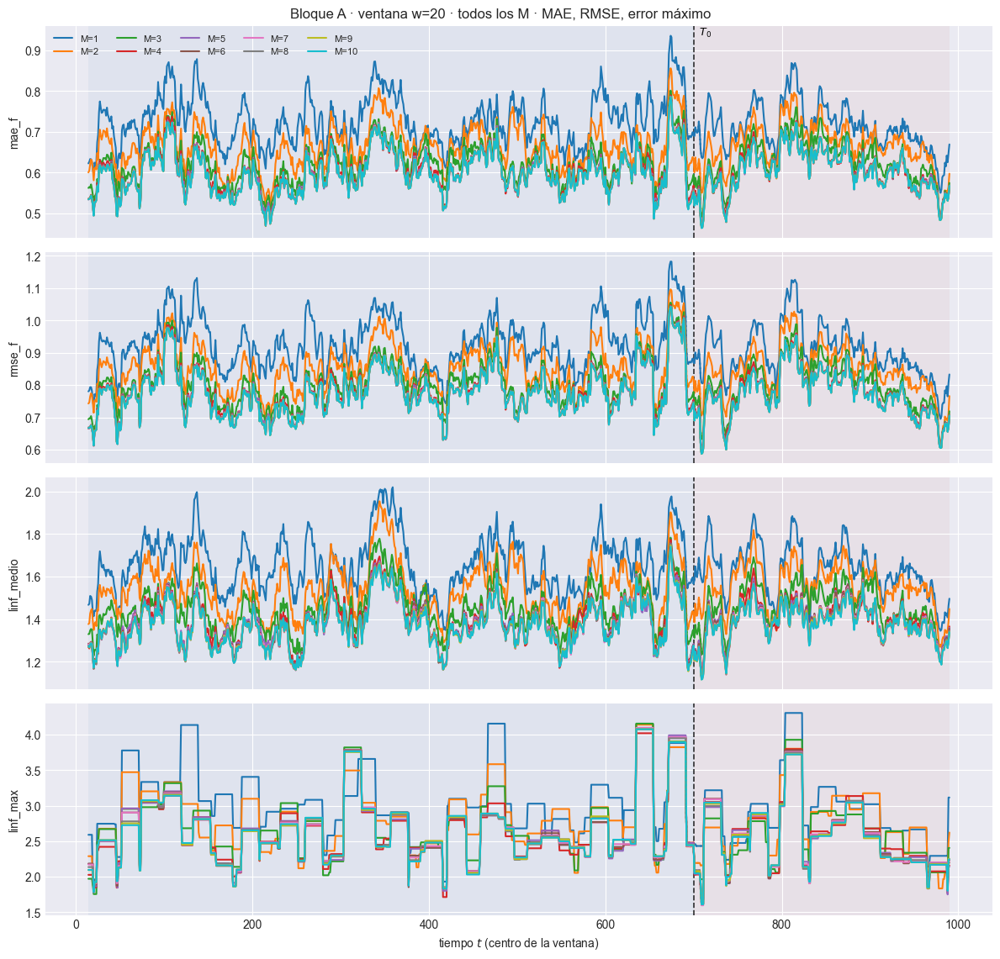

[plot_ventana_movil] inicio (4 pasos)
  1/4 (25.0%) t=0.3s eta=0.9s  mae_f: w=30 train=0.6121  w=30 test=0.6249
  2/4 (50.0%) t=0.4s eta=0.4s  rmse_f: w=30 train=0.792  w=30 test=0.8001
  3/4 (75.0%) t=0.6s eta=0.2s  linf_medio: w=30 train=1.411  w=30 test=1.427
  4/4 (100.0%) t=0.7s eta=0.0s  linf_max: w=30 train=2.815  w=30 test=2.782
[plot_ventana_movil] listo: 4 pasos en 2.1s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_barrido_M\85_bloqueA_w30.png


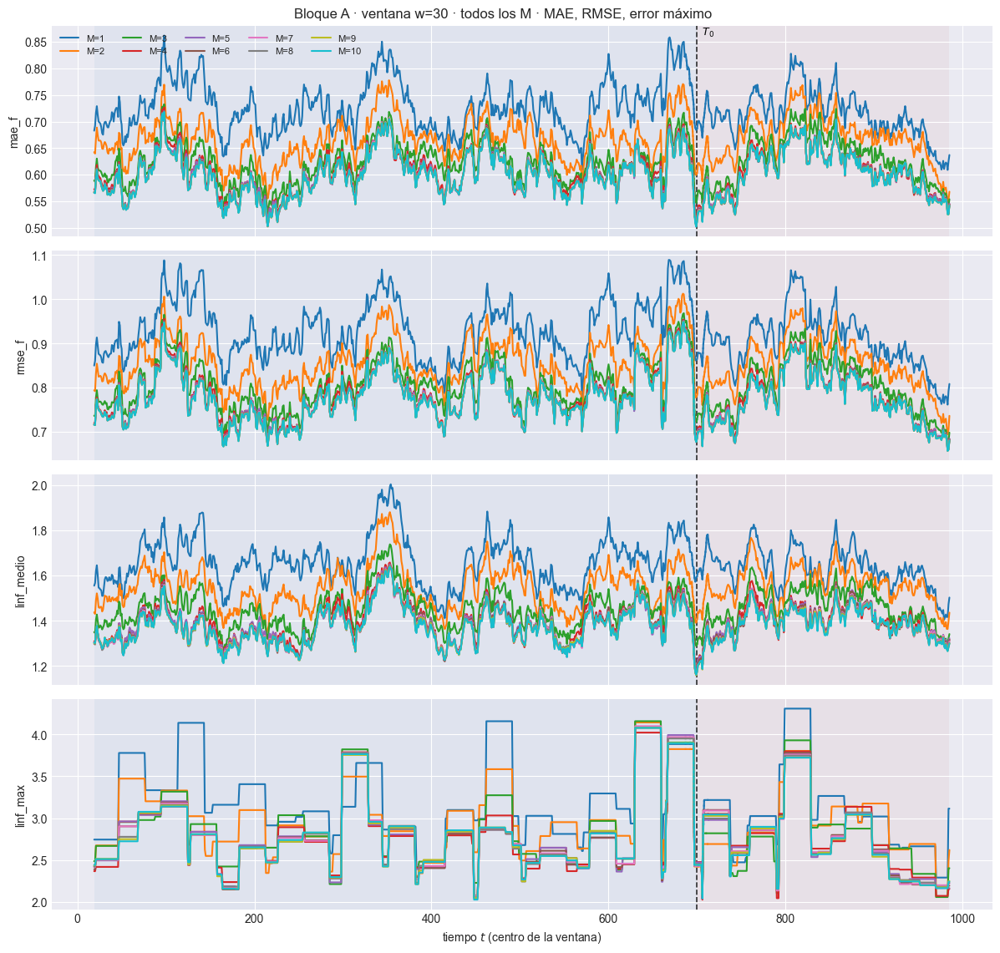

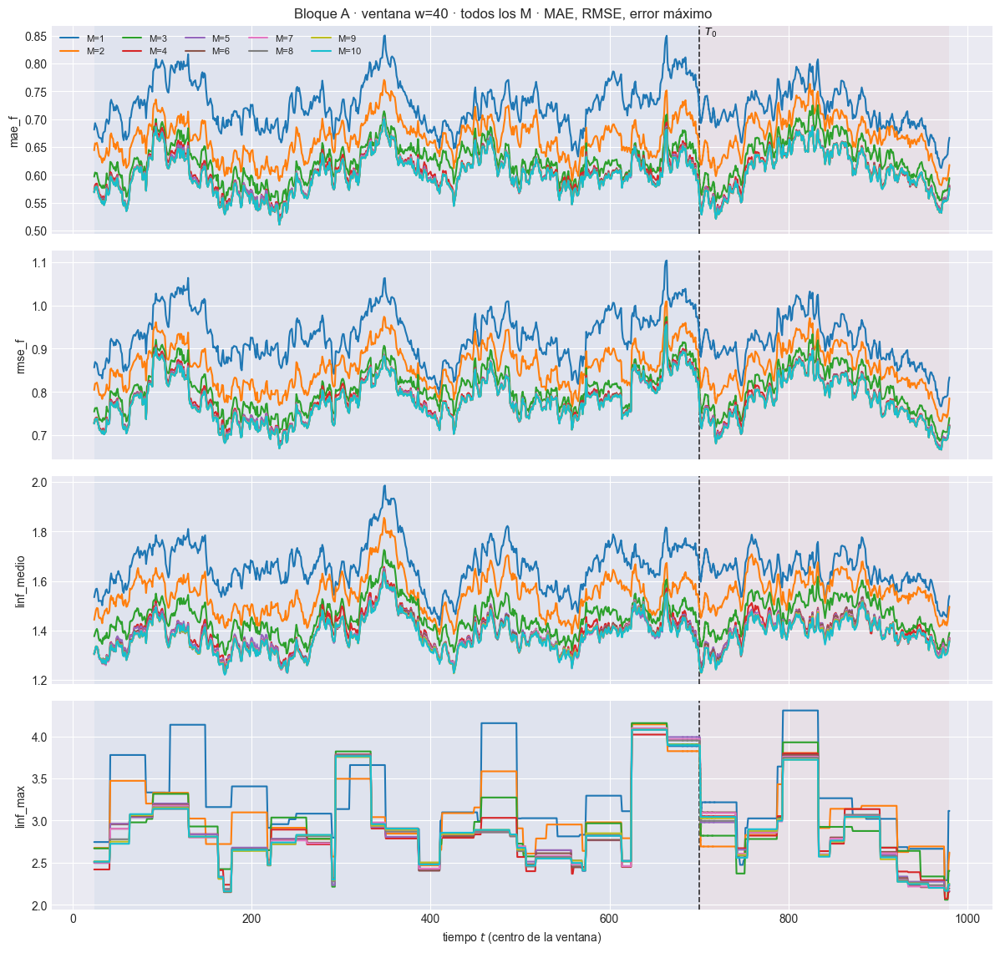

In [8]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?


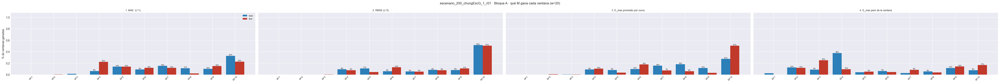

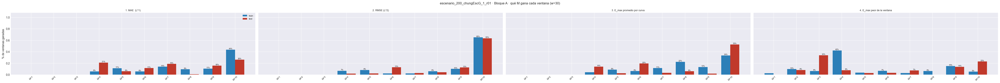

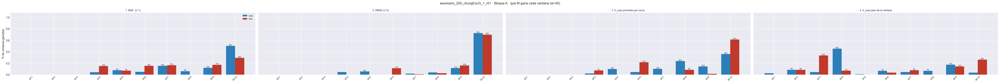

In [9]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

## 5. Bloque B: intervalos de predicción, en una sola vista

Cuatro cifras del intervalo, ninguna "primaria" en esta vista -el Winkler es
la única regla de puntuación propia y por eso es la que ordena modelos cuando
hace falta ordenar, pero aquí se muestran las cuatro juntas-:

| | qué es | de qué es |
|---|---|---|
| **Winkler** | interval score | penaliza ancho Y cobertura a la vez |
| **Cobertura simultánea** | de $w$ curvas, cuántas quedan COMPLETAS dentro de su banda (1/0 por curva) | fracción de CURVAS |
| **Cobertura puntual (PICP)** | de una curva, qué fracción de $\tau$ cae dentro | promedio de esa fracción sobre la ventana |
| **MPIW** | ancho medio de la banda | — |

La cobertura simultánea es SIEMPRE $\le$ la puntual: basta un $\tau$ fuera
para que la curva entera cuente como no cubierta.

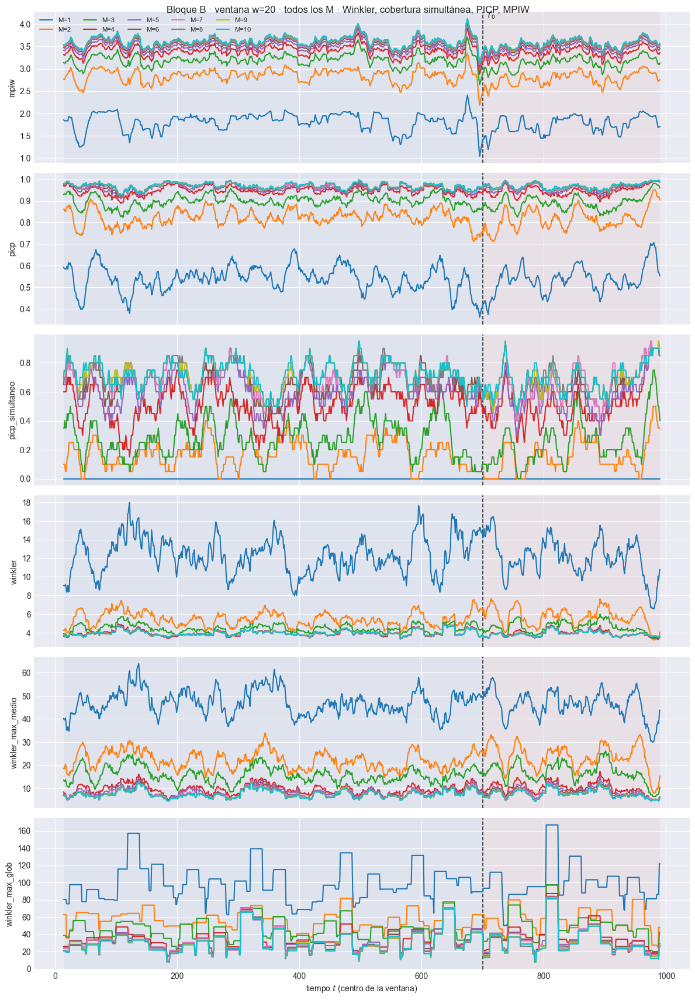

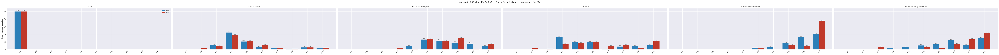

[plot_ventana_movil] inicio (6 pasos)
  1/6 (16.7%) t=0.0s eta=0.2s  mpiw: w=30 train=3.505  w=30 test=3.452
  2/6 (33.3%) t=0.1s eta=0.2s  picp: w=30 train=0.956  w=30 test=0.9547
  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0.6333  w=30 test=0.6
  4/6 (66.7%) t=0.2s eta=0.1s  winkler: w=30 train=4.086  w=30 test=3.982
  5/6 (83.3%) t=0.2s eta=0.0s  winkler_max_medio: w=30 train=8.926  w=30 test=9.308
  6/6 (100.0%) t=0.3s eta=0.0s  winkler_max_glob: w=30 train=40.11  w=30 test=42.44
[plot_ventana_movil] listo: 6 pasos en 1.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_barrido_M\86_bloqueB_w30.png


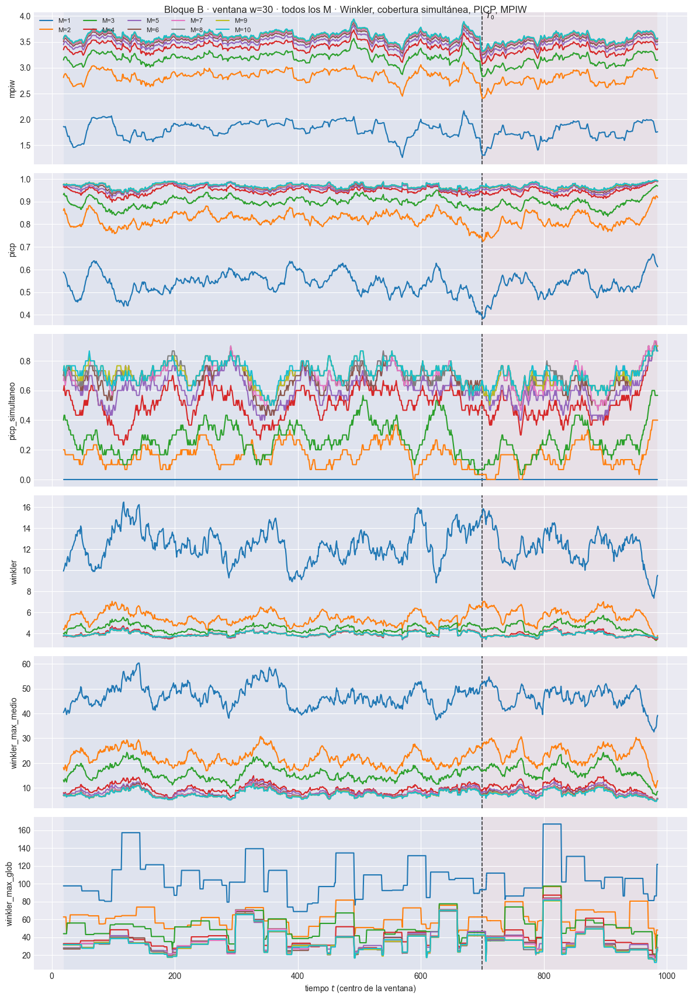

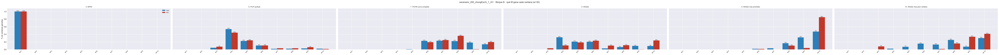

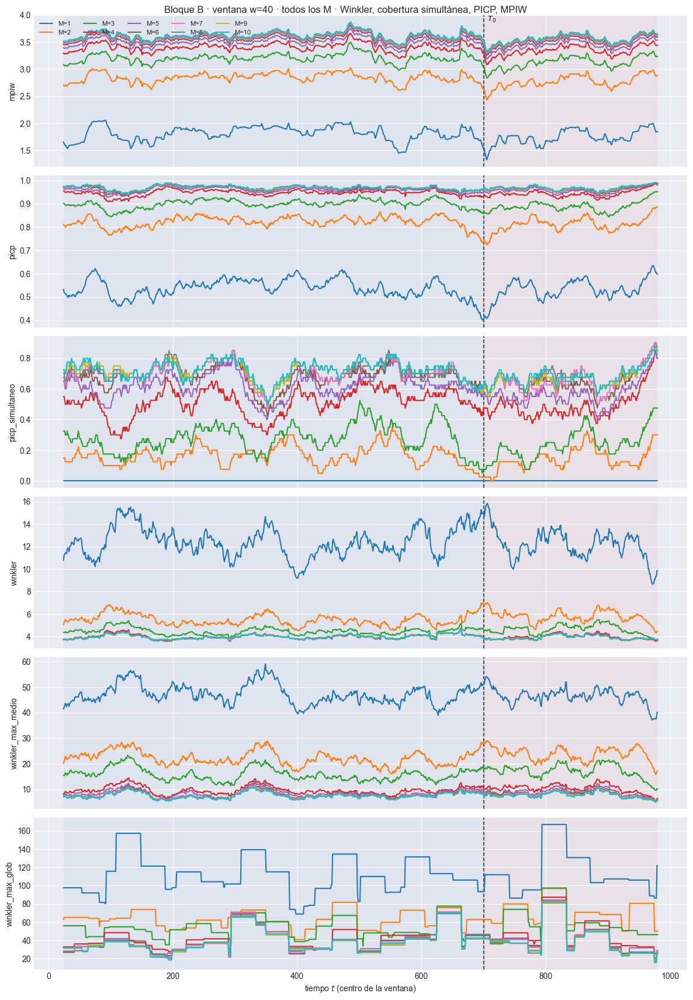

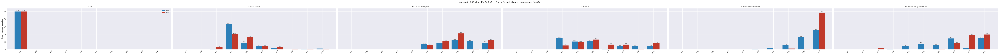

In [10]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

## 6. Muestra de predicciones

Dos vistas: un extracto regular del bloque de **prueba** (para no mezclar con
in-sample), y las ventanas con **peor** valor de `METRICA_PEORES` ([CONFIG]).
En la segunda se agrega la curva **anterior** ($t-1$, gris punteada): es el
primer diagnóstico de POR QUÉ el modelo se equivocó -¿la curva de partida ya
era atípica?-.

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.1s  t=701 [test] cob=0.413 rmse=0.5458
  2/10 (20.0%) t=0.0s eta=0.1s  t=731 [test] cob=0.627 rmse=0.4483
  3/10 (30.0%) t=0.0s eta=0.1s  t=761 [test] cob=0.533 rmse=1.107
  4/10 (40.0%) t=0.1s eta=0.1s  t=791 [test] cob=0.493 rmse=0.4522
  5/10 (50.0%) t=0.1s eta=0.1s  t=821 [test] cob=0.253 rmse=1.518
  6/10 (60.0%) t=0.1s eta=0.1s  t=851 [test] cob=0.707 rmse=0.8012
  7/10 (70.0%) t=0.1s eta=0.0s  t=881 [test] cob=0.853 rmse=0.4493
  8/10 (80.0%) t=0.1s eta=0.0s  t=911 [test] cob=0.520 rmse=0.6101
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.573 rmse=0.8893
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=0.893 rmse=0.5447
[plot_extractos_curvas] listo: 10 pasos en 1.8s  cob media train=nan test=0.587 (nominal 0.95)


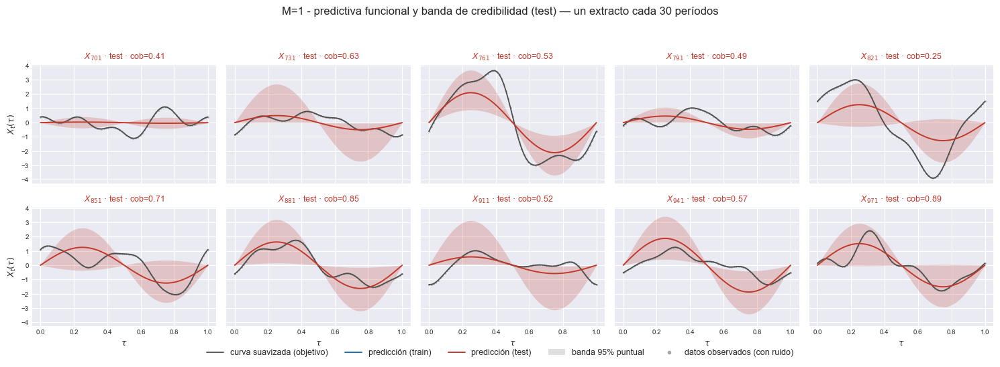

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=0.880 rmse=0.4594
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=0.907 rmse=0.337
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.680 rmse=1.183
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=0.733 rmse=0.5325
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.773 rmse=1.271
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.818
  7/10 (70.0%) t=0.0s eta=0.0s  t=881 [test] cob=1.000 rmse=0.3524
  8/10 (80.0%) t=0.1s eta=0.0s  t=911 [test] cob=0.787 rmse=0.7018
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.867 rmse=1.052
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=1.000 rmse=0.5586
[plot_extractos_curvas] listo: 10 pasos en 1.9s  cob media train=nan test=0.863 (nominal 0.95)


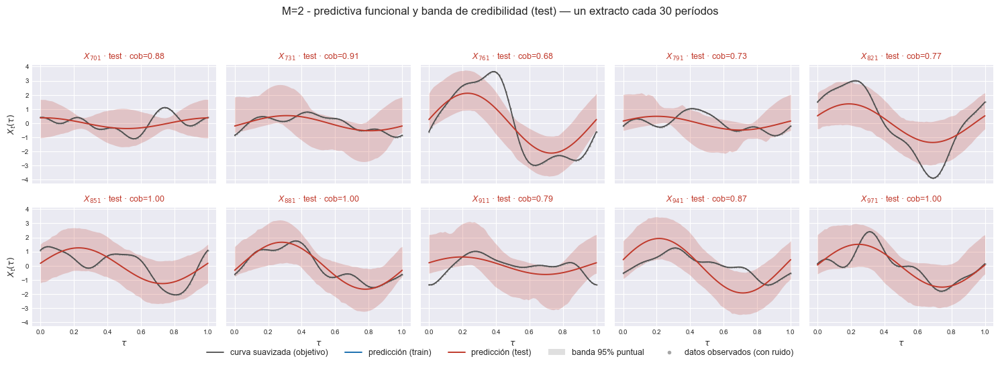

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=0.920 rmse=0.4609
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=0.933 rmse=0.3731
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.720 rmse=1.134
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=0.827 rmse=0.5756
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.787 rmse=1.259
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.7295
  7/10 (70.0%) t=0.0s eta=0.0s  t=881 [test] cob=1.000 rmse=0.3865
  8/10 (80.0%) t=0.1s eta=0.0s  t=911 [test] cob=0.840 rmse=0.7394
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.813 rmse=1.065
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=1.000 rmse=0.5277
[plot_extractos_curvas] listo: 10 pasos en 2.1s  cob media train=nan test=0.884 (nominal 0.95)


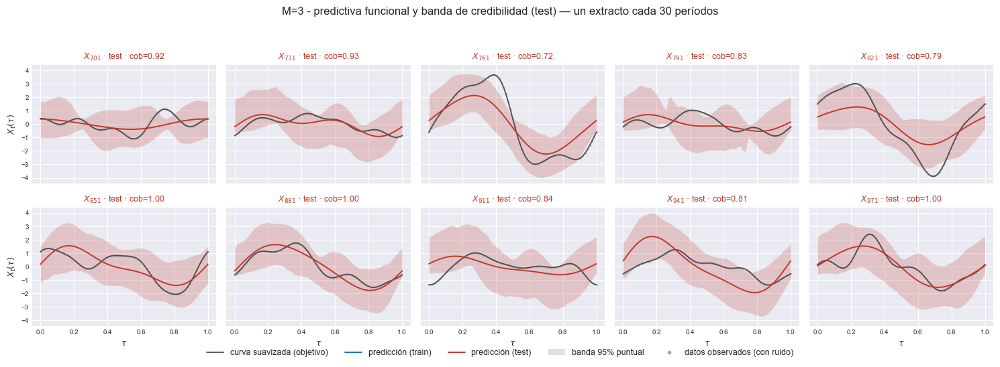

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=0.960 rmse=0.3777
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=1.000 rmse=0.3747
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.720 rmse=1.177
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=1.000 rmse=0.5512
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.800 rmse=1.259
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.5302
  7/10 (70.0%) t=0.0s eta=0.0s  t=881 [test] cob=1.000 rmse=0.3654
  8/10 (80.0%) t=0.0s eta=0.0s  t=911 [test] cob=0.880 rmse=0.6133
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.880 rmse=1.102
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=1.000 rmse=0.5335
[plot_extractos_curvas] listo: 10 pasos en 1.6s  cob media train=nan test=0.924 (nominal 0.95)


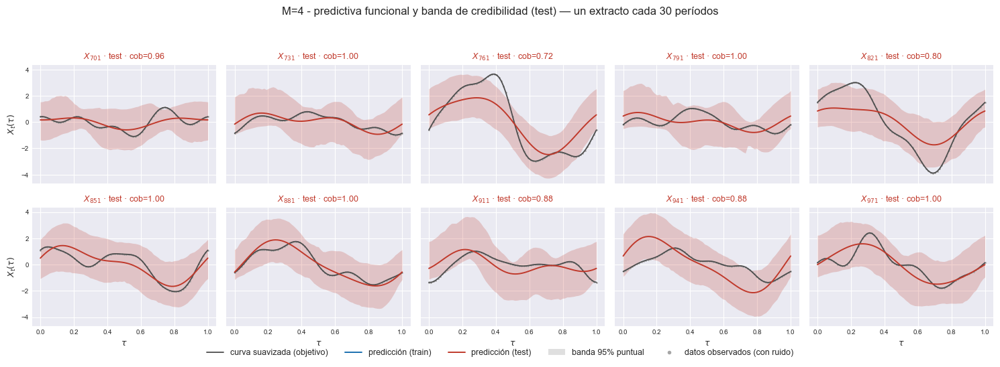

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3711
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=1.000 rmse=0.3742
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.773 rmse=1.108
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=1.000 rmse=0.6127
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.800 rmse=1.283
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.5286
  7/10 (70.0%) t=0.1s eta=0.0s  t=881 [test] cob=1.000 rmse=0.4039
  8/10 (80.0%) t=0.1s eta=0.0s  t=911 [test] cob=0.920 rmse=0.6074
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.893 rmse=1.101
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=1.000 rmse=0.5464
[plot_extractos_curvas] listo: 10 pasos en 1.7s  cob media train=nan test=0.939 (nominal 0.95)


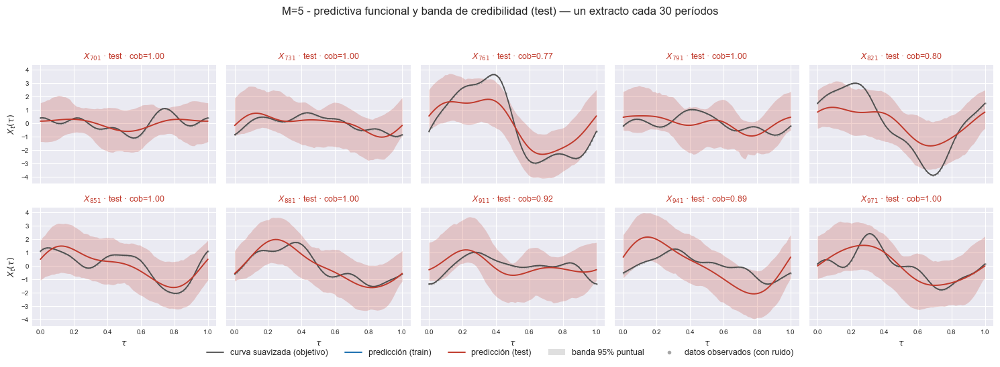

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.1s  t=701 [test] cob=1.000 rmse=0.37
  2/10 (20.0%) t=0.0s eta=0.1s  t=731 [test] cob=1.000 rmse=0.3625
  3/10 (30.0%) t=0.0s eta=0.1s  t=761 [test] cob=0.827 rmse=1.111
  4/10 (40.0%) t=0.0s eta=0.1s  t=791 [test] cob=1.000 rmse=0.6192
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.787 rmse=1.276
  6/10 (60.0%) t=0.1s eta=0.0s  t=851 [test] cob=1.000 rmse=0.5333
  7/10 (70.0%) t=0.1s eta=0.0s  t=881 [test] cob=1.000 rmse=0.3957
  8/10 (80.0%) t=0.1s eta=0.0s  t=911 [test] cob=0.933 rmse=0.6072
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.907 rmse=1.104
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=1.000 rmse=0.5317
[plot_extractos_curvas] listo: 10 pasos en 2.3s  cob media train=nan test=0.945 (nominal 0.95)


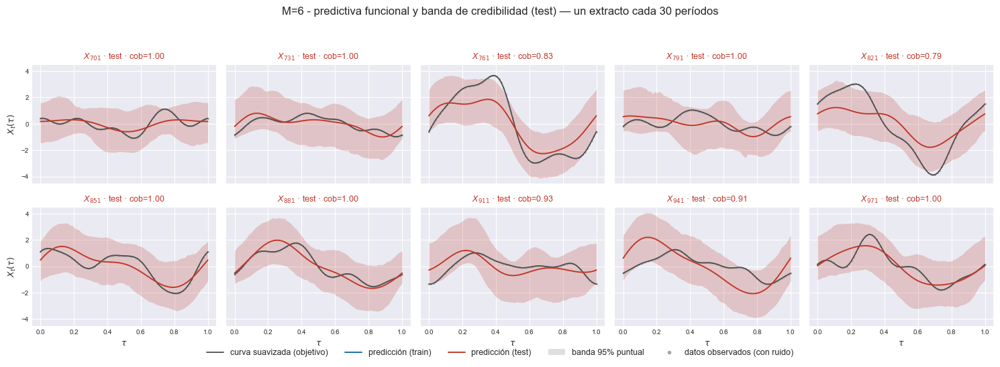

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.366
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=1.000 rmse=0.3618
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.827 rmse=1.111
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=1.000 rmse=0.6135
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.800 rmse=1.269
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.5336
  7/10 (70.0%) t=0.1s eta=0.0s  t=881 [test] cob=1.000 rmse=0.3893
  8/10 (80.0%) t=0.1s eta=0.0s  t=911 [test] cob=0.933 rmse=0.6074
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.920 rmse=1.106
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=1.000 rmse=0.5457
[plot_extractos_curvas] listo: 10 pasos en 1.7s  cob media train=nan test=0.948 (nominal 0.95)


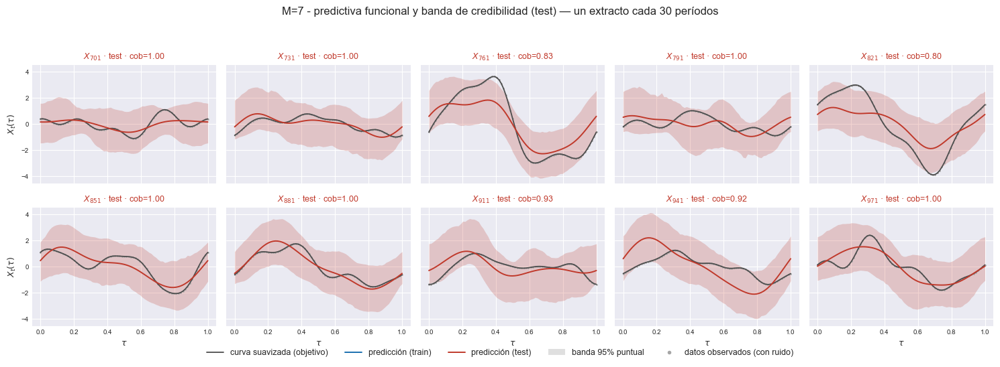

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3565
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=1.000 rmse=0.359
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.840 rmse=1.11
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=1.000 rmse=0.6135
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.813 rmse=1.269
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.5353
  7/10 (70.0%) t=0.1s eta=0.0s  t=881 [test] cob=1.000 rmse=0.387
  8/10 (80.0%) t=0.1s eta=0.0s  t=911 [test] cob=0.947 rmse=0.6072
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.907 rmse=1.107
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=1.000 rmse=0.549
[plot_extractos_curvas] listo: 10 pasos en 2.0s  cob media train=nan test=0.951 (nominal 0.95)


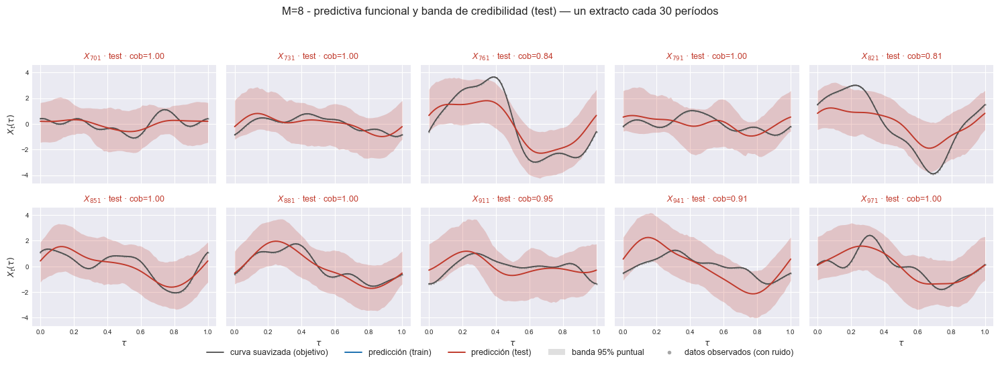

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3549
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=1.000 rmse=0.3576
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.827 rmse=1.111
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=1.000 rmse=0.6132
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.813 rmse=1.27
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.5356
  7/10 (70.0%) t=0.0s eta=0.0s  t=881 [test] cob=1.000 rmse=0.3866
  8/10 (80.0%) t=0.1s eta=0.0s  t=911 [test] cob=0.933 rmse=0.6063
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.907 rmse=1.106
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=1.000 rmse=0.5522
[plot_extractos_curvas] listo: 10 pasos en 1.9s  cob media train=nan test=0.948 (nominal 0.95)


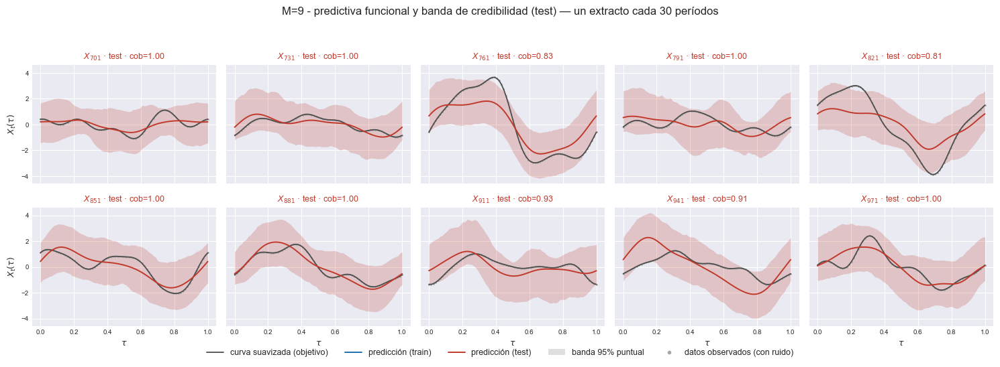

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3545
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=1.000 rmse=0.3576
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.827 rmse=1.111
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=1.000 rmse=0.6132
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.827 rmse=1.27
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.5329
  7/10 (70.0%) t=0.0s eta=0.0s  t=881 [test] cob=1.000 rmse=0.3864
  8/10 (80.0%) t=0.1s eta=0.0s  t=911 [test] cob=0.973 rmse=0.6039
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.907 rmse=1.106
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=1.000 rmse=0.5526
[plot_extractos_curvas] listo: 10 pasos en 1.6s  cob media train=nan test=0.953 (nominal 0.95)


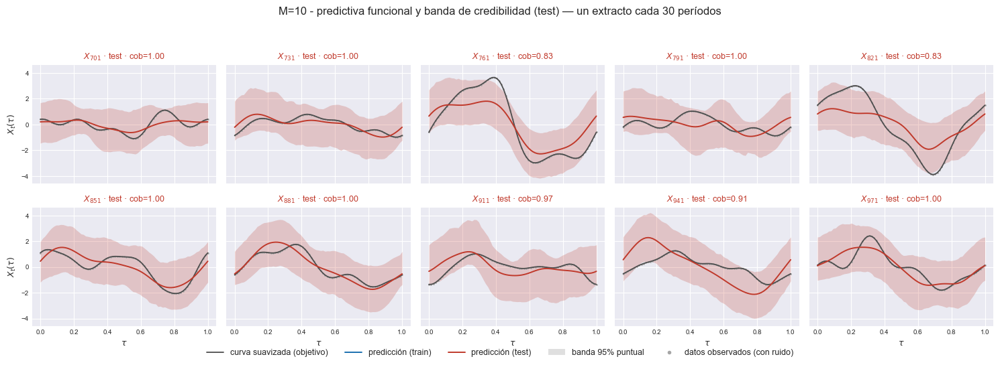

In [11]:
# Extractos regulares, SOLO del bloque de prueba.
mask_test = ~es_train
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[mask_test], e["X_pred"][mask_test], e["li_f"][mask_test], e["ls_f"][mask_test],
        grilla, T0, t=t_orig[mask_test], cada=CADA, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[mask_test],
        title=f"M={M} - predictiva funcional y banda de credibilidad (test)",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=0.493 rmse=1.158
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.520 rmse=1.595
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.707 rmse=0.8517
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.133 rmse=0.7641
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.413 rmse=0.5458
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.147 rmse=1.192
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.320 rmse=0.601
[plot_extractos_curvas] listo: 7 pasos en 1.1s  cob media train=0.463 test=0.293 (nominal 0.95)


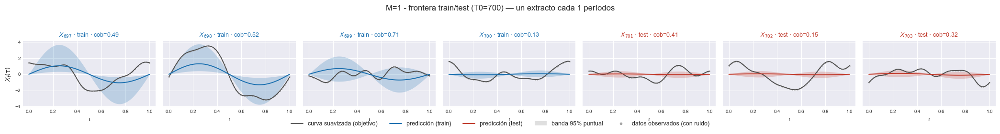

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=0.973 rmse=0.9477
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.880 rmse=1.604
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.840 rmse=0.9079
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.800 rmse=0.6433
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.880 rmse=0.4594
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.800 rmse=0.8265
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=0.867 rmse=0.4658
[plot_extractos_curvas] listo: 7 pasos en 1.2s  cob media train=0.873 test=0.849 (nominal 0.95)


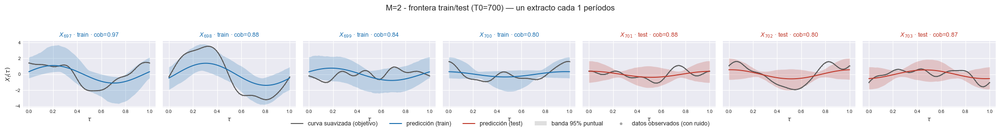

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9432
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.920 rmse=1.6
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.907 rmse=0.9205
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=0.880 rmse=0.6218
  5/7 (71.4%) t=0.3s eta=0.1s  t=701 [test] cob=0.920 rmse=0.4609
  6/7 (85.7%) t=0.3s eta=0.1s  t=702 [test] cob=0.773 rmse=0.8901
  7/7 (100.0%) t=0.3s eta=0.0s  t=703 [test] cob=0.907 rmse=0.4638
[plot_extractos_curvas] listo: 7 pasos en 1.5s  cob media train=0.927 test=0.867 (nominal 0.95)


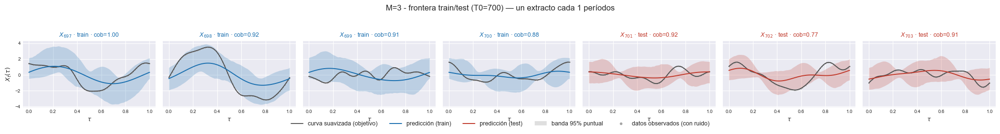

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9442
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.947 rmse=1.595
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.920 rmse=0.9301
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5804
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.960 rmse=0.3777
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.880 rmse=0.8528
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3575
[plot_extractos_curvas] listo: 7 pasos en 1.1s  cob media train=0.967 test=0.947 (nominal 0.95)


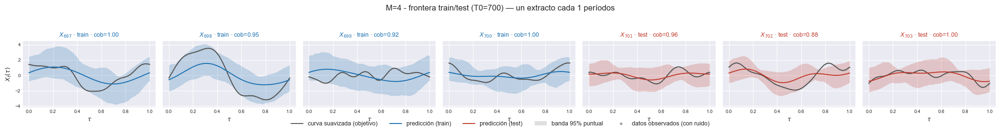

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9513
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.597
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9343
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5803
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3711
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8382
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3155
[plot_extractos_curvas] listo: 7 pasos en 1.0s  cob media train=0.967 test=0.973 (nominal 0.95)


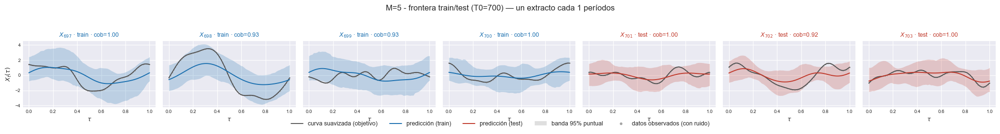

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9503
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.594
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9324
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5785
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.37
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8393
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3078
[plot_extractos_curvas] listo: 7 pasos en 1.1s  cob media train=0.967 test=0.973 (nominal 0.95)


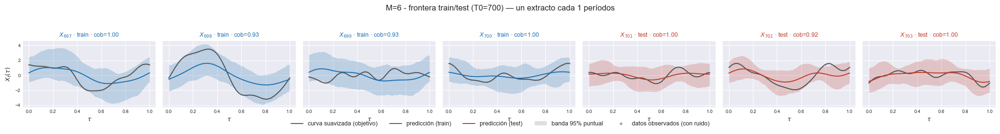

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9503
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.594
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9306
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5757
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.366
  6/7 (85.7%) t=0.5s eta=0.1s  t=702 [test] cob=0.920 rmse=0.8441
  7/7 (100.0%) t=0.5s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3091
[plot_extractos_curvas] listo: 7 pasos en 1.8s  cob media train=0.967 test=0.973 (nominal 0.95)


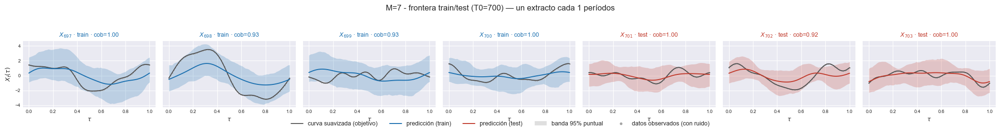

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9501
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.594
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9342
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5705
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3565
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8433
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.3083
[plot_extractos_curvas] listo: 7 pasos en 1.3s  cob media train=0.967 test=0.973 (nominal 0.95)


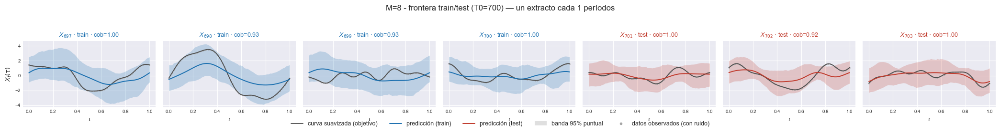

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9502
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.933 rmse=1.595
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9342
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5668
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3549
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8426
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.2985
[plot_extractos_curvas] listo: 7 pasos en 1.4s  cob media train=0.967 test=0.973 (nominal 0.95)


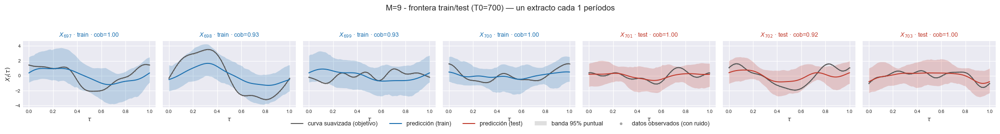

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.9497
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.947 rmse=1.594
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.933 rmse=0.9315
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.5723
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=1.000 rmse=0.3545
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.8426
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.2997
[plot_extractos_curvas] listo: 7 pasos en 1.4s  cob media train=0.970 test=0.973 (nominal 0.95)


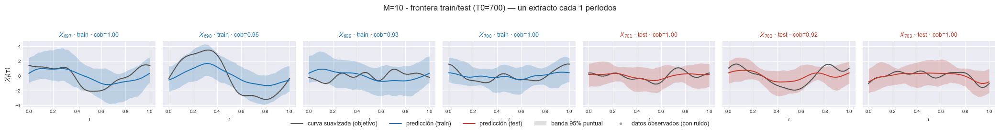

In [12]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=1] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[792, 821]  rmse_f=1.065713


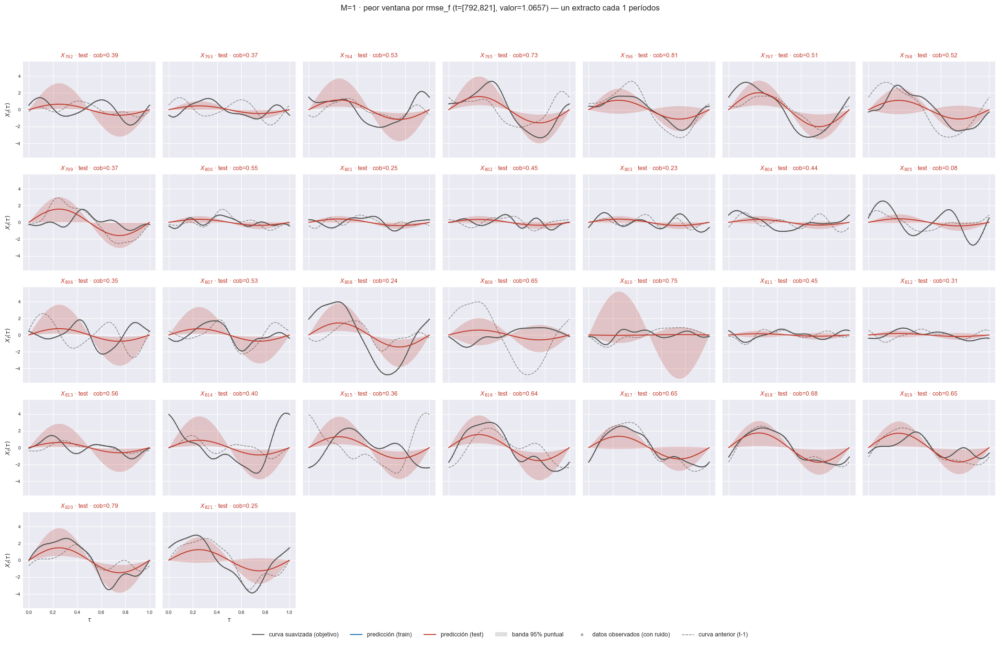

    t=[797, 826]  rmse_f=1.063117


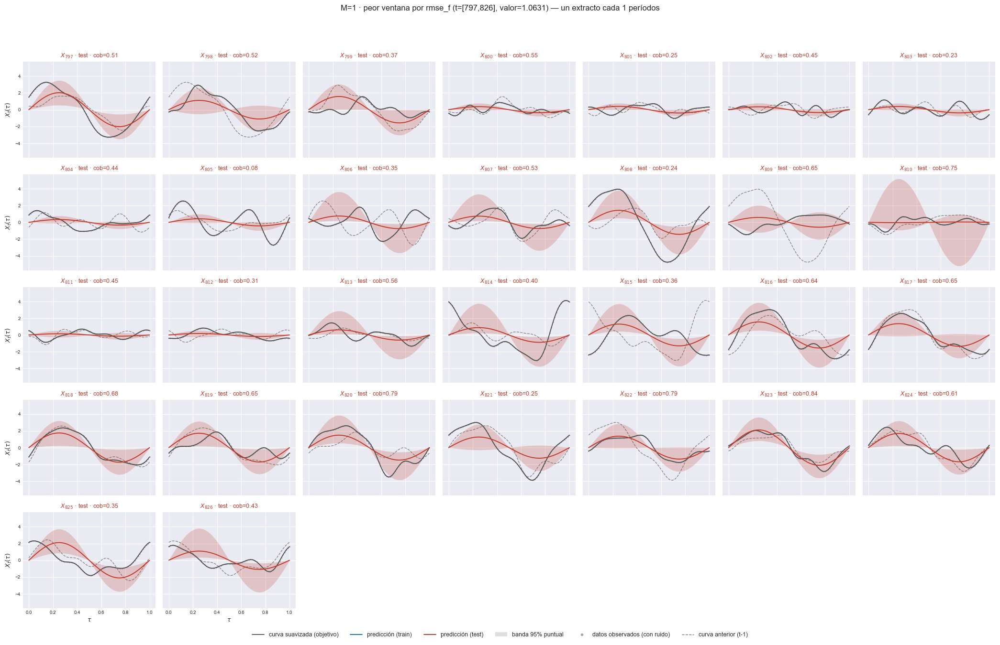

    t=[796, 825]  rmse_f=1.053609


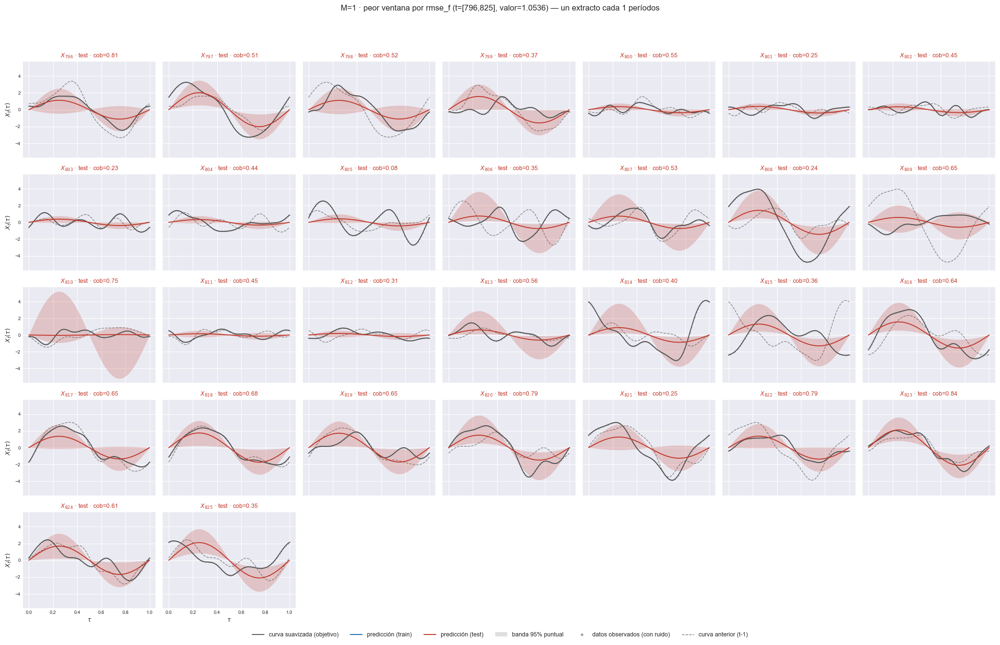

    t=[793, 822]  rmse_f=1.053342


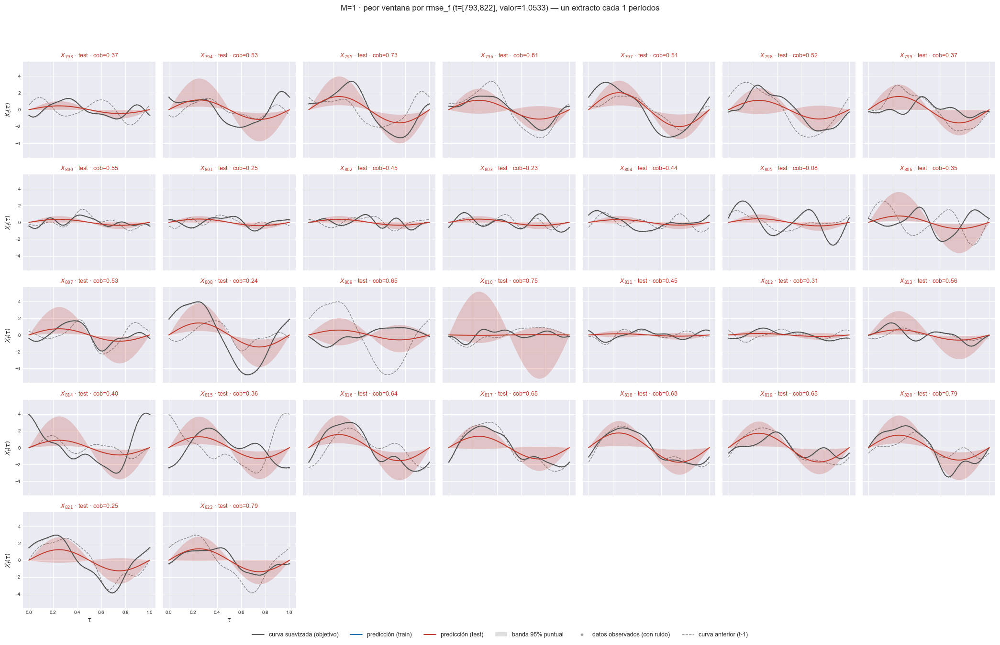

    t=[803, 832]  rmse_f=1.051537


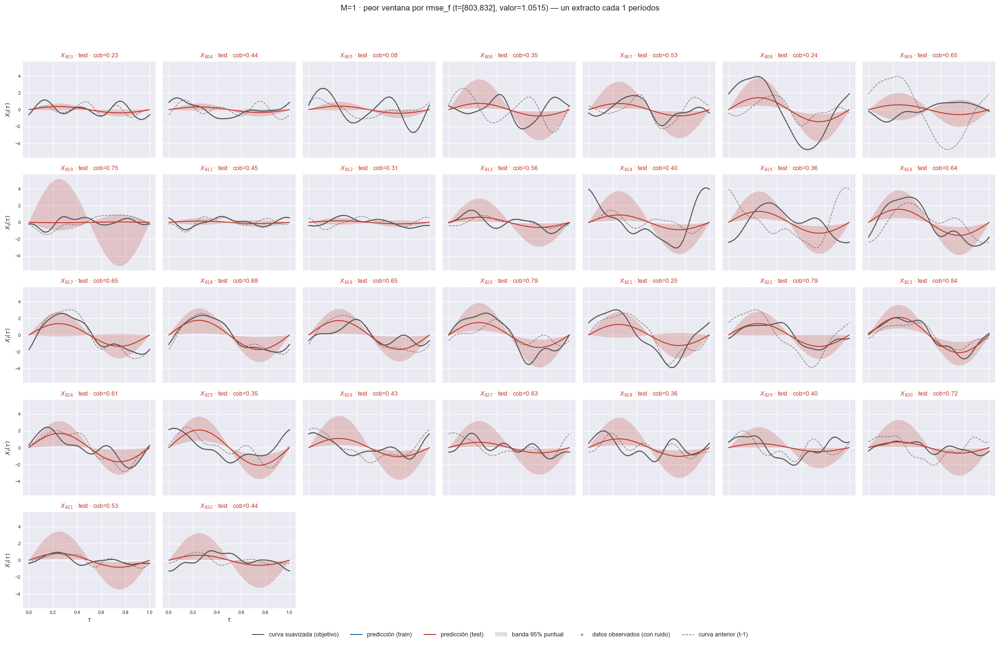

[M=2] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[805, 834]  rmse_f=0.979807


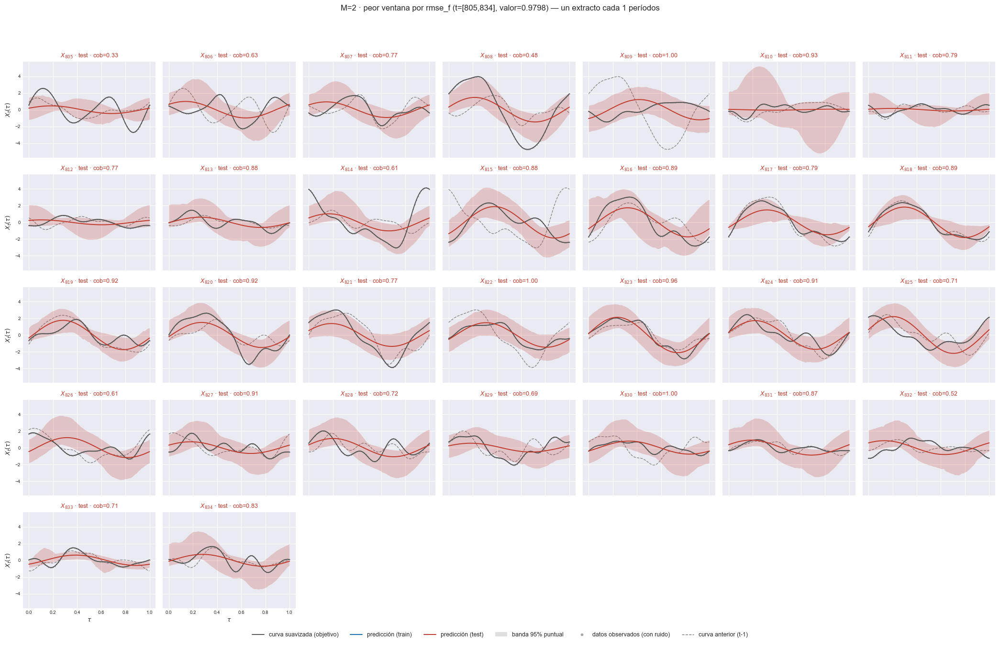

    t=[803, 832]  rmse_f=0.978621


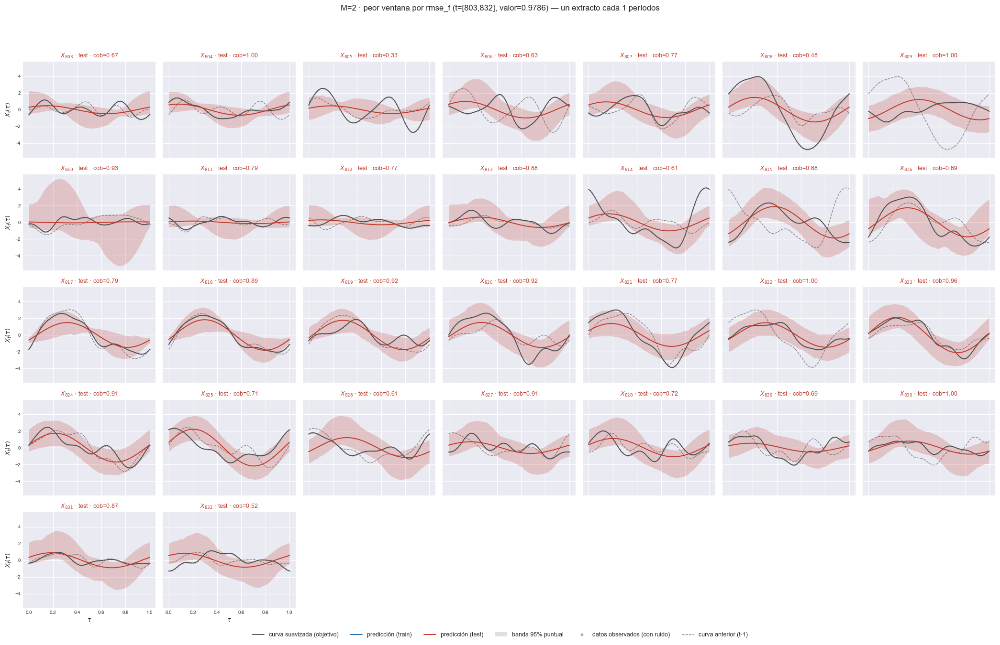

    t=[792, 821]  rmse_f=0.976242


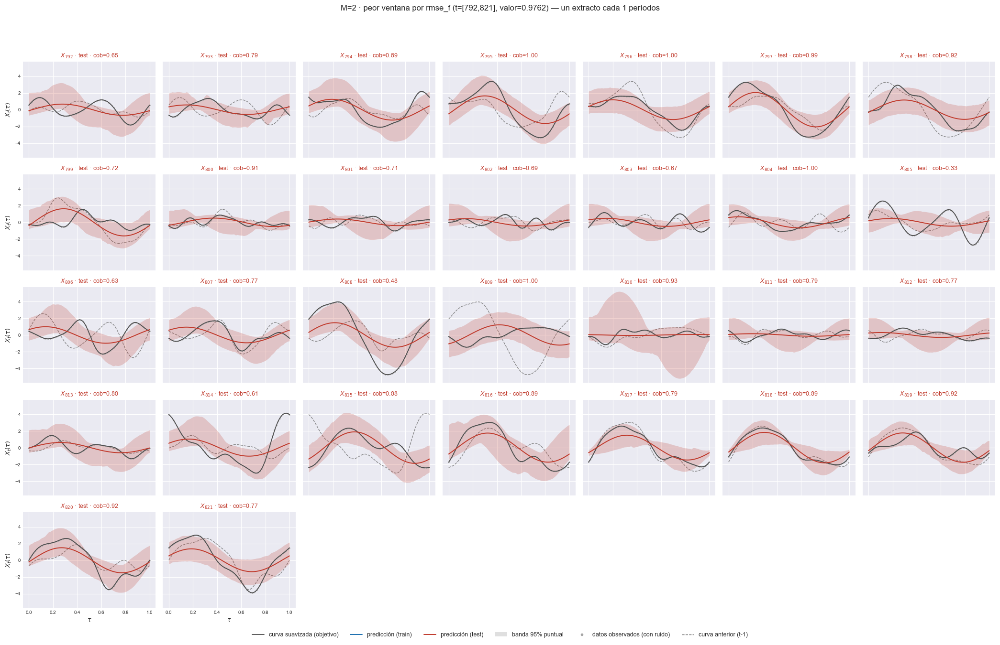

    t=[797, 826]  rmse_f=0.974865


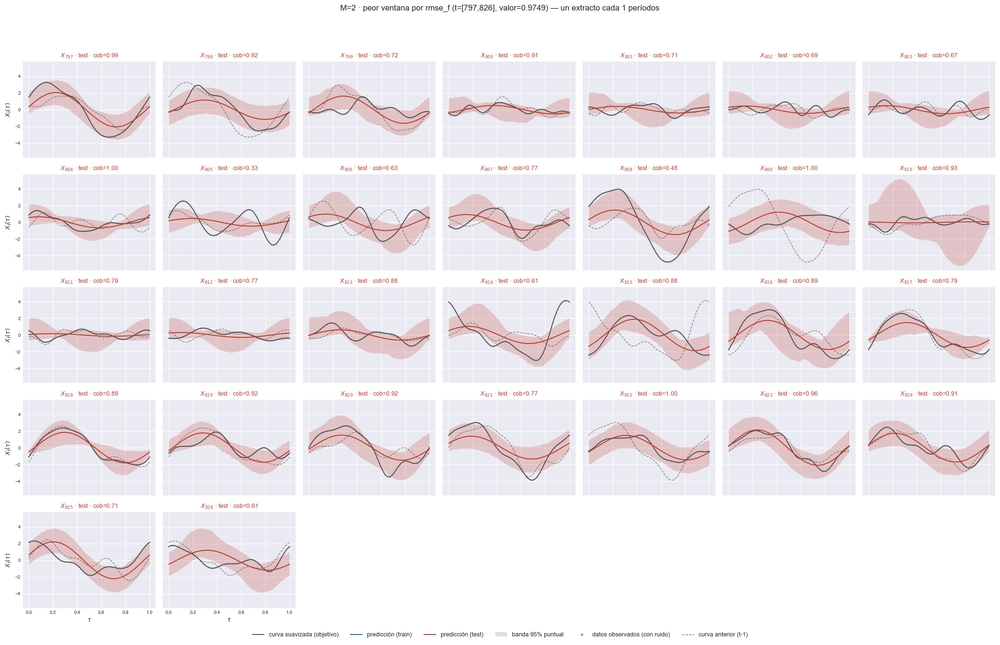

    t=[804, 833]  rmse_f=0.974704


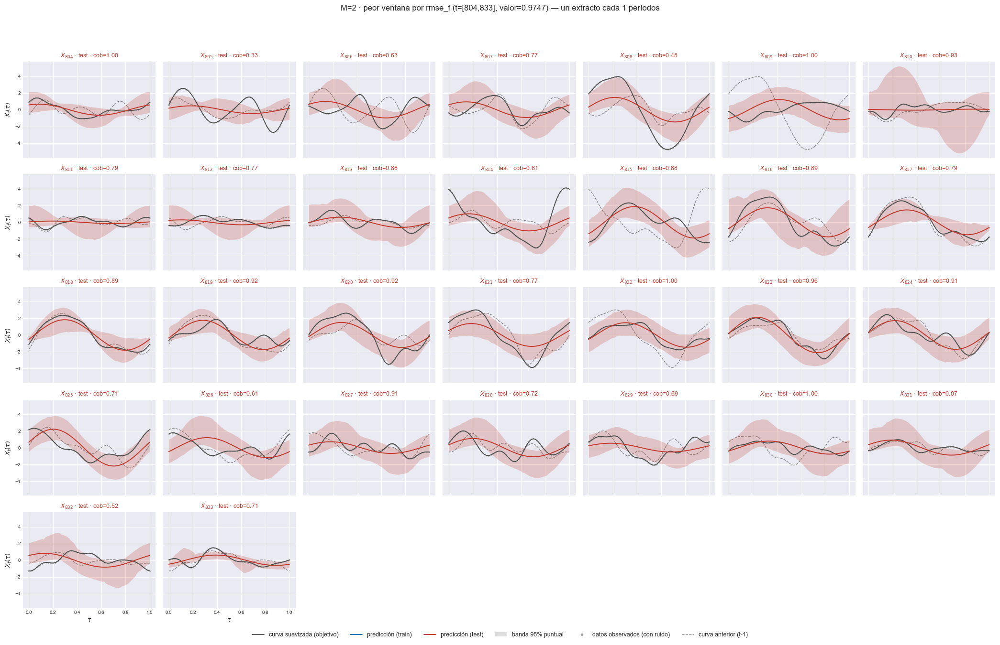

[M=3] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.933399


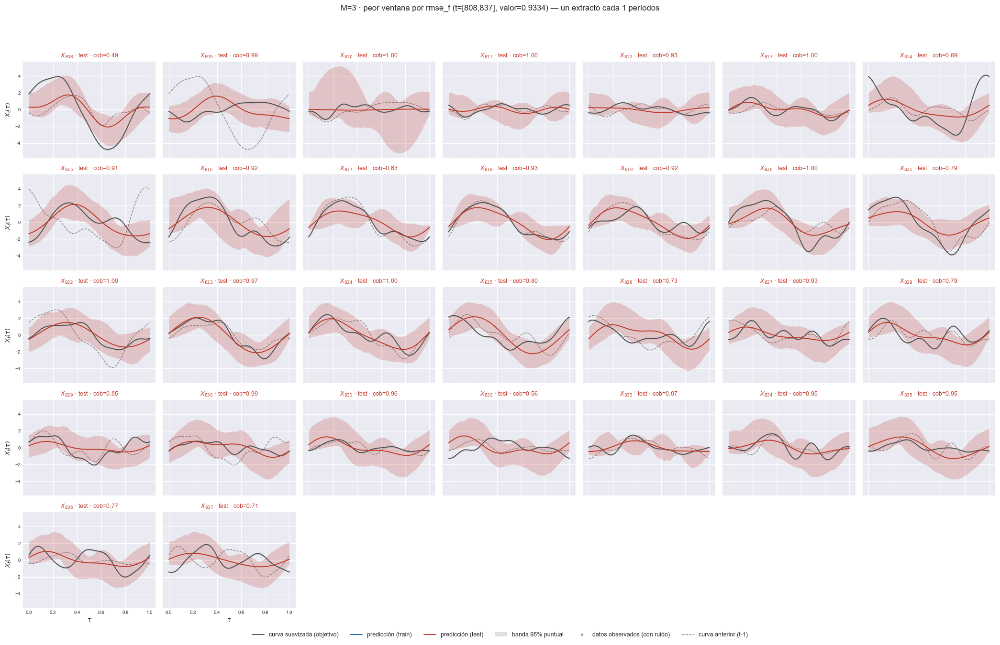

    t=[843, 872]  rmse_f=0.928352


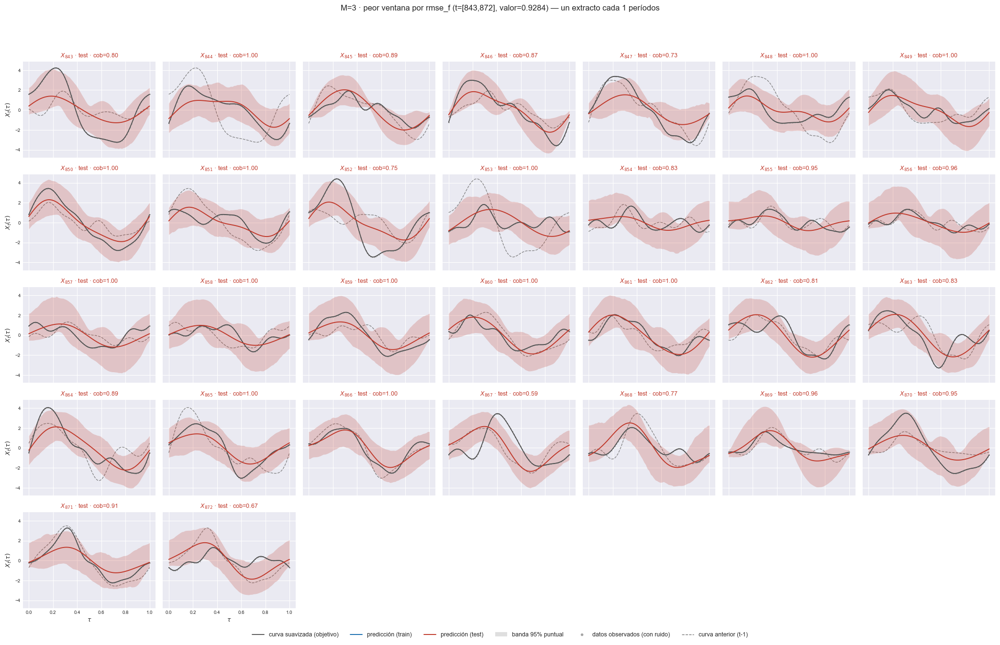

    t=[792, 821]  rmse_f=0.926214


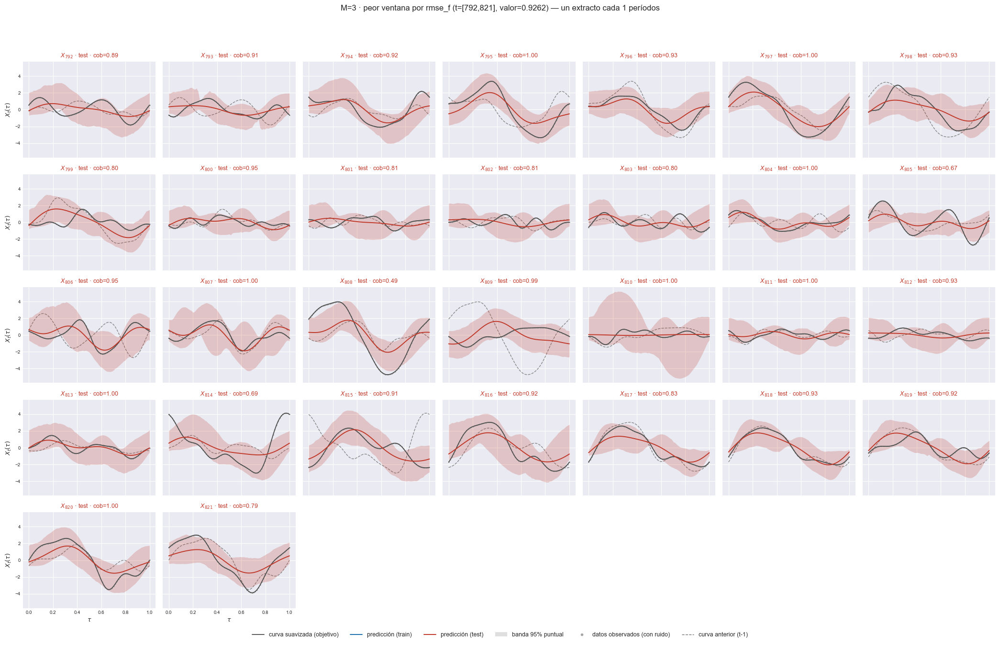

    t=[805, 834]  rmse_f=0.926038


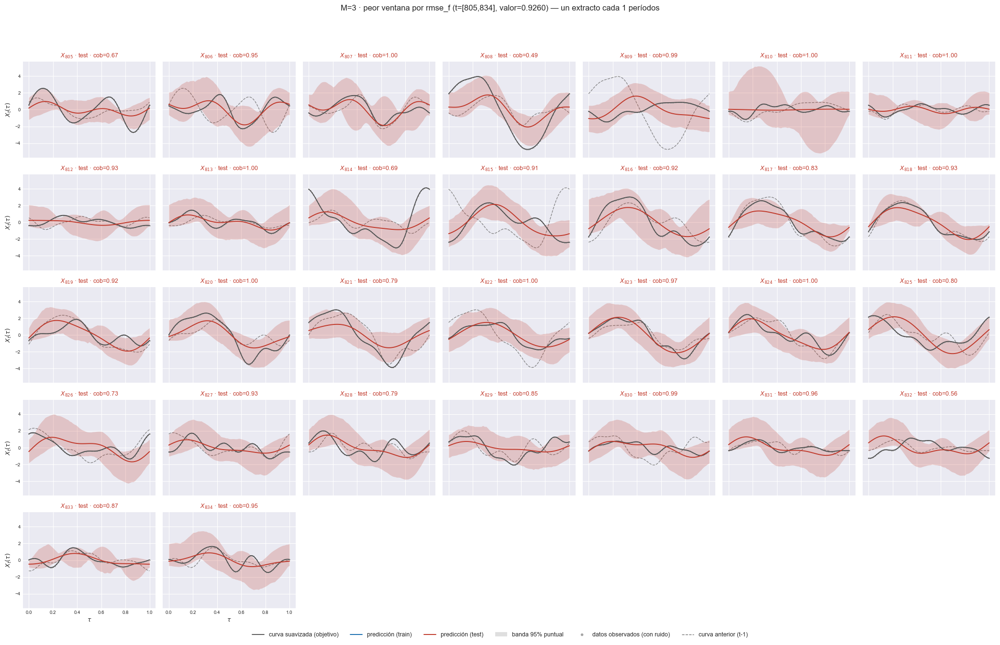

    t=[797, 826]  rmse_f=0.925597


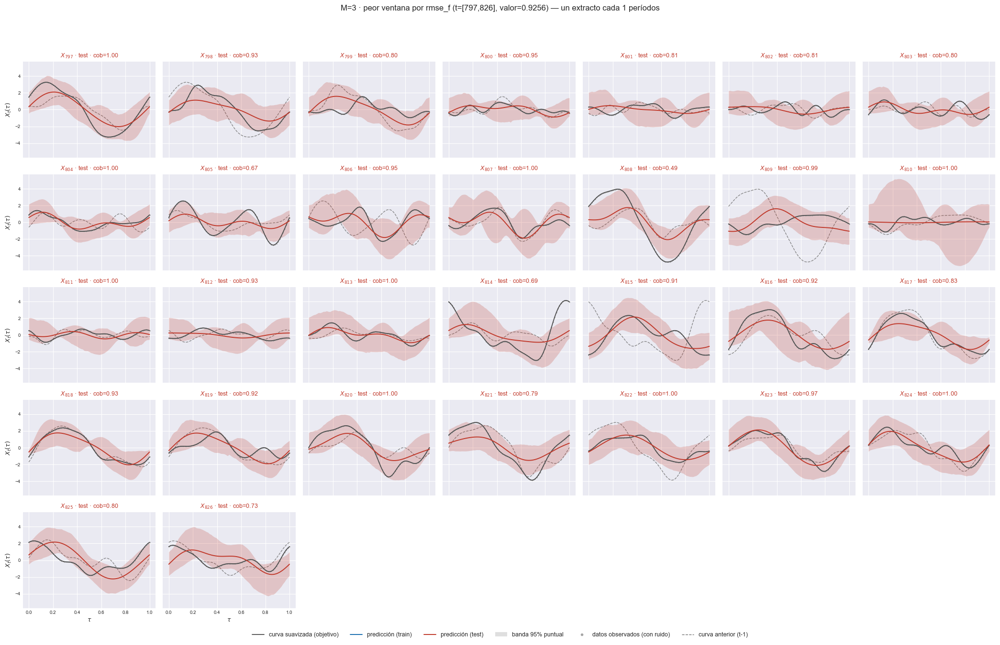

[M=4] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.905095


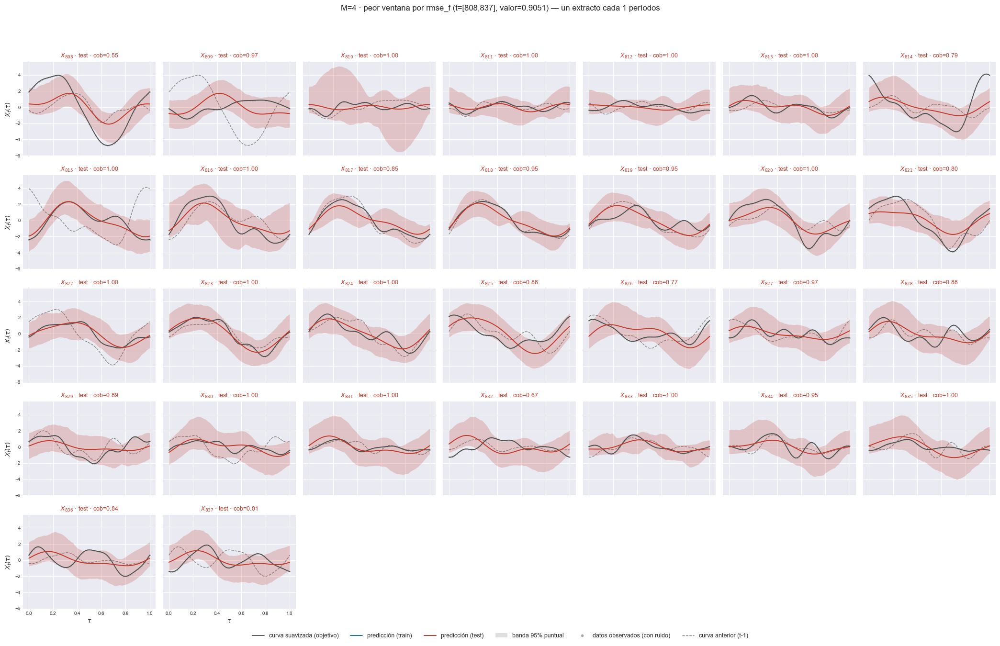

    t=[797, 826]  rmse_f=0.903781


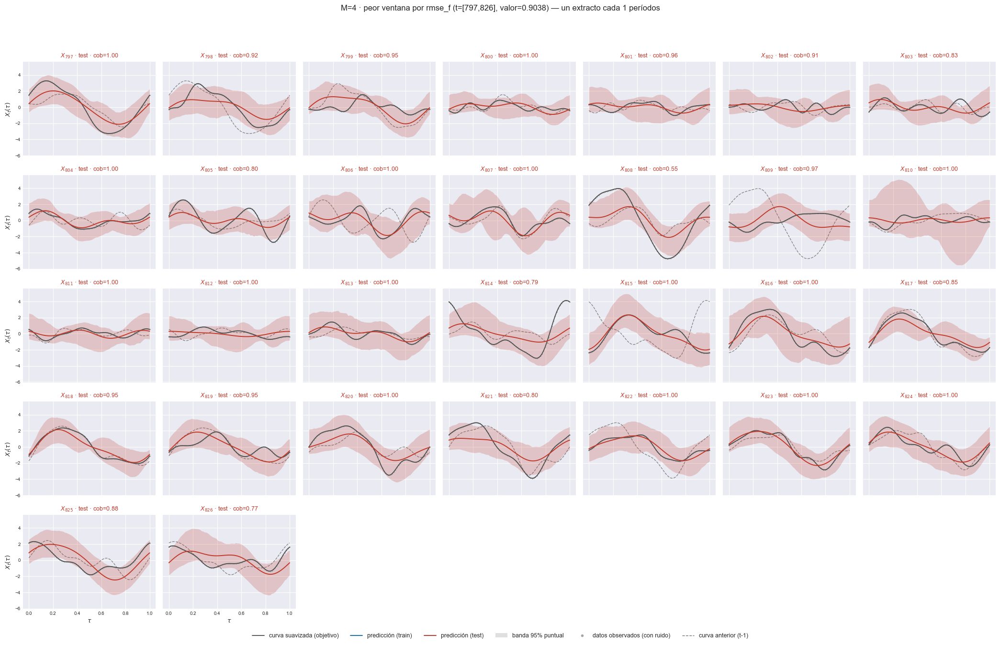

    t=[792, 821]  rmse_f=0.903270


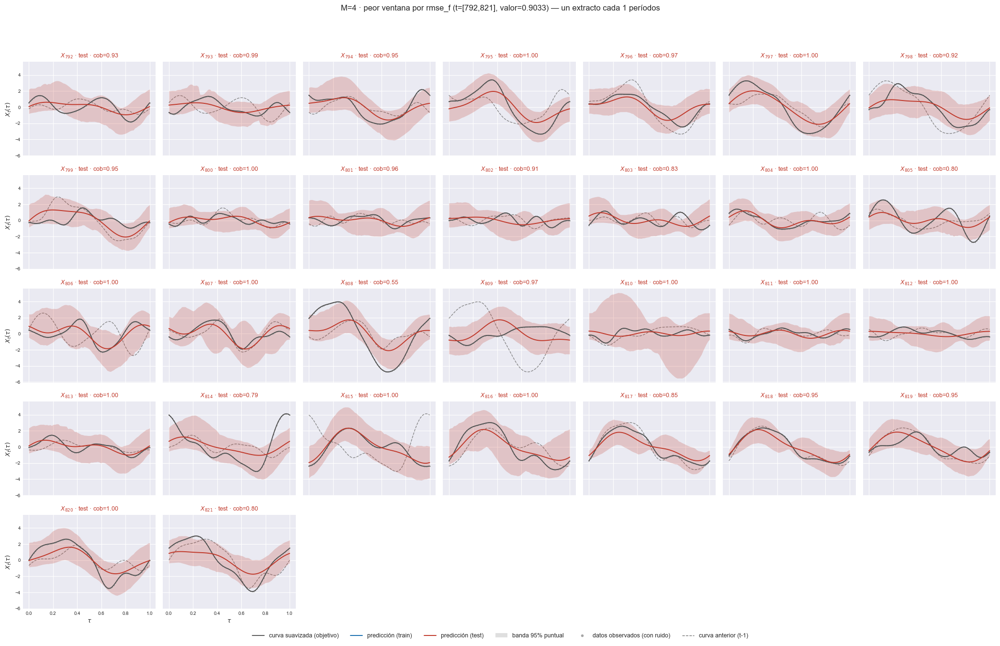

    t=[803, 832]  rmse_f=0.903241


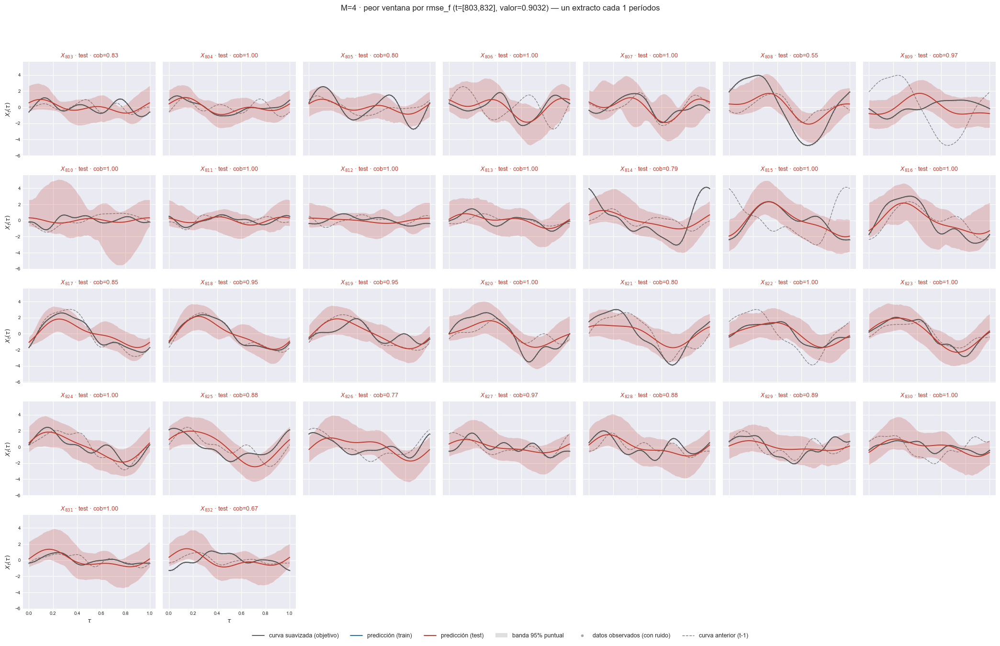

    t=[805, 834]  rmse_f=0.902241


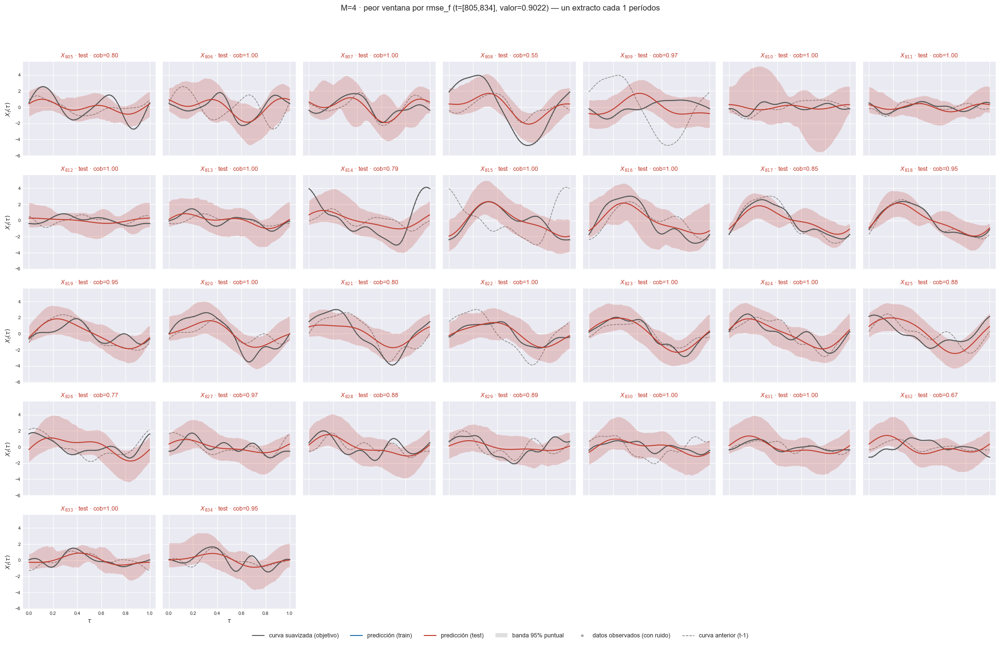

[M=5] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.904085


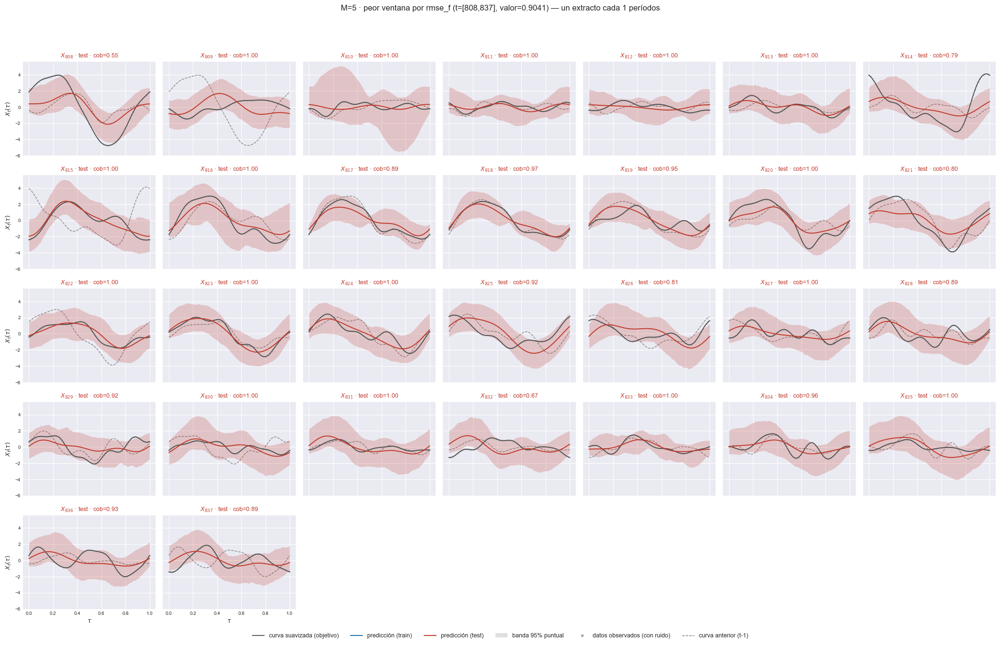

    t=[797, 826]  rmse_f=0.900681


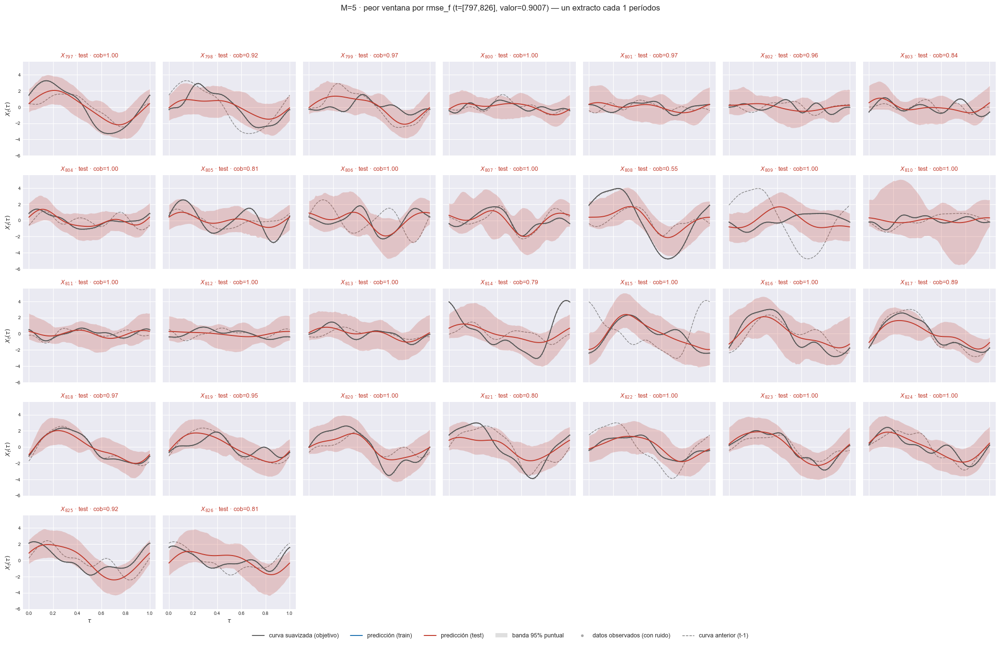

    t=[792, 821]  rmse_f=0.900148


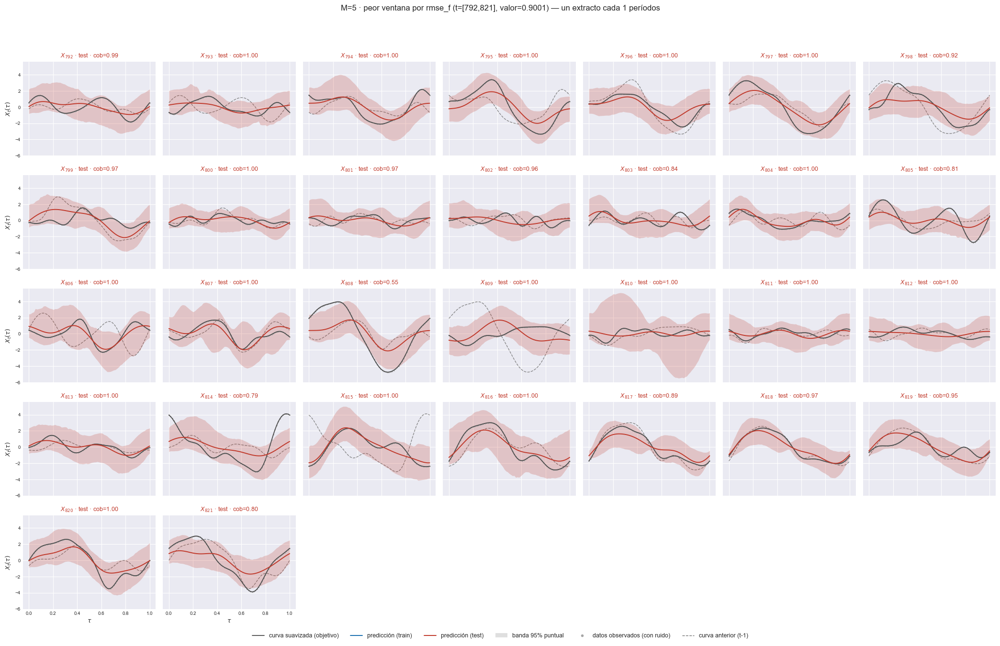

    t=[805, 834]  rmse_f=0.899927


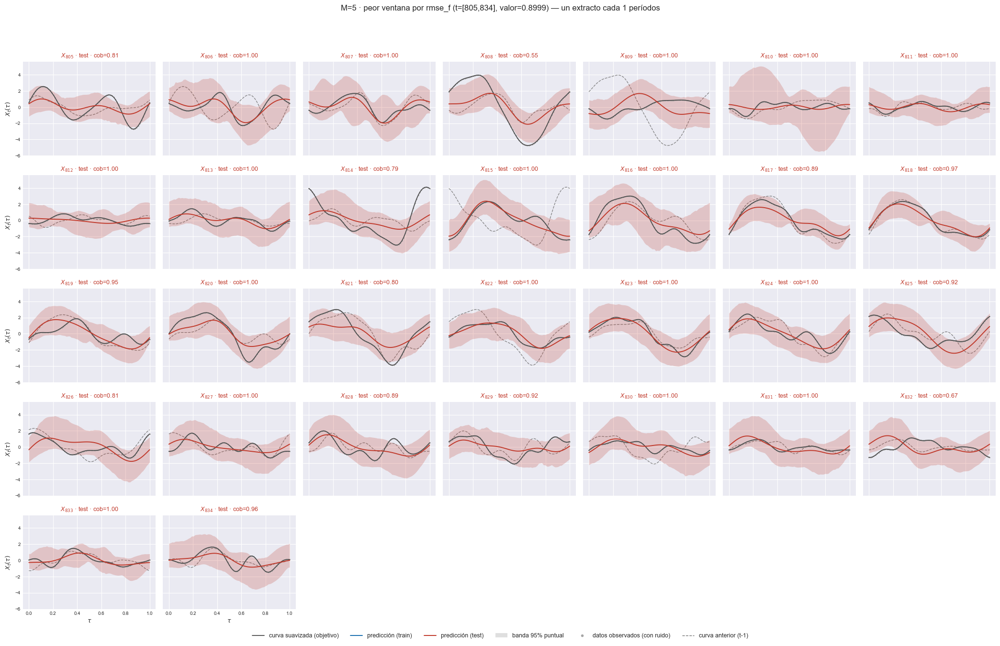

    t=[803, 832]  rmse_f=0.899779


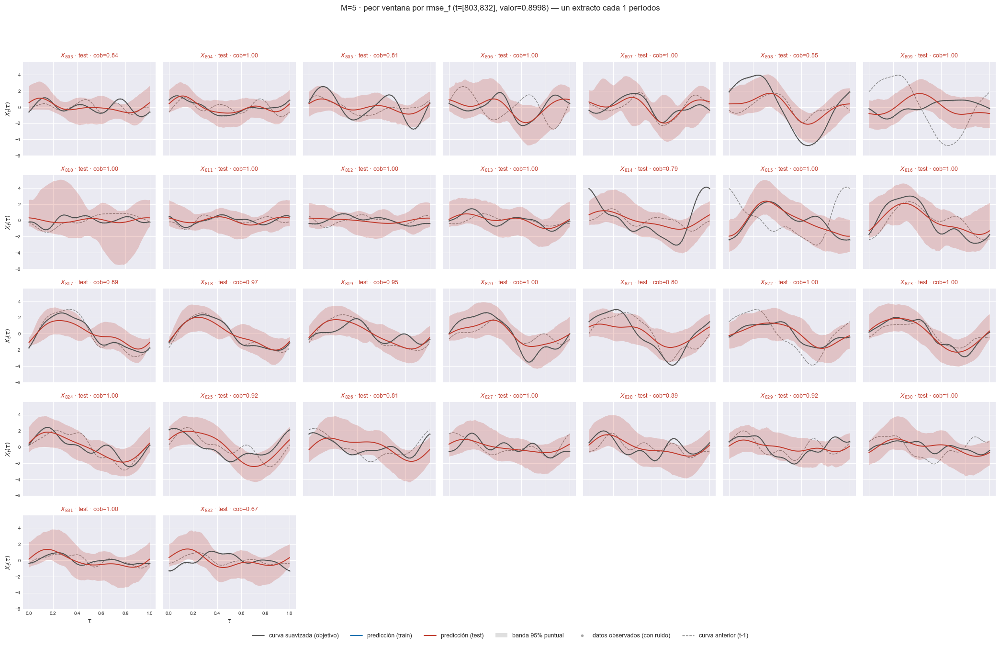

[M=6] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.902279


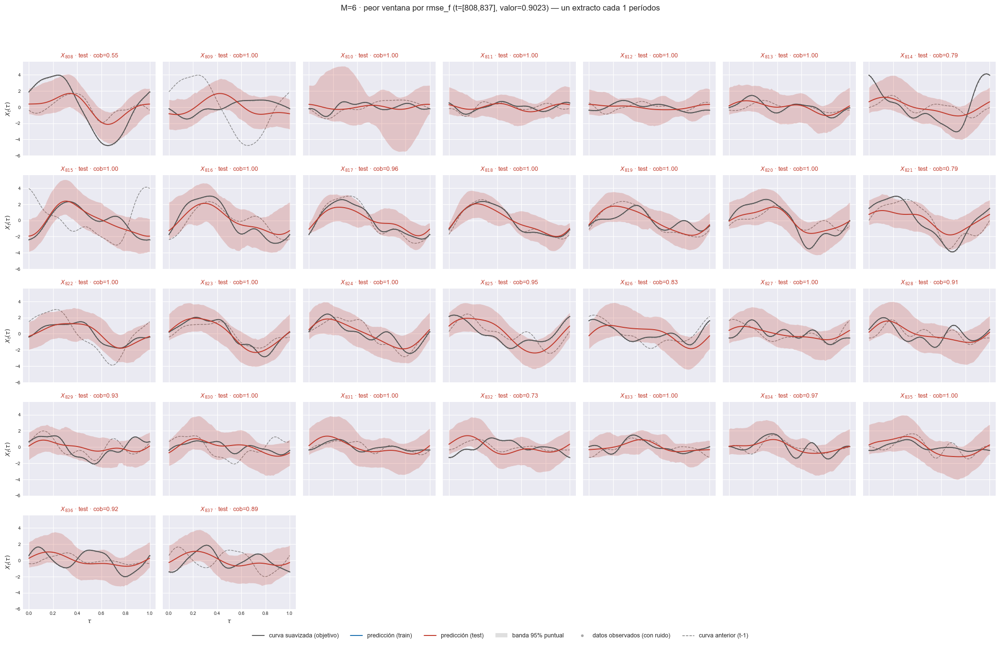

    t=[797, 826]  rmse_f=0.899452


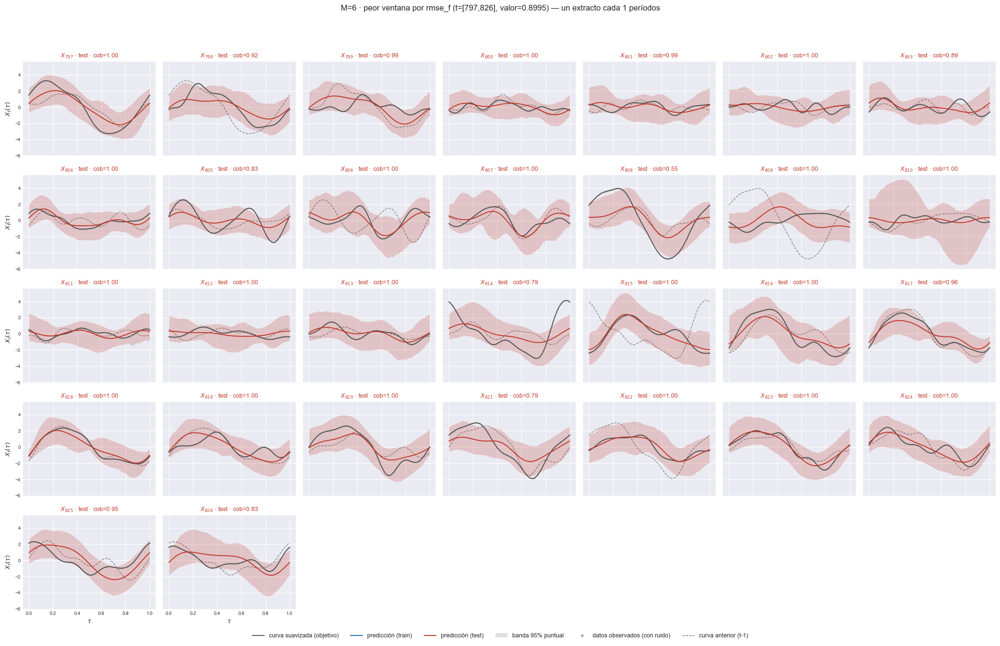

    t=[792, 821]  rmse_f=0.899410


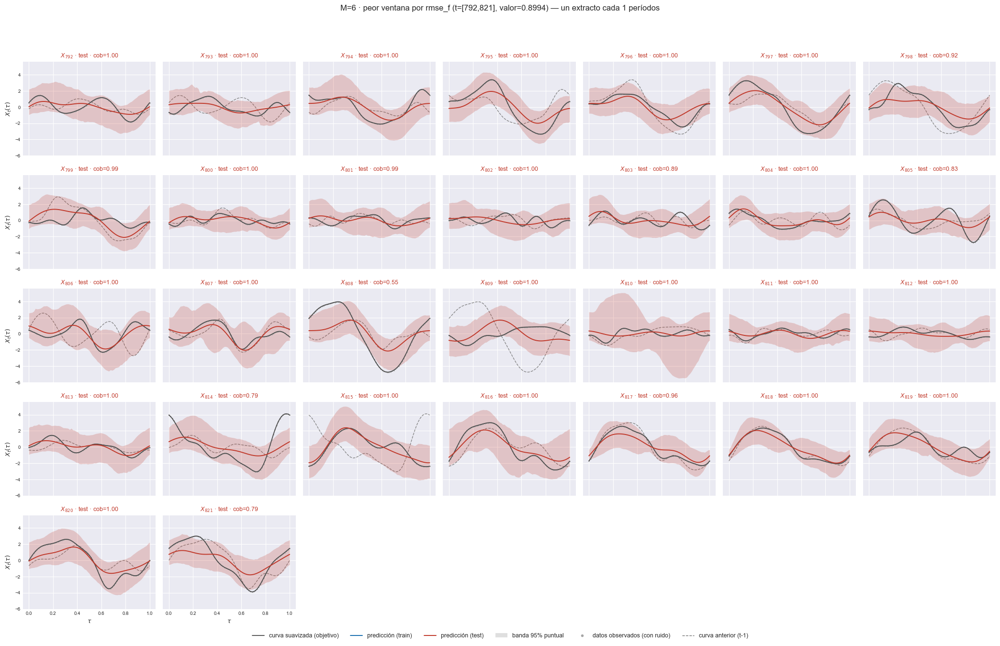

    t=[803, 832]  rmse_f=0.899027


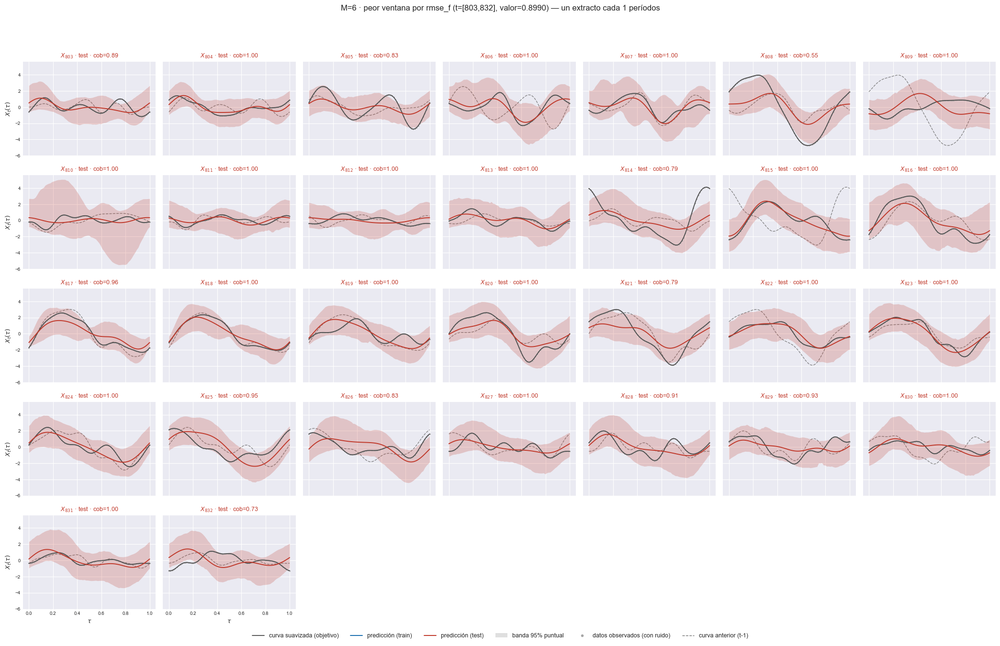

    t=[805, 834]  rmse_f=0.898505


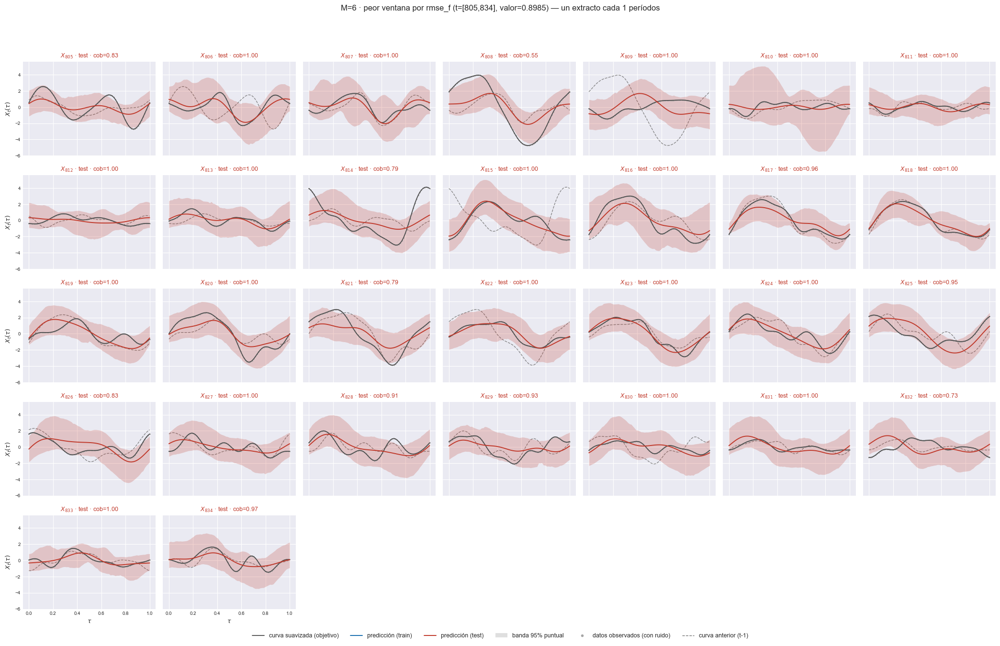

[M=7] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.900538


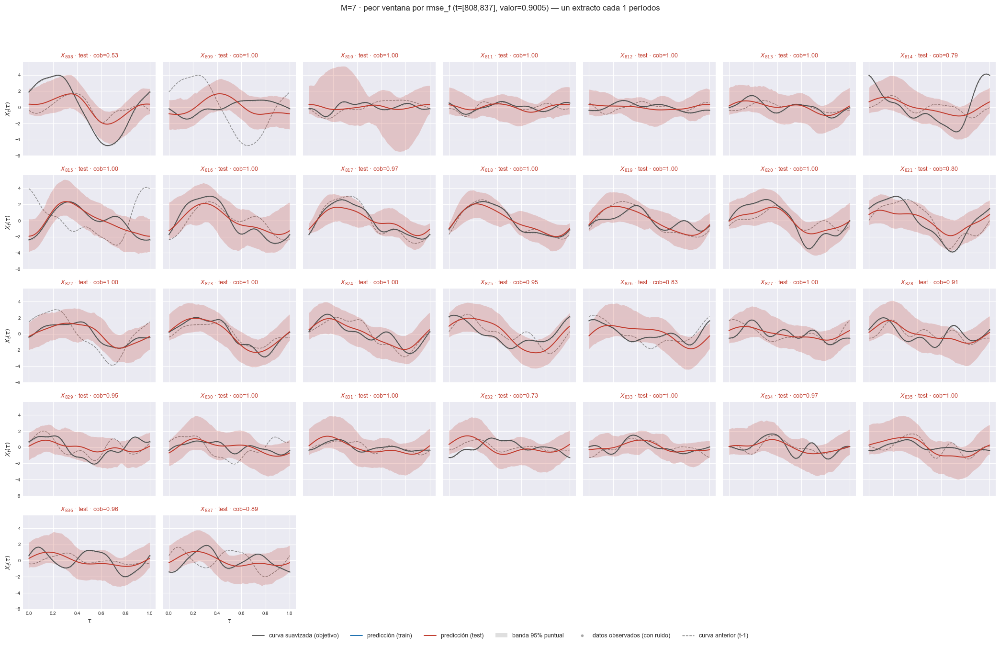

    t=[792, 821]  rmse_f=0.898727


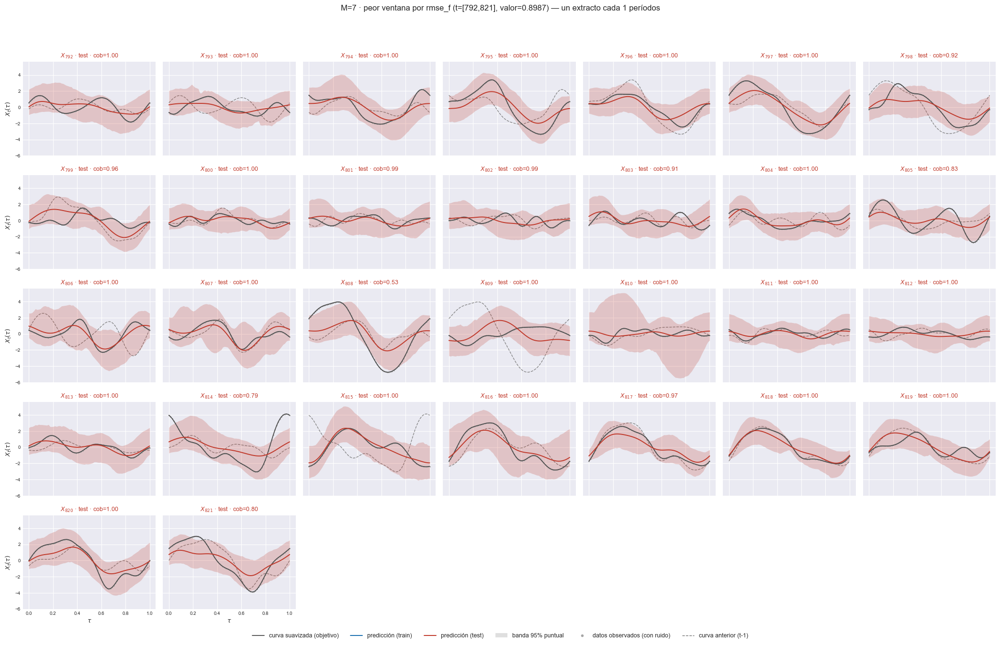

    t=[797, 826]  rmse_f=0.898589


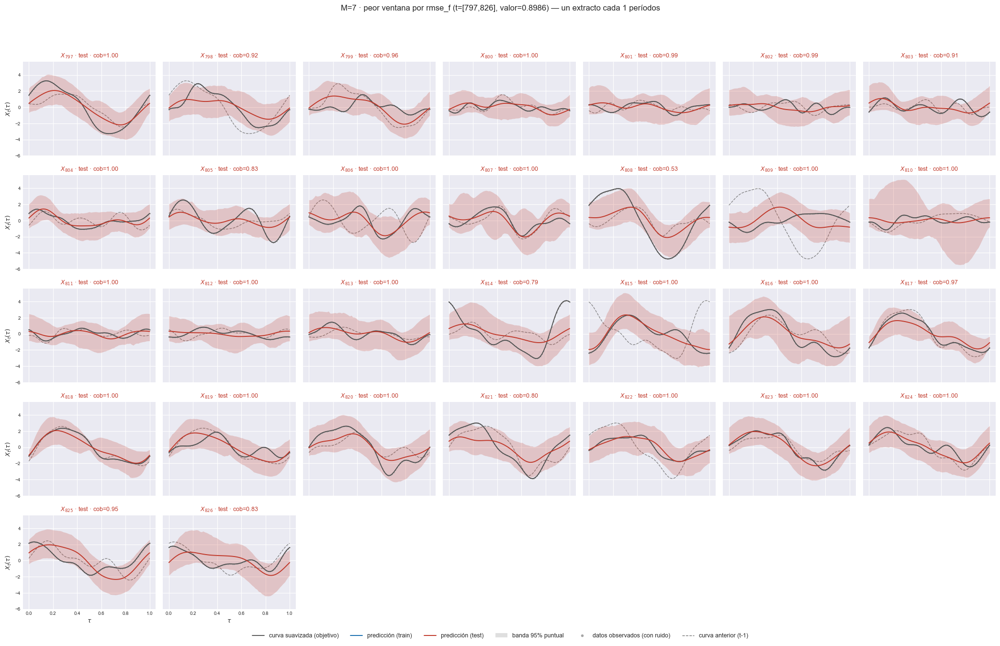

    t=[803, 832]  rmse_f=0.896876


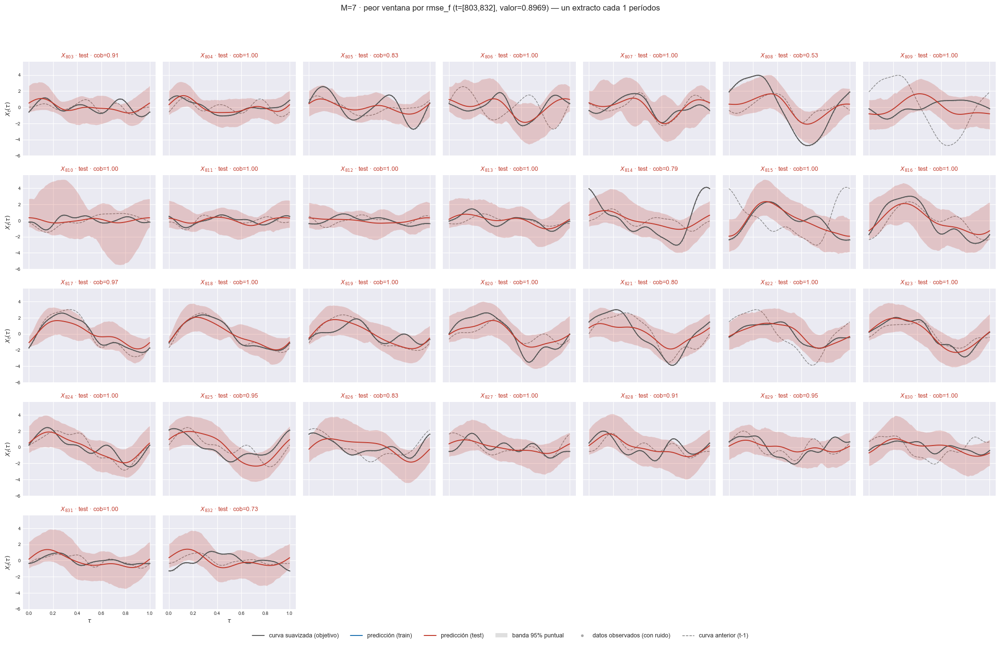

    t=[805, 834]  rmse_f=0.896558


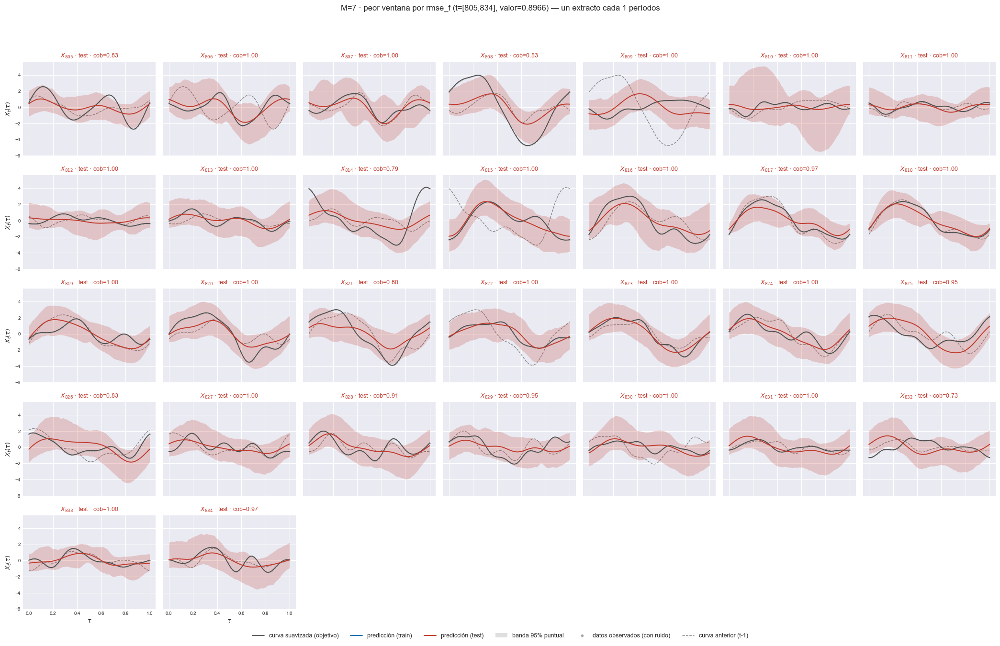

[M=8] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.900137


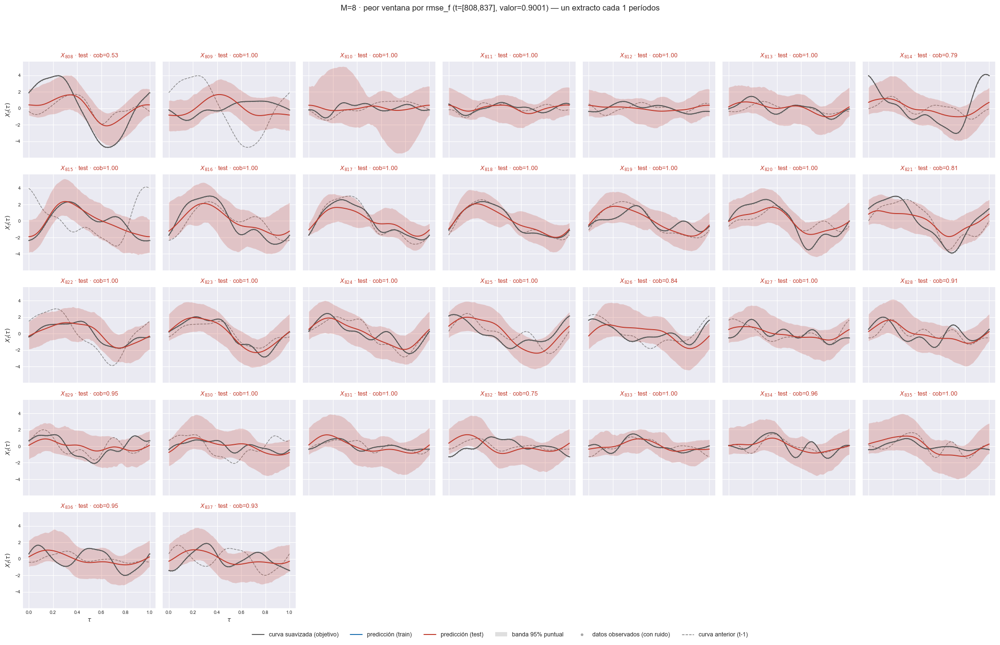

    t=[797, 826]  rmse_f=0.898637


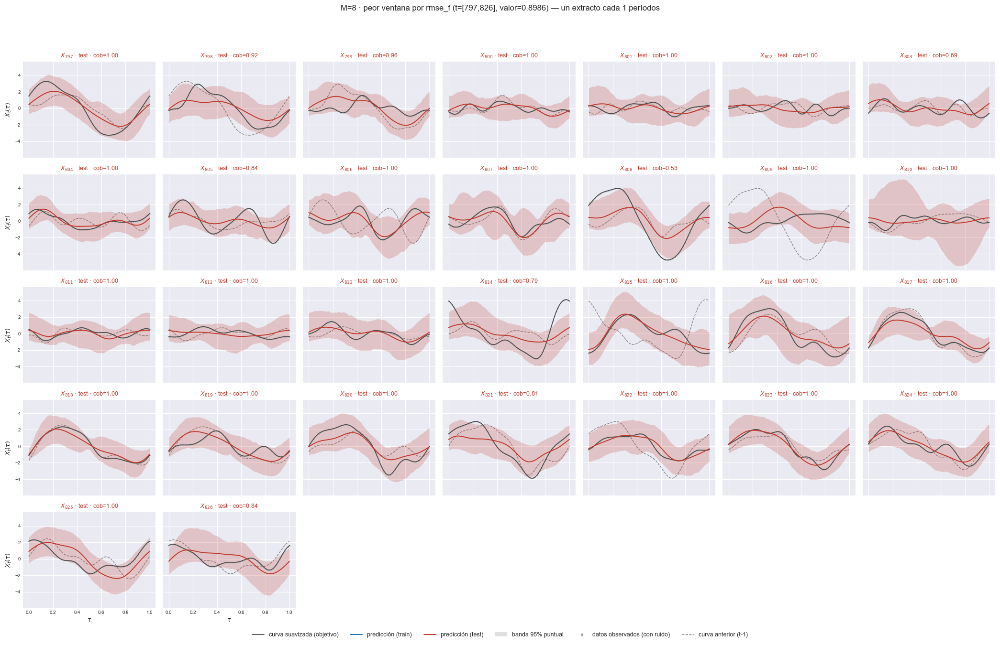

    t=[792, 821]  rmse_f=0.898429


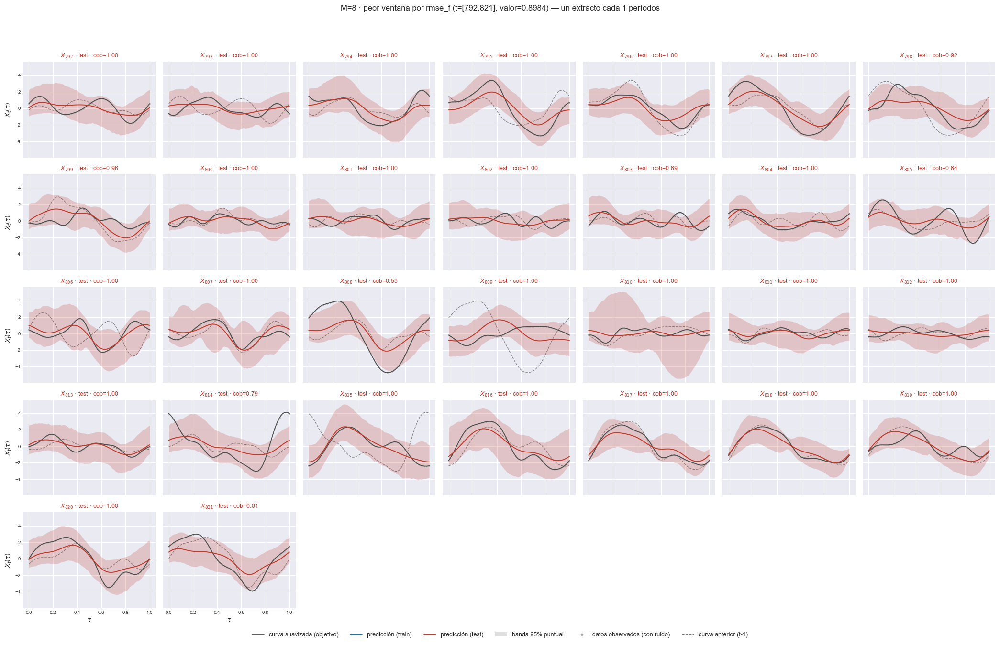

    t=[803, 832]  rmse_f=0.896668


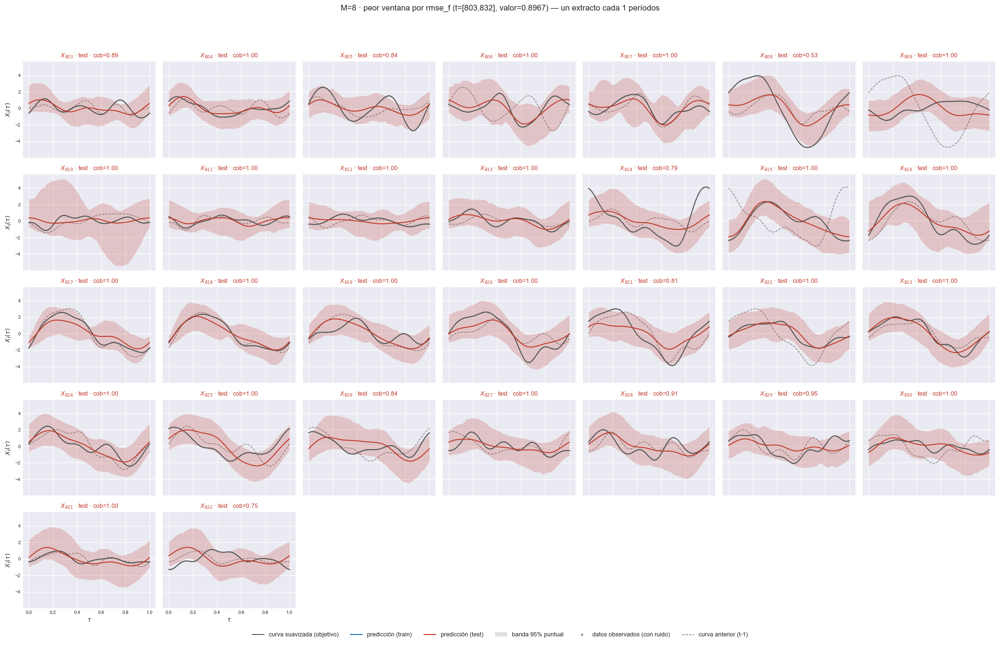

    t=[843, 872]  rmse_f=0.896347


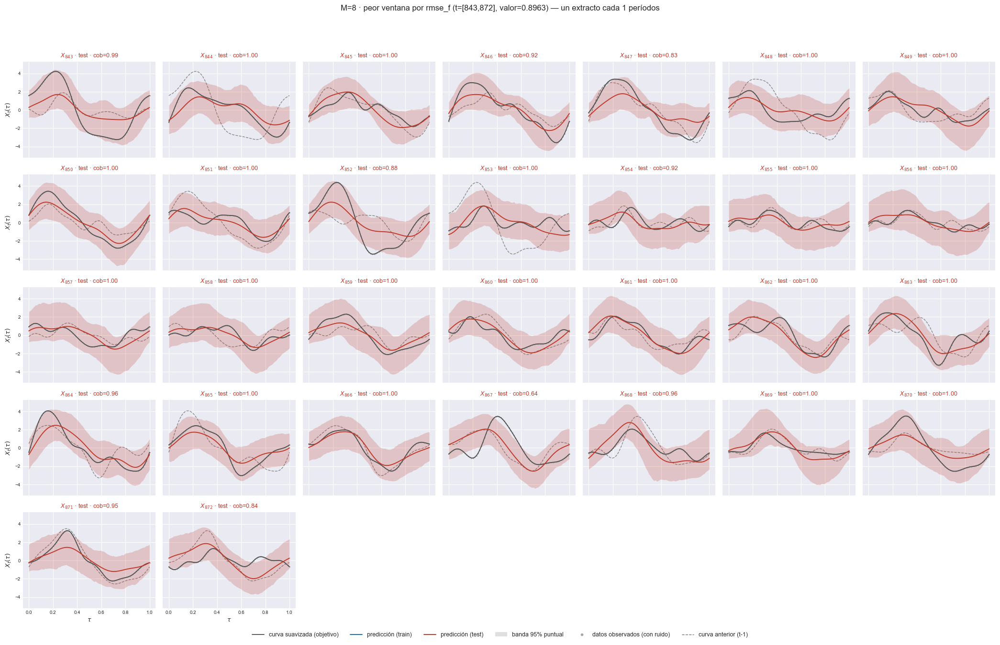

[M=9] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.900253


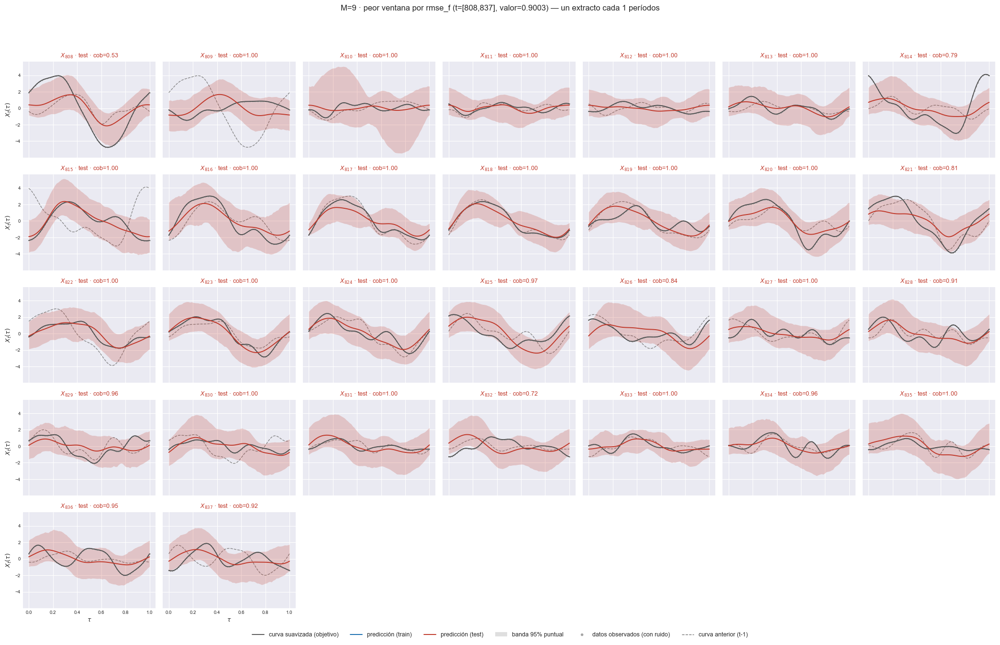

    t=[797, 826]  rmse_f=0.898781


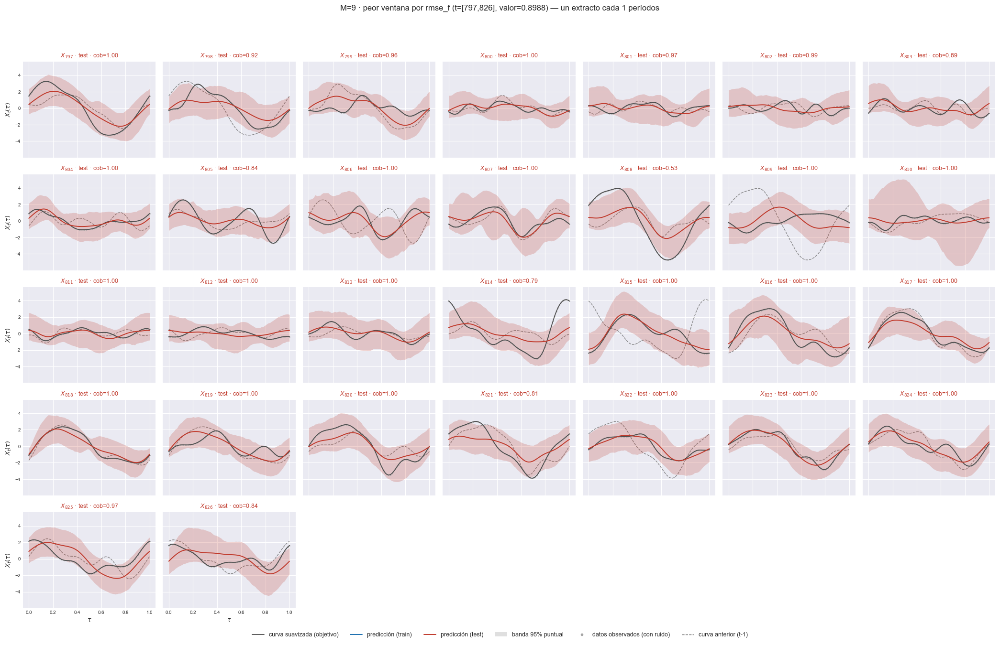

    t=[792, 821]  rmse_f=0.898538


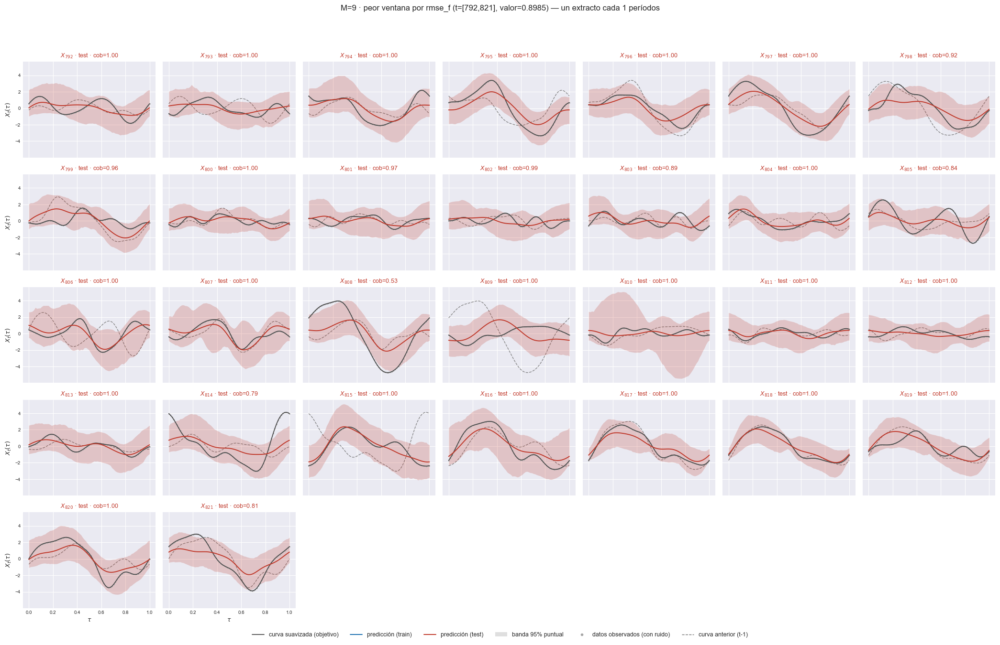

    t=[803, 832]  rmse_f=0.896578


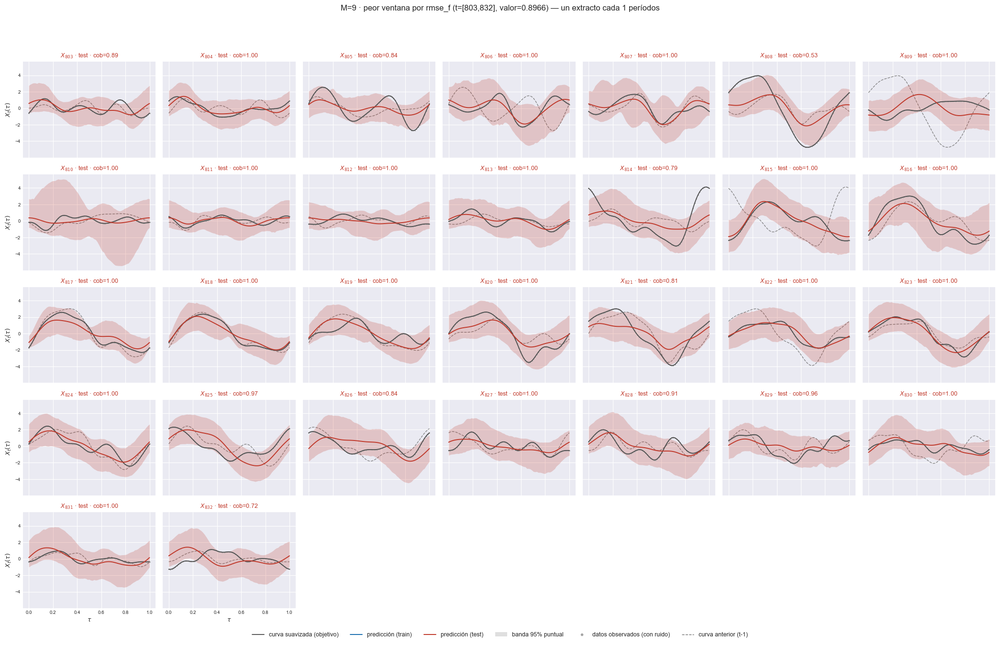

    t=[805, 834]  rmse_f=0.896212


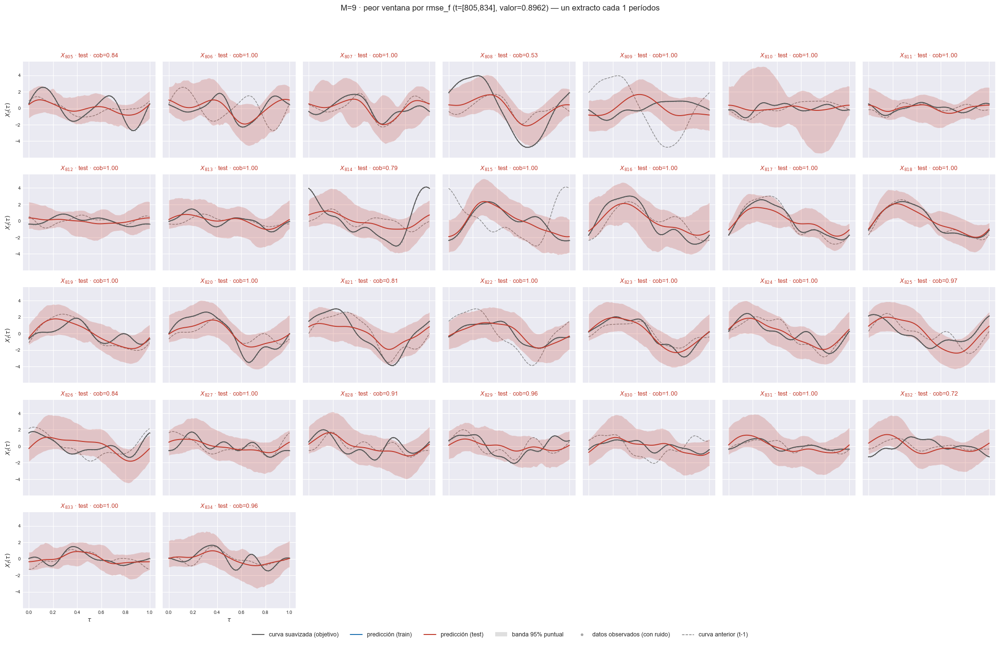

[M=10] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[808, 837]  rmse_f=0.899991


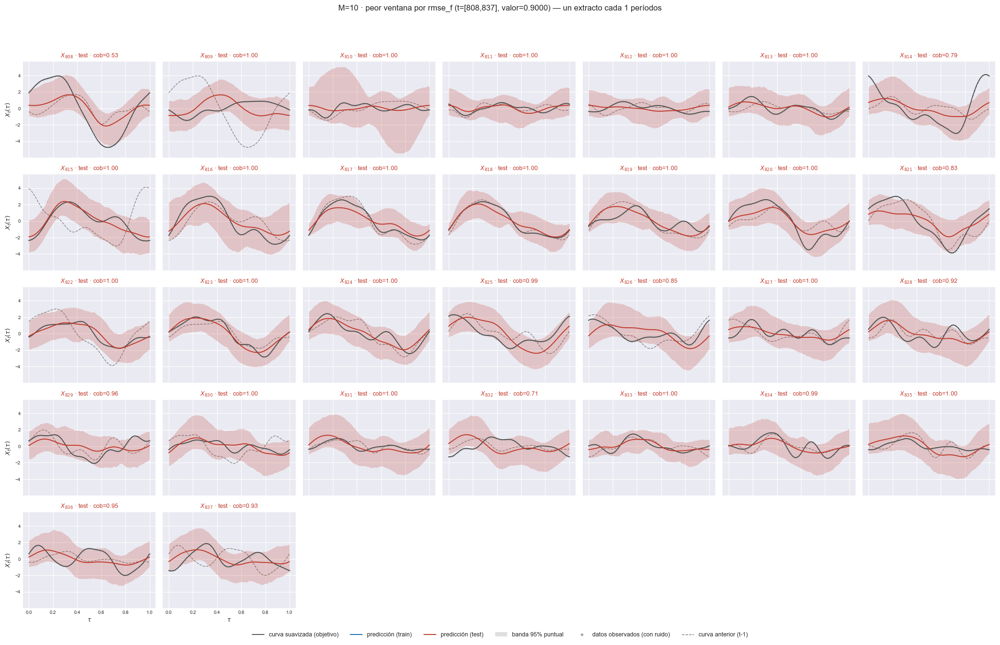

    t=[797, 826]  rmse_f=0.898624


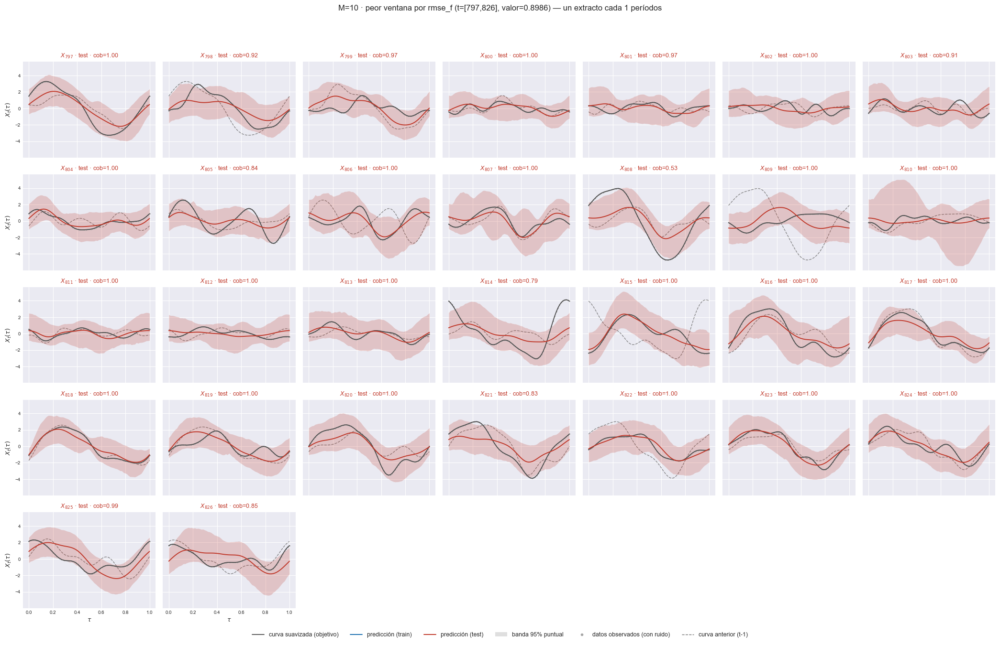

    t=[792, 821]  rmse_f=0.898392


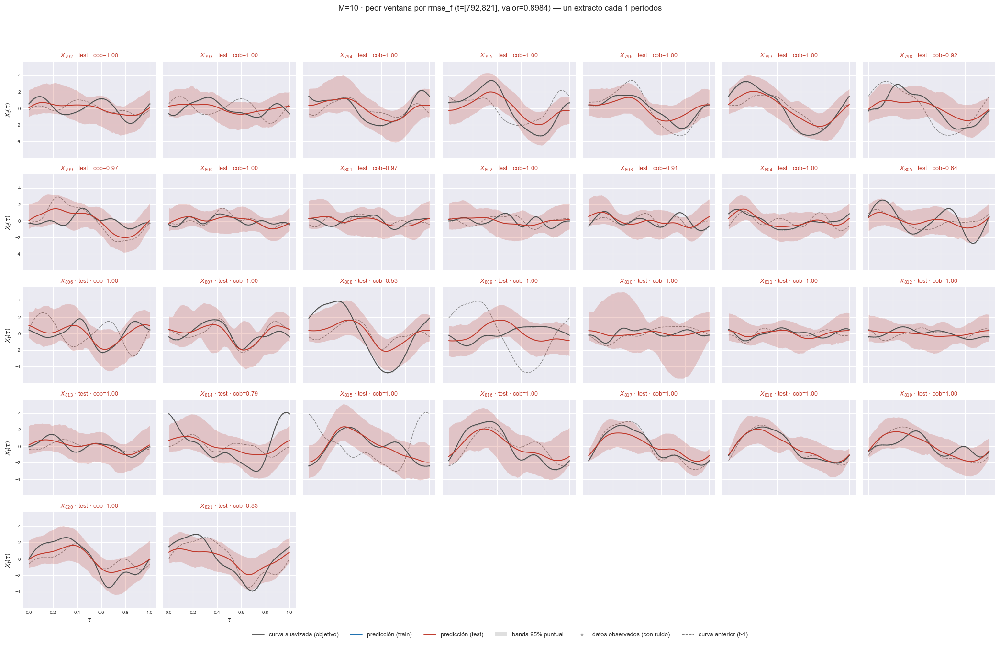

    t=[803, 832]  rmse_f=0.896405


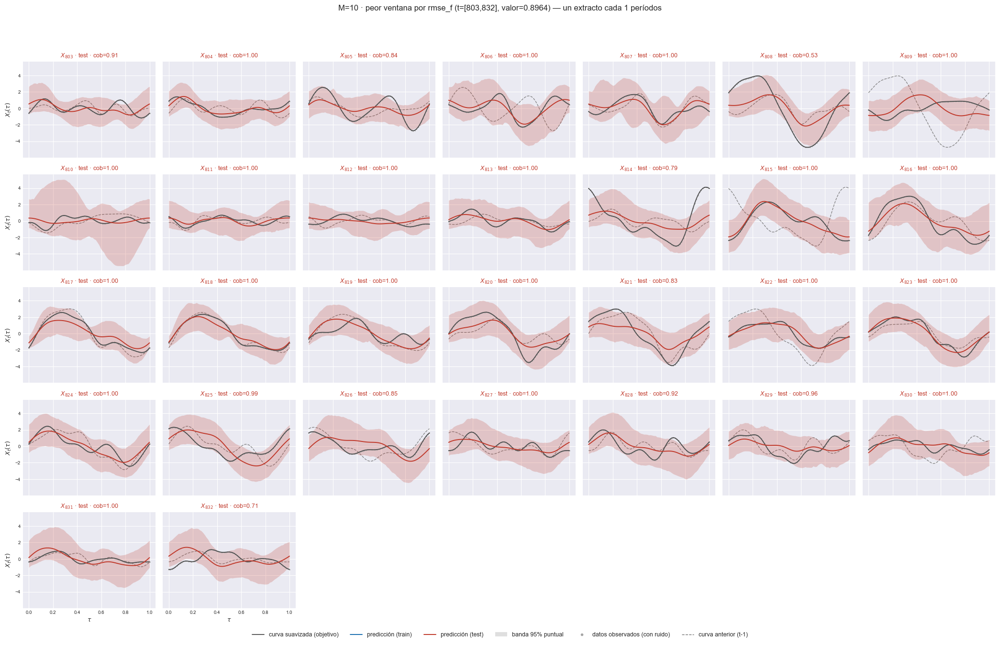

    t=[805, 834]  rmse_f=0.895941


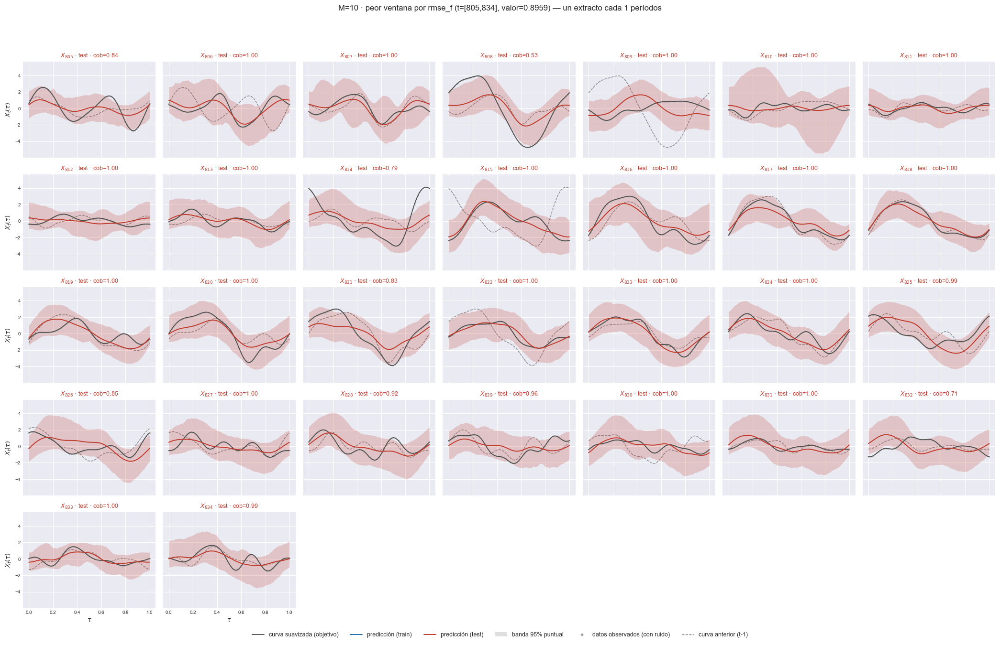

In [13]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

El soporte verdadero sale de `internos["soporte"]` del generador: qué pares (score, rezago) entran en $E[\xi_{j,t}\mid\text{pasado}]$ —los no nulos de $A_{k,l}$ o de $f_k$ y, donde los mecanismos difieren, las covariables de $q_k$—. Es disperso, así que sensibilidad, especificidad y AUC sí son informativas. Con $M<4$ parte del soporte no existe como covariable. El PIP se calcula sobre los scores **estimados**: el contraste es directo sólo si $\psi_k\approx\varphi_k$ (`_03` §6.1 imprime $|\cos(\psi_k,\varphi_k)|$).


In [14]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (1 pasos)
  1/1 (100.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
[matriz_pip] listo: 1 pasos en 0.0s  tabla 4x2
[M=1] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd
variable,,
fpc_1_lag1,1.000,0.000
fpc_1_lag2,0.067,0.082
fpc_1_lag3,0.032,0.028
fpc_1_lag4,0.028,0.014


[matriz_pip] inicio (2 pasos)
  1/2 (50.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/2 (100.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
[matriz_pip] listo: 2 pasos en 0.0s  tabla 8x4
[M=2] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd
variable,,,,
fpc_1_lag1,1.000,0.000,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000
fpc_2_lag2,nan,nan,0.035,0.026
fpc_2_lag3,nan,nan,0.035,0.021
fpc_2_lag4,nan,nan,0.038,0.026


[matriz_pip] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/3 (66.7%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/3 (100.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
[matriz_pip] listo: 3 pasos en 0.0s  tabla 12x6
[M=3] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


...

,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd
variable,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.035,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.035,0.021,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.038,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (9 pasos)
  1/9 (11.1%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/9 (22.2%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/9 (33.3%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
  4/9 (44.4%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.041, 1.000]
  5/9 (55.6%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.043, 1.000]
  6/9 (66.7%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.061, 1.000]
  7/9 (77.8%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.059, 1.000]
  8/9 (88.9%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 4 variables, PIP en [0.054, 1.000]
  9/9 (100.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 4 variables, PIP en [0.056, 1.000]
[matriz_pip] listo: 9 pasos en 0.0s  tabla 36x18
[M=9] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd
variable,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.035,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.035,0.021,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.038,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/10 (20.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/10 (30.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
  4/10 (40.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.041, 1.000]
  5/10 (50.0%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.043, 1.000]
  6/10 (60.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.061, 1.000]
  7/10 (70.0%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.059, 1.000]
  8/10 (80.0%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 4 variables, PIP en [0.054, 1.000]
  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 4 variables, PIP en [0.056, 1.000]
  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 3 cadenas, 4 variables, PIP en [0.052, 1.000]
[matriz_pip] listo: 10 pasos en 0.0s  tabla 40x20
[M=10] dispersion maxima entre cadenas: 0.082   OK las cadenas coi

,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_10_lag1,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1.000,0.000
fpc_10_lag2,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.063,0.020
fpc_10_lag3,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.052,0.012
fpc_10_lag4,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.055,0.003
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


In [15]:
for M in M_OK:
    contraste = contraste_generador(EST[M], ESCENARIO_ID, UMBRAL_PIP, COS_MIN)
    if not contraste.empty:
        display(contraste.style.format("{:.3f}", subset=[
            c for c in contraste.columns if contraste[c].dtype.kind == "f"])
            .set_caption(f"M={M} - selección de variables vs soporte del generador "
                         f"(umbral {UMBRAL_PIP})"))

[M=1] |cos(psi_k, phi_k)| = [1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043


[M=2] |cos(psi_k, phi_k)| = [1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036


[M=3] |cos(psi_k, phi_k)| = [1. 1. 1.]


...

,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065


[M=9] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 9,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.060


[M=10] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 9,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.060


## 8. Cuadro resumen: mínimo, máximo y promedio

La ventana móvil genera una SERIE por métrica, no una cifra. Esta tabla es la
lectura resumida de esa serie: mínimo, máximo y promedio, por bloque
train/test, excluyendo las ventanas que cruzan $T_0$ -su cifra mezcla dentro y
fuera de muestra-. Cubre las 7 métricas de los Bloques A y B; ninguna se
destaca sobre las demás.

In [16]:
# Los dos objetivos en la misma tabla, con la columna que declara cuál.
for M in M_OK:
    resumen = resumen_metricas(EST[M], M, DIS, ORIG)
    display(resumen.style.format({"minimo": "{:.6f}", "maximo": "{:.6f}", "promedio": "{:.6f}"})
            .set_caption(f"M={M} · mínimo / máximo / promedio por ventana "
                         f"(w={W_REF}, sin cruzar T0) · nivel funcional"))

resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)
# Vista rápida: un solo objetivo (el primario del Bloque A); el CSV tiene los dos.
display(resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")]
        .pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=1] curva_suavizada      PICP puntual test = 0.5411 (nominal 0.95)  ·  PICP simultaneo test = 0.0000
[M=1] representacion_fpca  PICP puntual test = 0.9686 (nominal 0.95)  ·  PICP simultaneo test = 0.9686


[M=2] curva_suavizada      PICP puntual test = 0.8169 (nominal 0.95)  ·  PICP simultaneo test = 0.1540
[M=2] representacion_fpca  PICP puntual test = 0.9662 (nominal 0.95)  ·  PICP simultaneo test = 0.8870


[M=3] curva_suavizada      PICP puntual test = 0.8907 (nominal 0.95)  ·  PICP simultaneo test = 0.2515
[M=3] representacion_fpca  PICP puntual test = 0.9710 (nominal 0.95)  ·  PICP simultaneo test = 0.8242


[M=4] curva_suavizada      PICP puntual test = 0.9447 (nominal 0.95)  ·  PICP simultaneo test = 0.5031
[M=4] representacion_fpca  PICP puntual test = 0.9680 (nominal 0.95)  ·  PICP simultaneo test = 0.7686


[M=5] curva_suavizada      PICP puntual test = 0.9571 (nominal 0.95)  ·  PICP simultaneo test = 0.5721
[M=5] representacion_fpca  PICP puntual test = 0.9689 (nominal 0.95)  ·  PICP simultaneo test = 0.7465


...

[M=7] curva_suavizada      PICP puntual test = 0.9665 (nominal 0.95)  ·  PICP simultaneo test = 0.6633
[M=7] representacion_fpca  PICP puntual test = 0.9683 (nominal 0.95)  ·  PICP simultaneo test = 0.7039


[M=8] curva_suavizada      PICP puntual test = 0.9682 (nominal 0.95)  ·  PICP simultaneo test = 0.6855
[M=8] representacion_fpca  PICP puntual test = 0.9691 (nominal 0.95)  ·  PICP simultaneo test = 0.7086


[M=9] curva_suavizada      PICP puntual test = 0.9682 (nominal 0.95)  ·  PICP simultaneo test = 0.6781
[M=9] representacion_fpca  PICP puntual test = 0.9689 (nominal 0.95)  ·  PICP simultaneo test = 0.7076


[M=10] curva_suavizada      PICP puntual test = 0.9694 (nominal 0.95)  ·  PICP simultaneo test = 0.6907
[M=10] representacion_fpca  PICP puntual test = 0.9694 (nominal 0.95)  ·  PICP simultaneo test = 0.6907


M,1,2,3,4,5,6,7,8,9,10
metrica,,,,,,,,,,
1. MAE (L^1),0.713680,0.672804,0.634800,0.611634,0.610302,0.609401,0.609034,0.609099,0.608728,0.608652
10. Winkler max peor ventana,110.153177,68.181356,56.964404,45.602952,40.835170,40.471196,39.779125,37.839035,37.752360,37.532583
2. RMSE (L^2),0.906452,0.853710,0.807873,0.782675,0.780518,0.778797,0.777760,0.777433,0.777240,0.777128
3. E_max promedio por curva,1.633727,1.564066,1.472328,1.410220,1.406934,1.400979,1.398244,1.395972,1.394984,1.392756
4. E_max peor de la ventana,3.072922,2.922209,2.800118,2.795655,2.769375,2.770102,2.766488,2.757615,2.748704,2.749770
5. MPIW,1.764447,2.786985,3.135223,3.351358,3.450259,3.510780,3.541703,3.560165,3.570350,3.575695
6. PICP puntual,0.541096,0.816882,0.890699,0.944694,0.957130,0.964346,0.966532,0.968153,0.968210,0.969383
7. PICPB curva completa,0.000000,0.153998,0.251538,0.503075,0.572079,0.651907,0.663346,0.685486,0.678106,0.690652
8. Winkler,11.953095,5.693002,4.613525,3.968097,3.913330,3.900107,3.901616,3.906718,3.908927,3.906754


## 9. Monitoreo univariado por componente FPCA

Cada componente FPCA retenida se predice de manera univariada dentro del
modelo -es una mezcla por componente-, así que aquí se mira su MAE, RMSE y
MISE (= RMSE² del score, el análogo puntual del MISE funcional) por separado,
sobre la ventana móvil. Con $M=1$ hay una sola línea por panel; con $M=k$ hay
$k$ líneas, una por componente. **Solo monitoreo**: ninguna de las tres es
primaria.

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.1s eta=0.0s  t=7

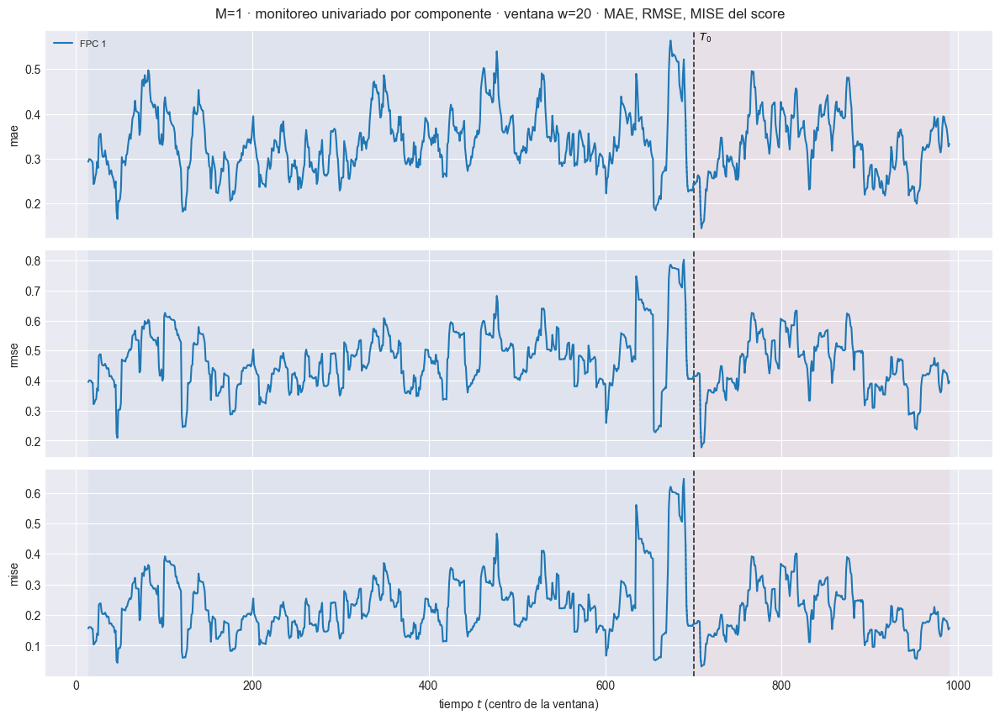

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.3267  w=30 test=0.3393
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.4749  w=30 test=0.4553
  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.2256  w=30 test=0.2073
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m01\91_ventana_univariado_w30.png


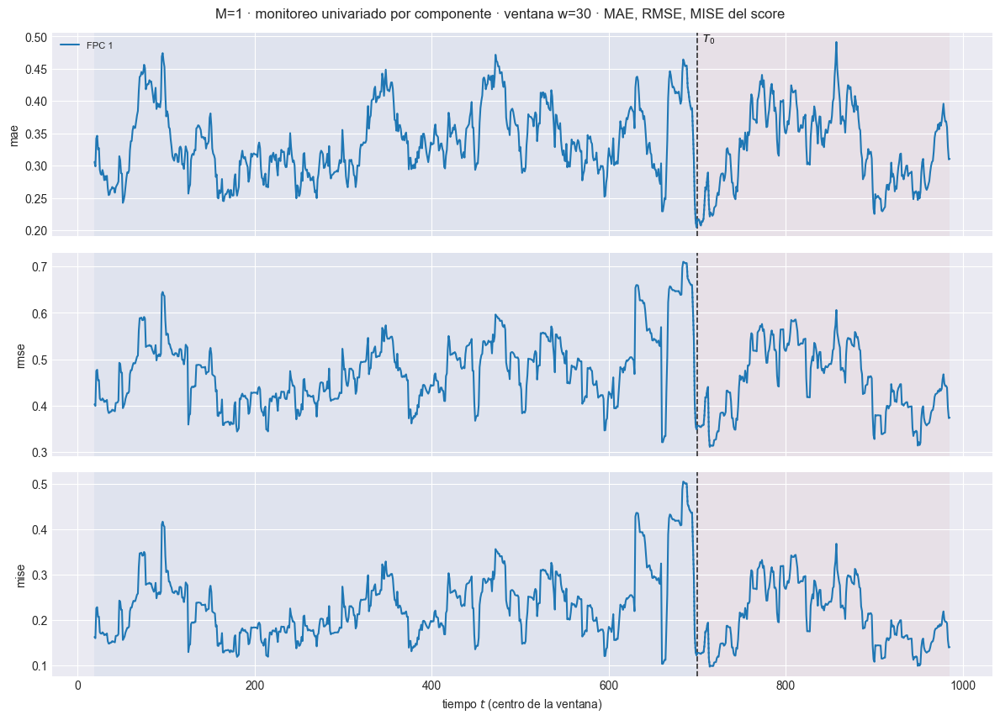

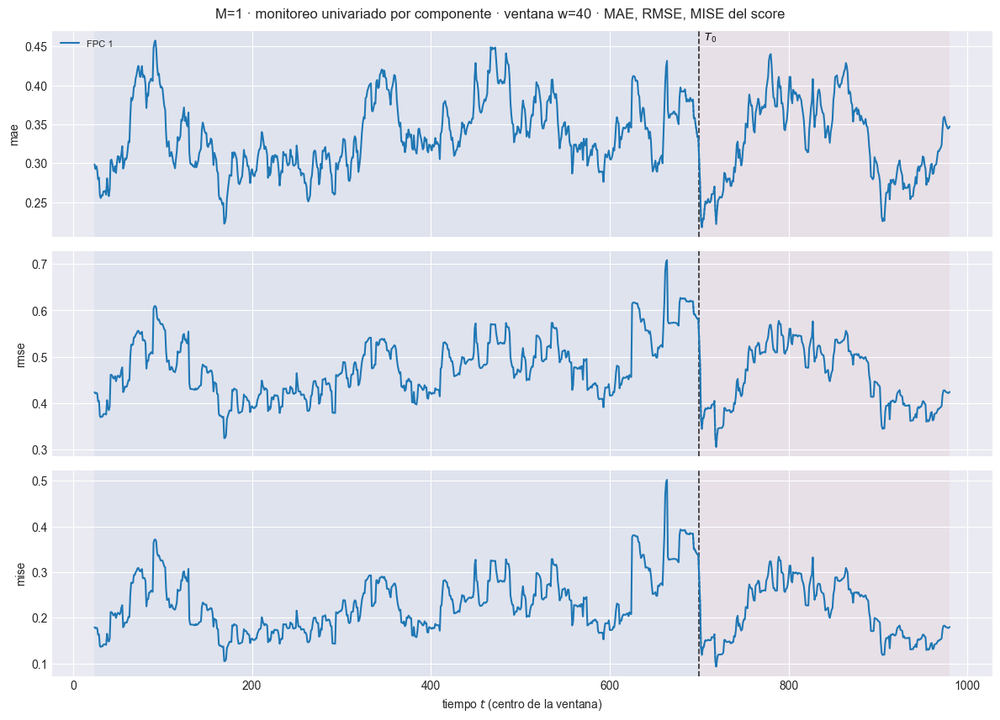

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=1.0s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.2s eta=0.1s  t=7

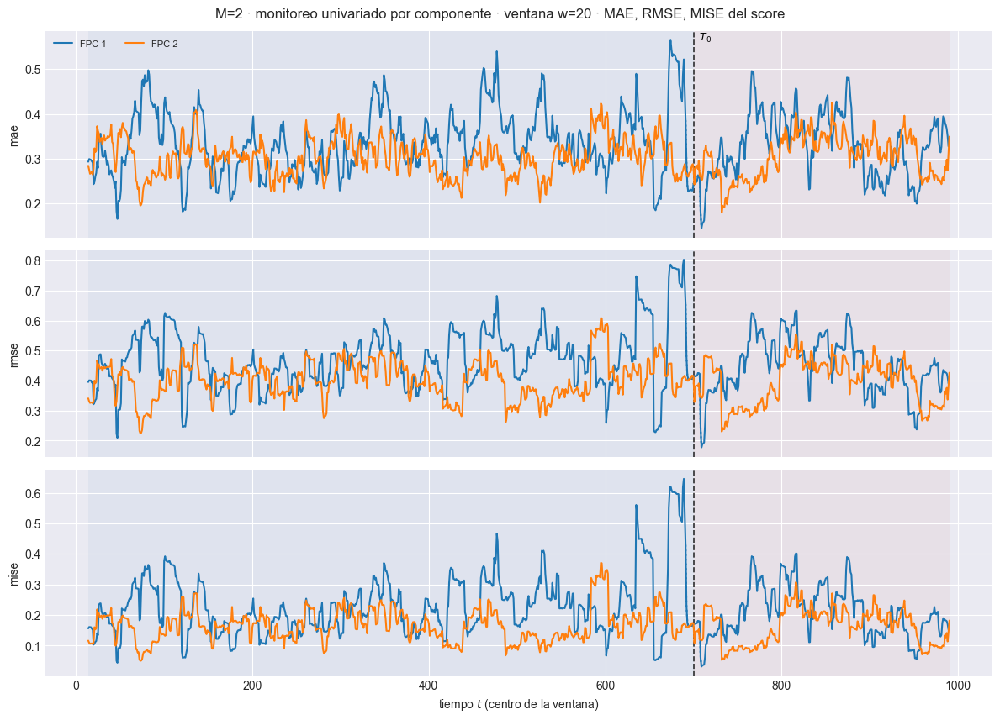

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.314  w=30 test=0.3218
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.4297  w=30 test=0.4317
  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.1847  w=30 test=0.1863
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m02\91_ventana_univariado_w30.png


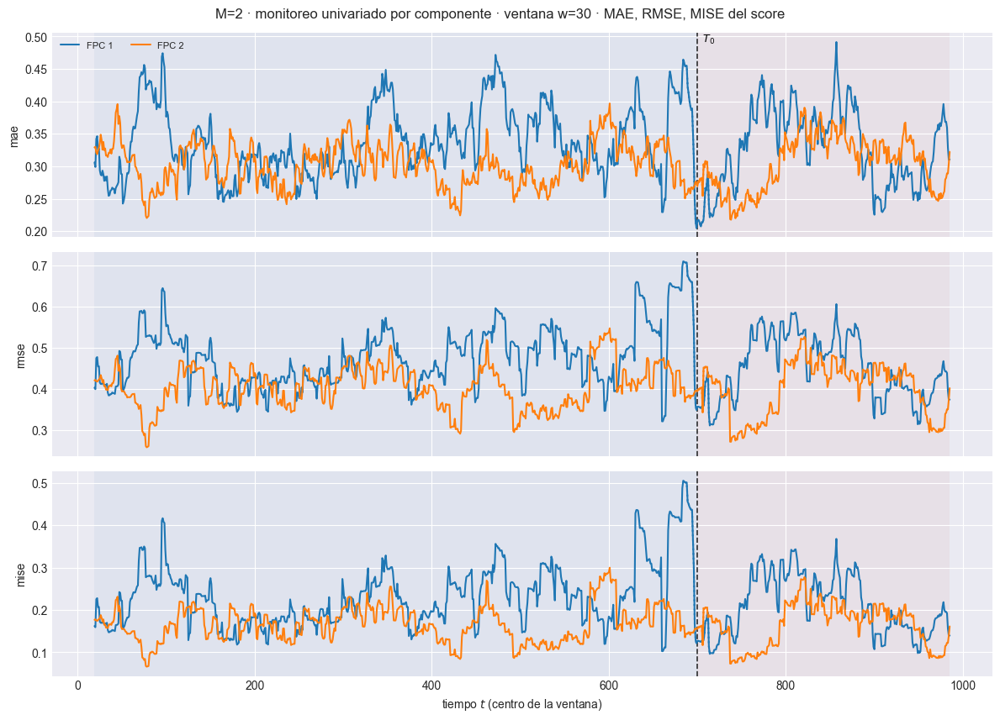

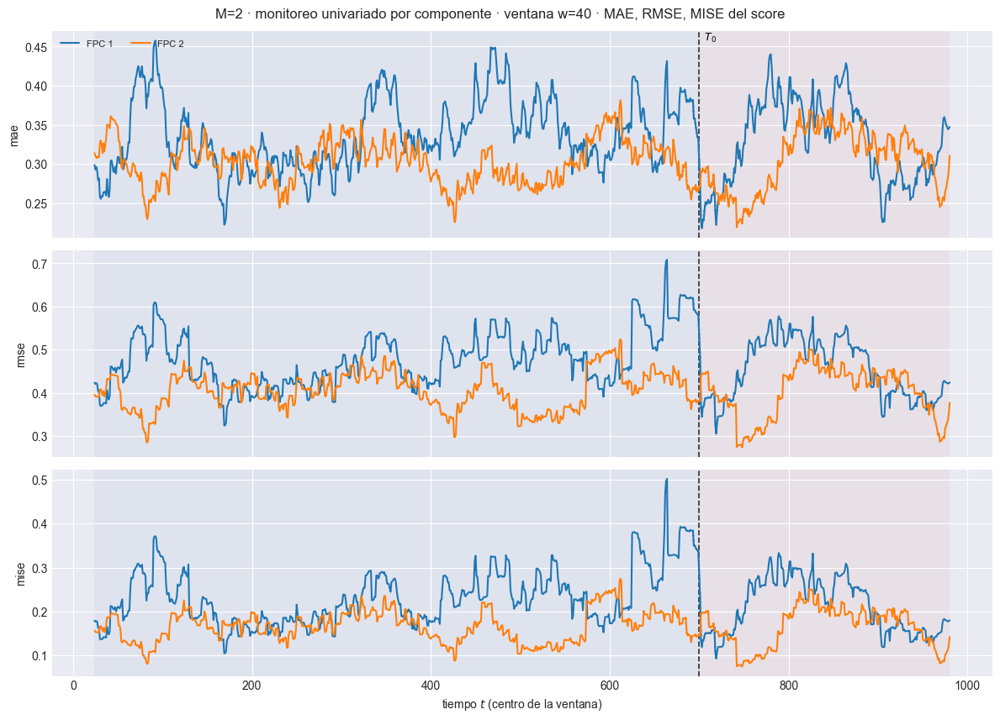

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=1.8s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.1s eta=0.0s  t=7

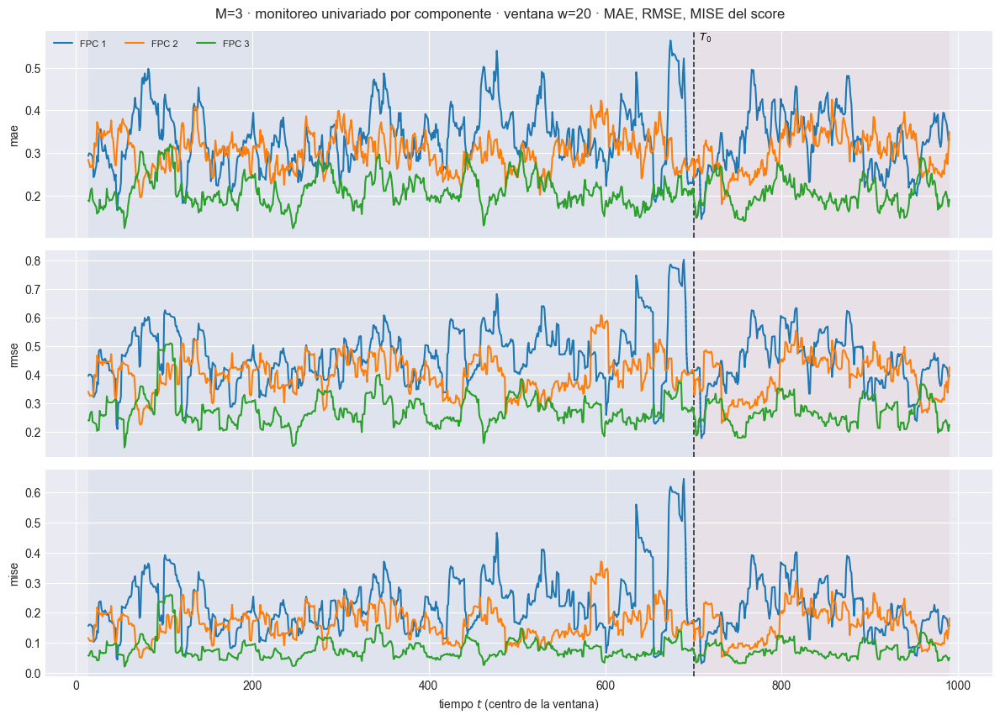

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2878  w=30 test=0.2758
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.3968  w=30 test=0.3757
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.1575  w=30 test=0.1412
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m03\91_ventana_univariado_w30.png


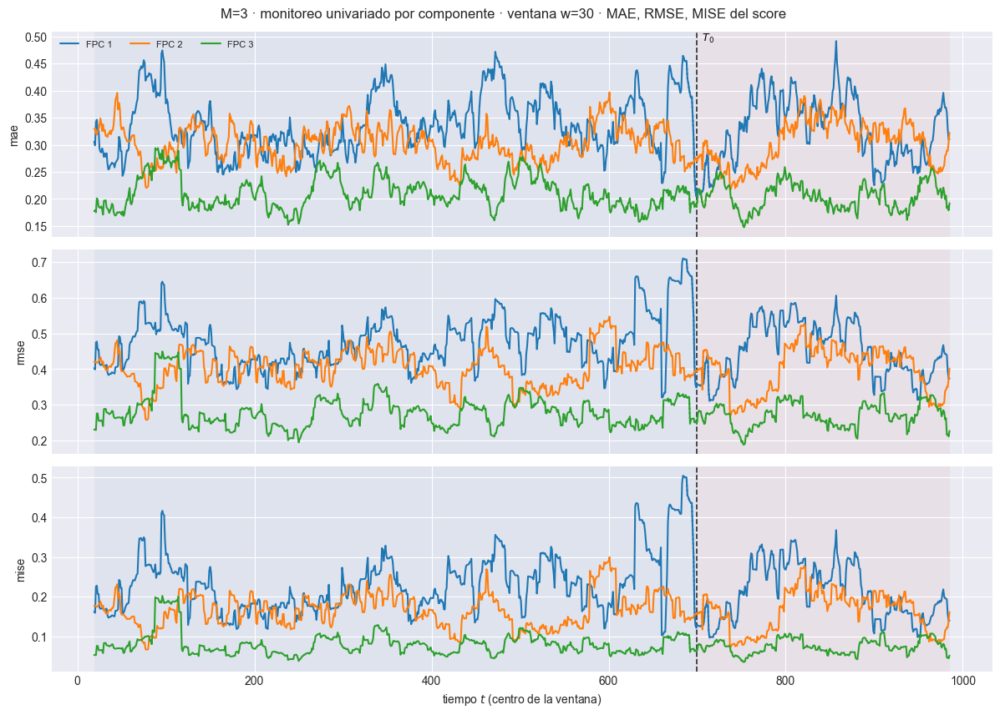

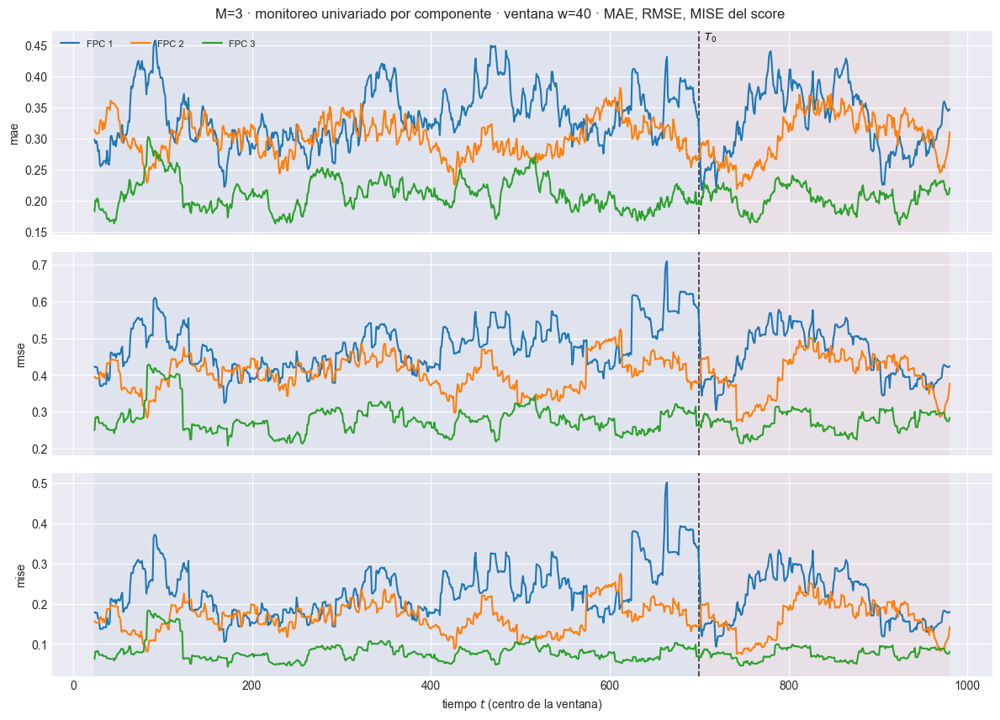

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.0s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.0s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.0s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.0s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.1s eta=0.0s  t=7

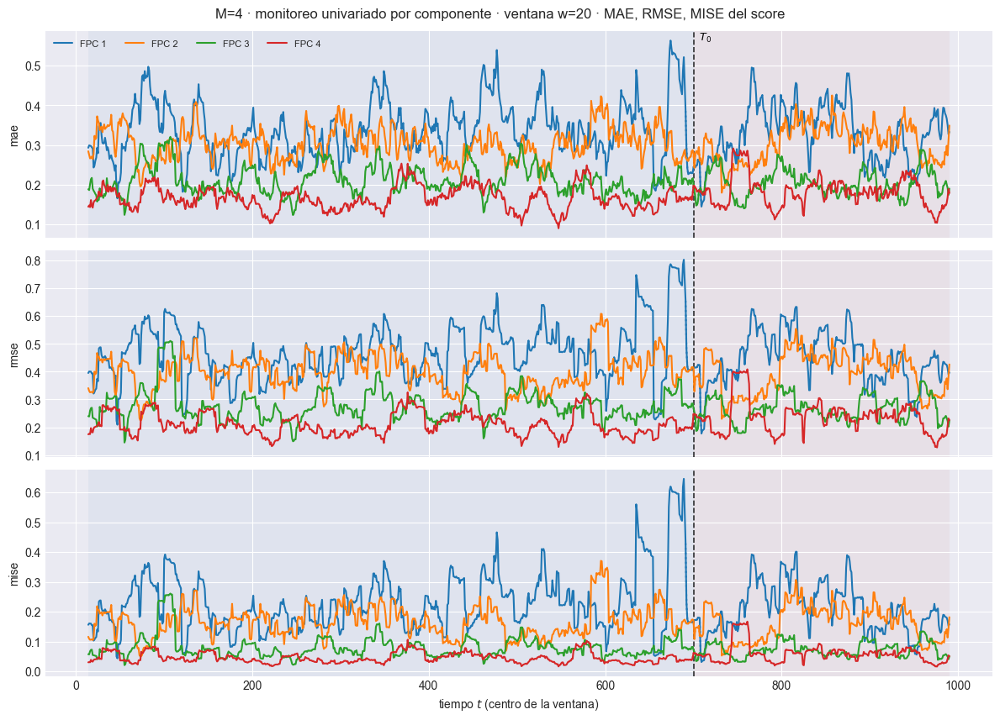

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2555  w=30 test=0.2424
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.3344  w=30 test=0.3153
  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.1118  w=30 test=0.09942
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m04\91_ventana_univariado_w30.png


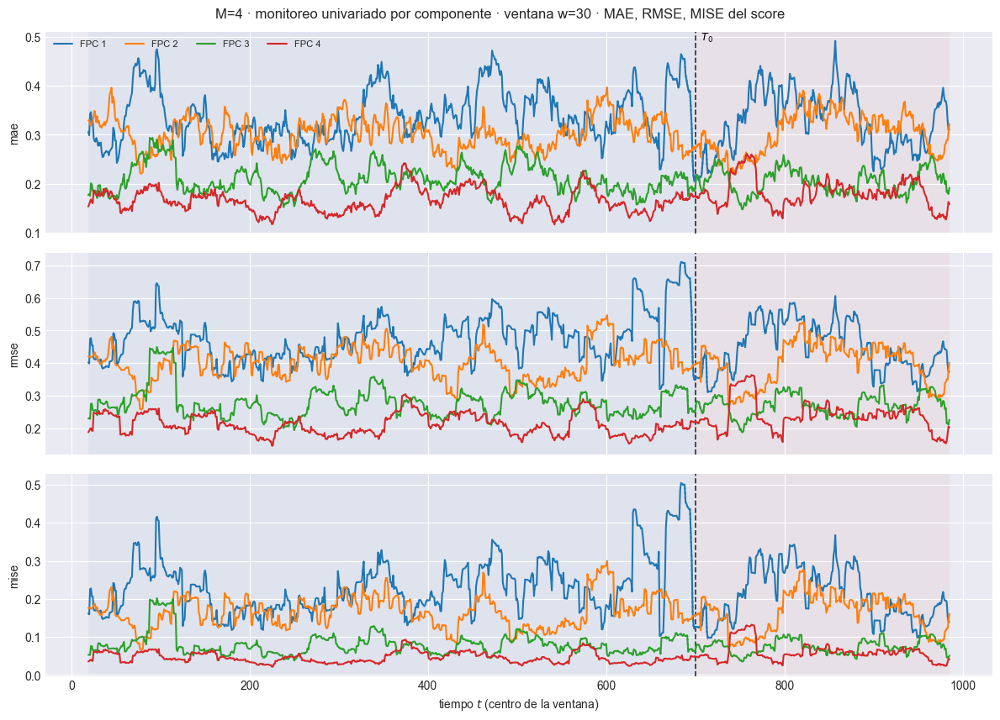

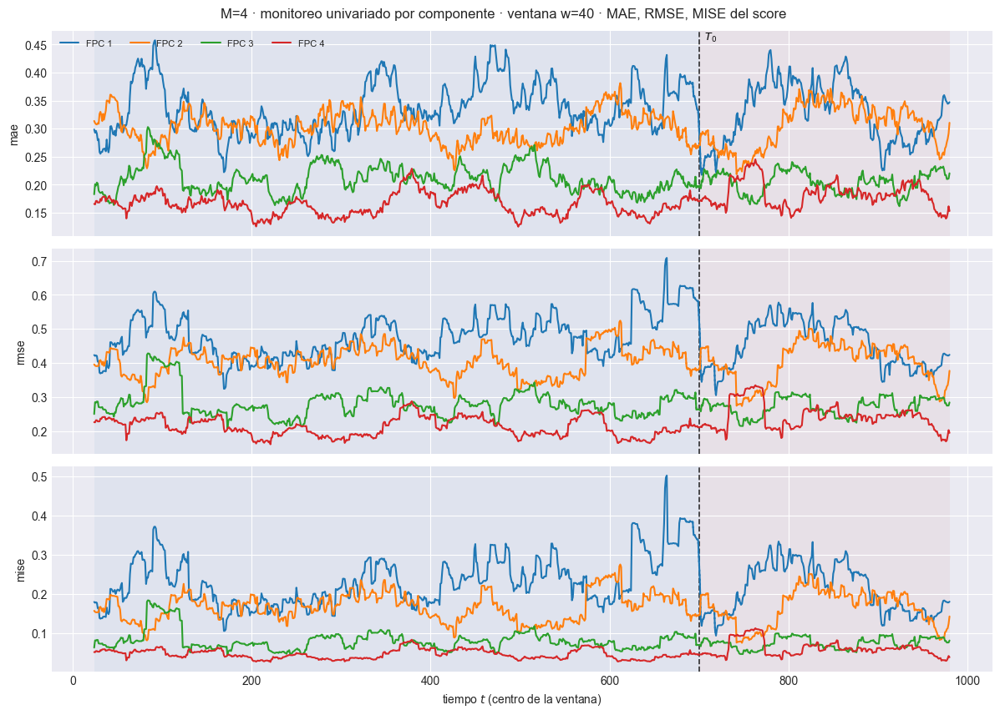

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=2.0s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.2s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.2s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.2s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.1s eta=0.2s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.2s eta=0.1s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.2s eta=0.1s  t=7

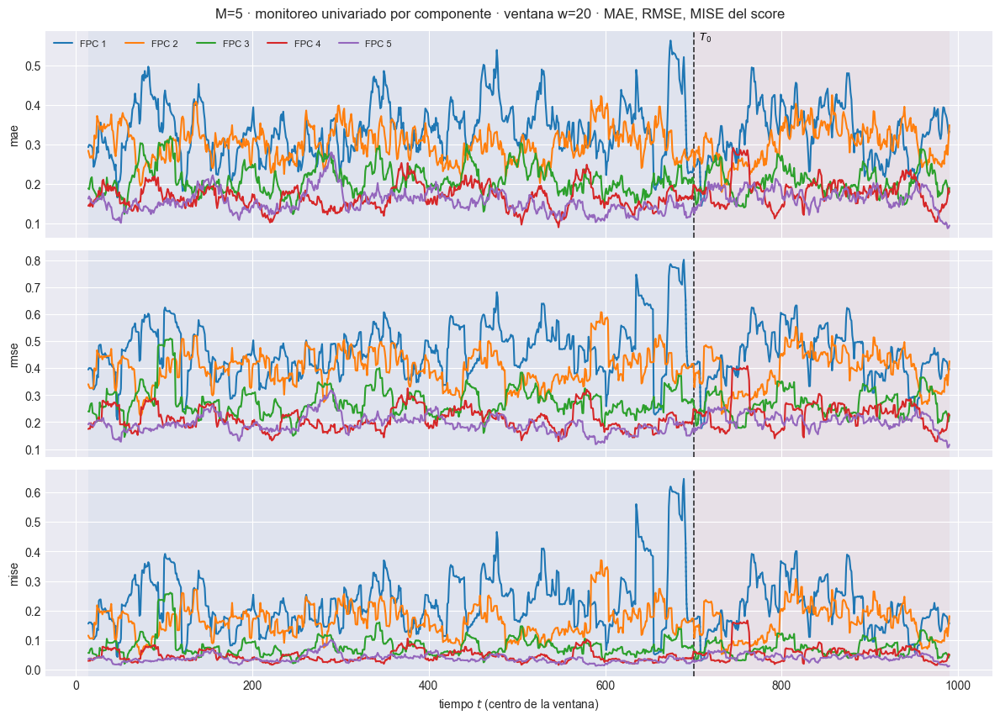

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.1s eta=0.1s  mae: w=30 train=0.2112  w=30 test=0.2149
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.2784  w=30 test=0.2805
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.07749  w=30 test=0.07867
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m05\91_ventana_univariado_w30.png


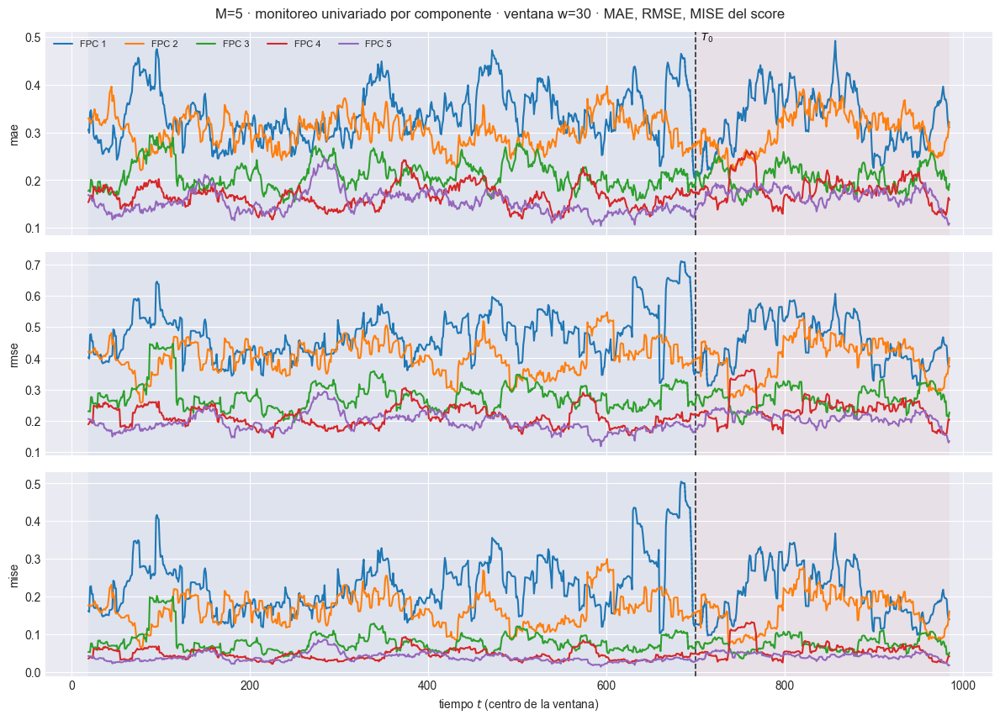

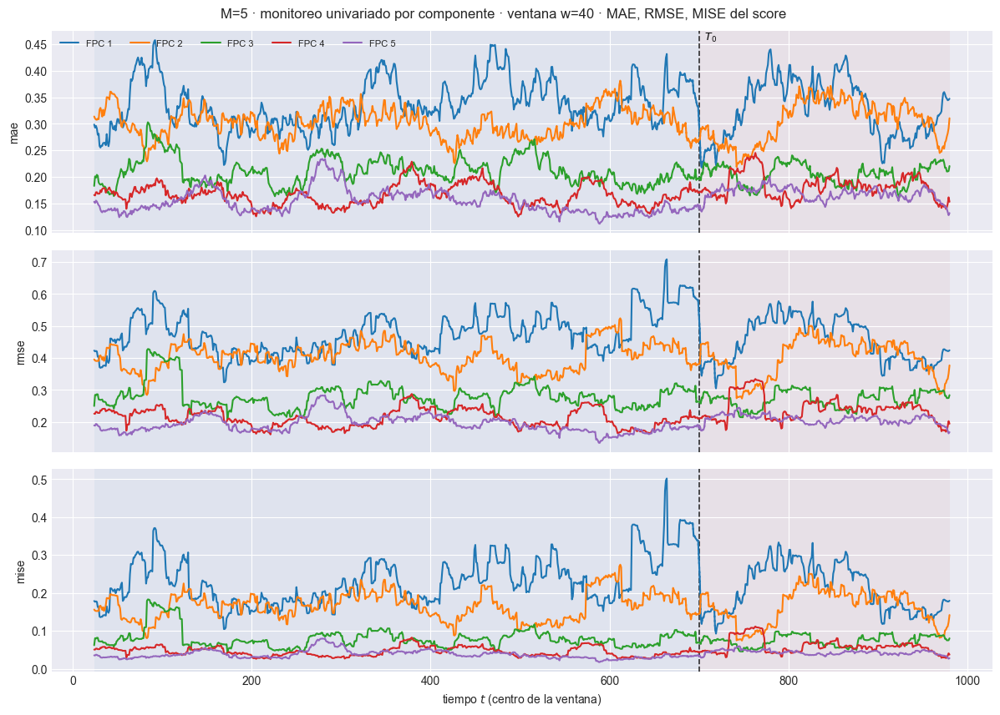

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.0s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.0s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.1s eta=0.0s  t=7

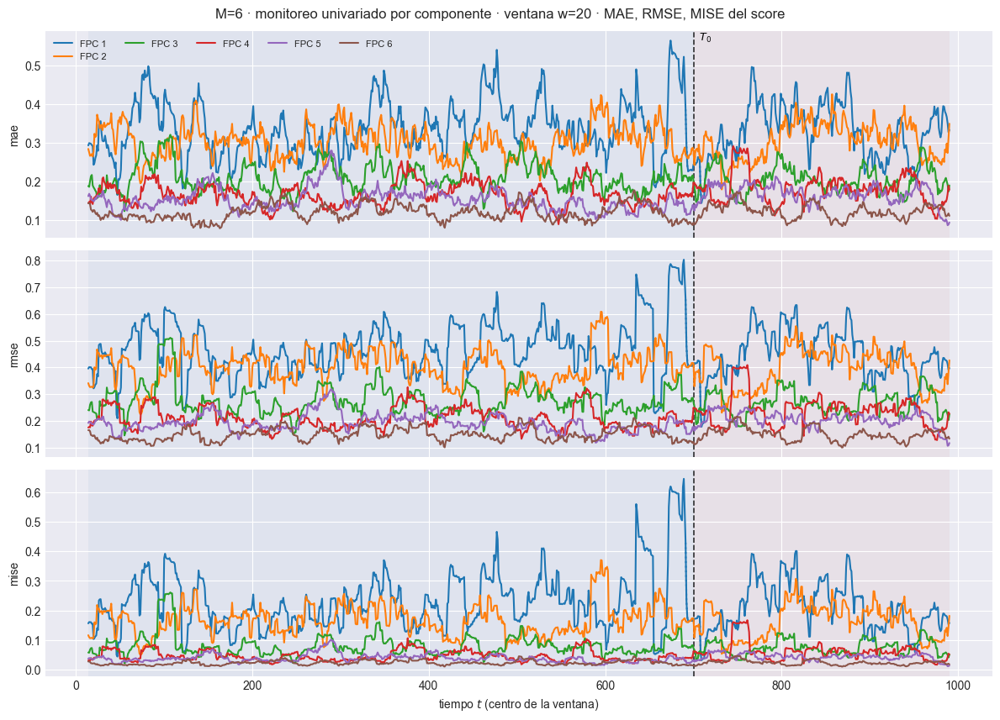

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1881  w=30 test=0.1919
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.245  w=30 test=0.2527
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.06002  w=30 test=0.06384
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m06\91_ventana_univariado_w30.png


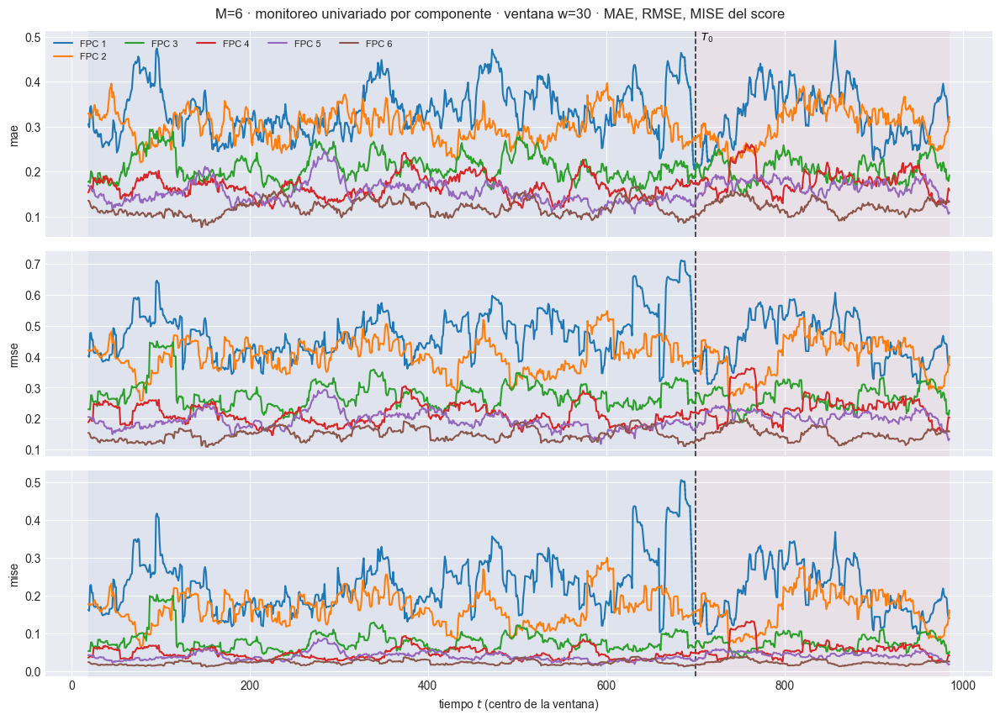

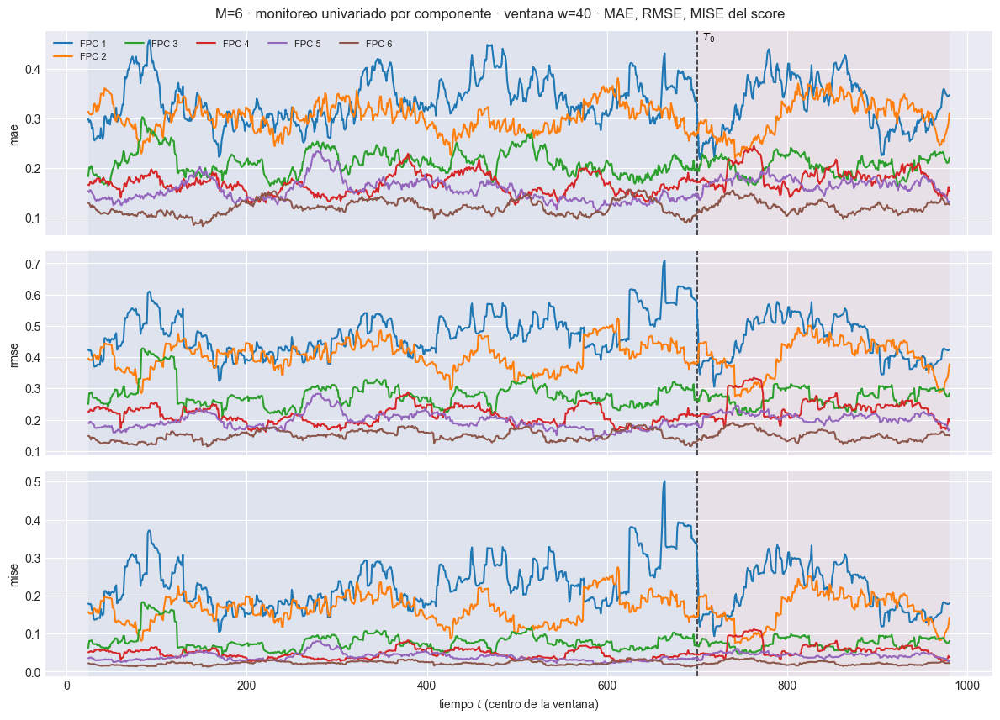

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=1.2s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.0s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.0s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.1s eta=0.0s  t=7

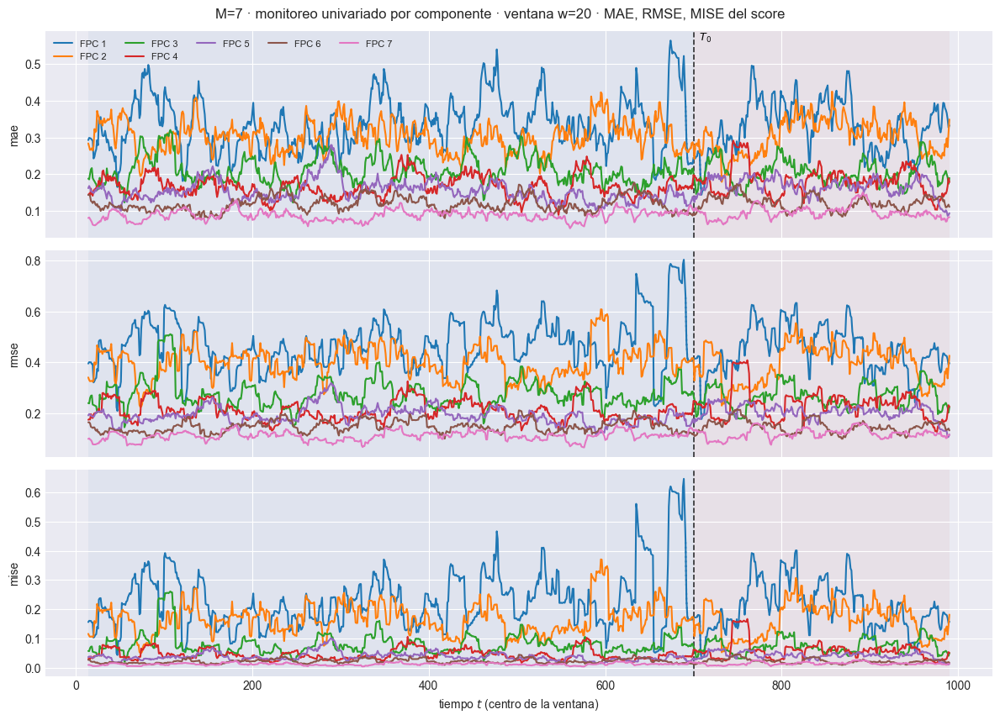

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1717  w=30 test=0.1816
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.2187  w=30 test=0.2316
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.04783  w=30 test=0.05366
[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m07\91_ventana_univariado_w30.png


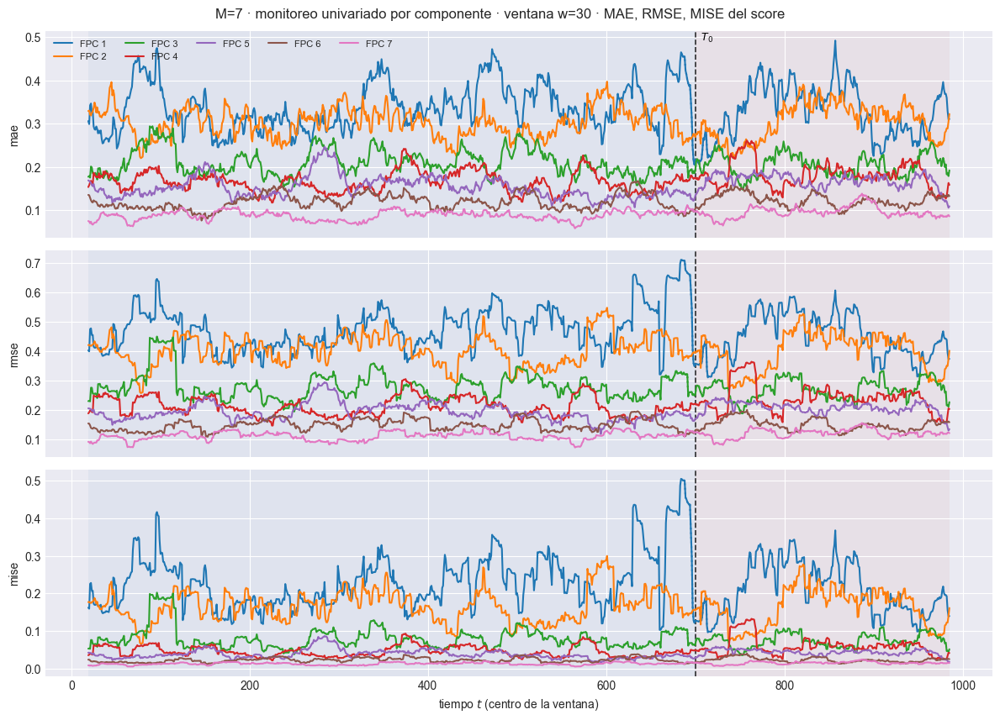

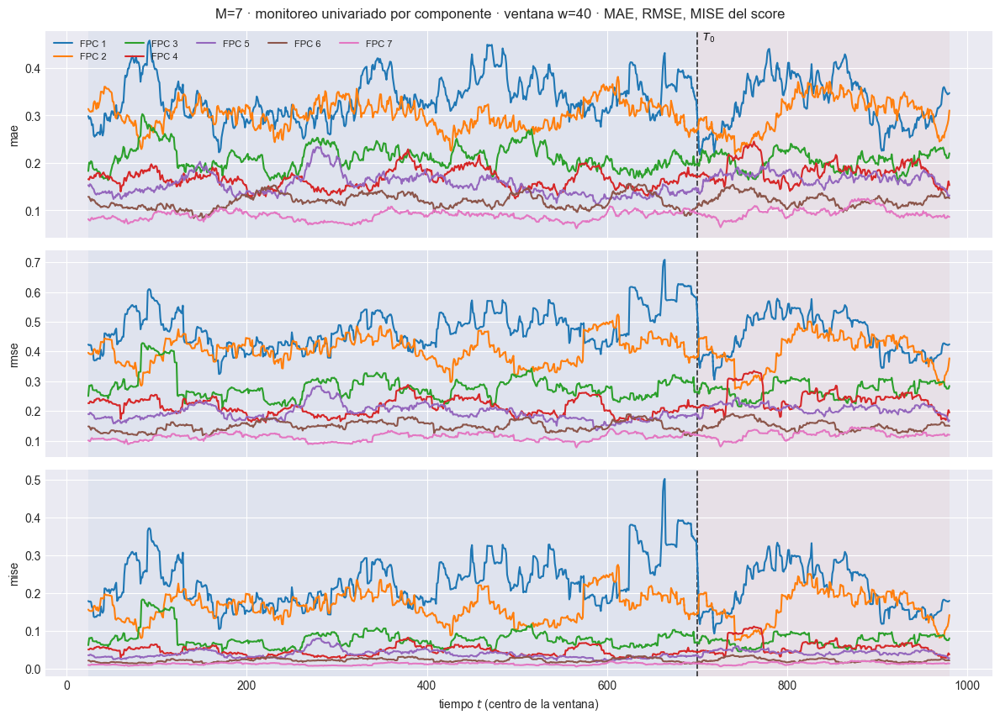

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.2s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.1s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.1s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.1s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.1s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.1s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.1s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.1s eta=0.1s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.1s eta=0.0s  t=7

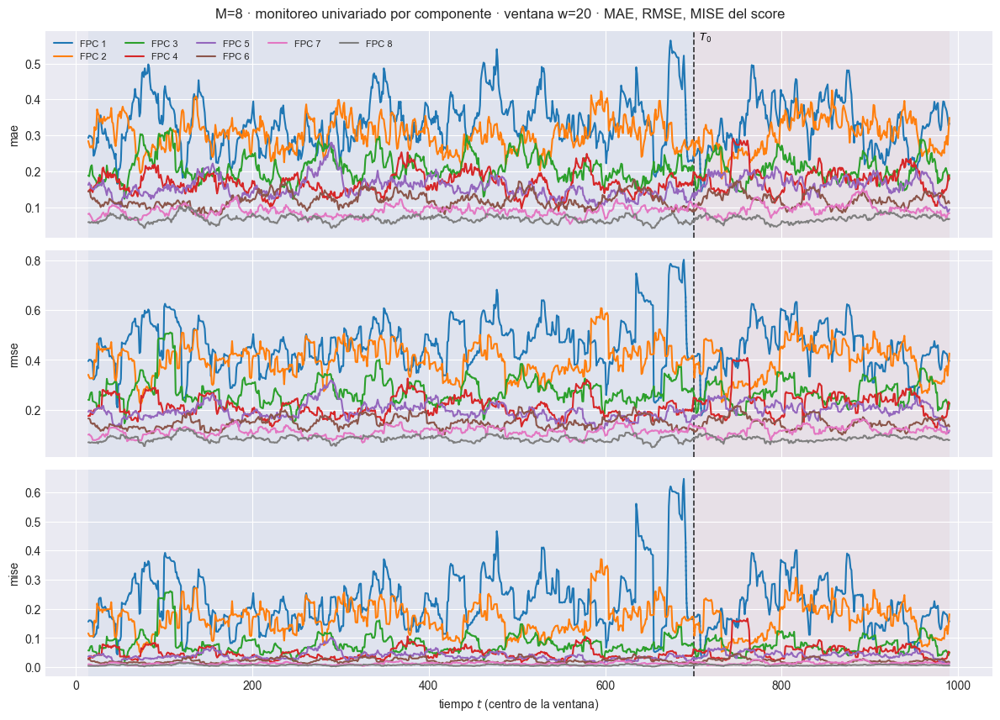

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1567  w=30 test=0.1729
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1953  w=30 test=0.2181
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.03815  w=30 test=0.04758
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m08\91_ventana_univariado_w30.png


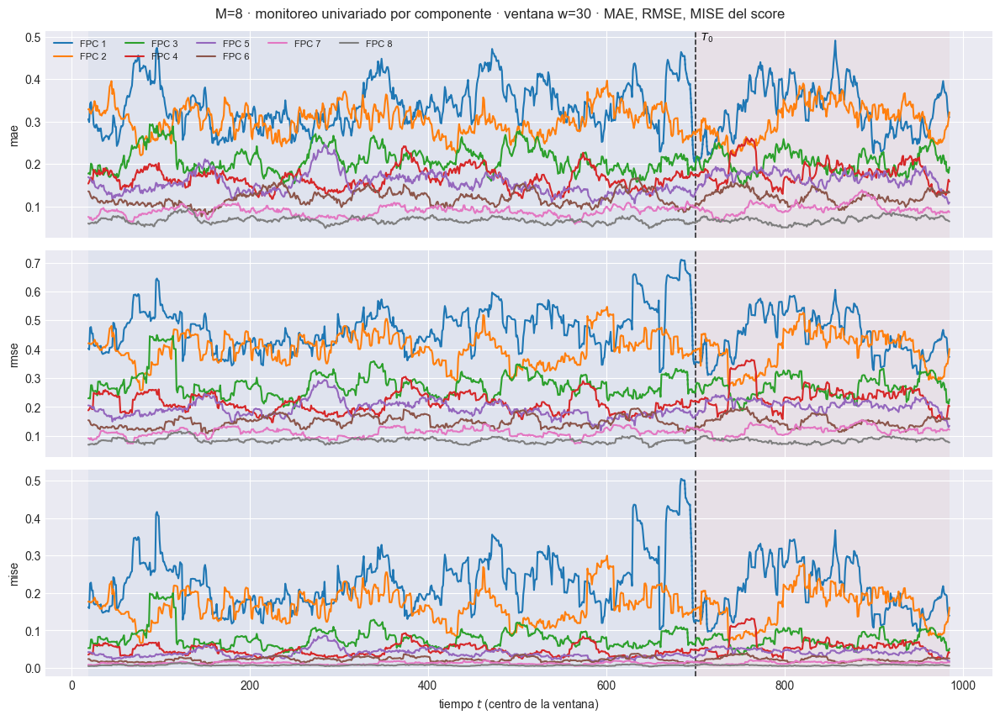

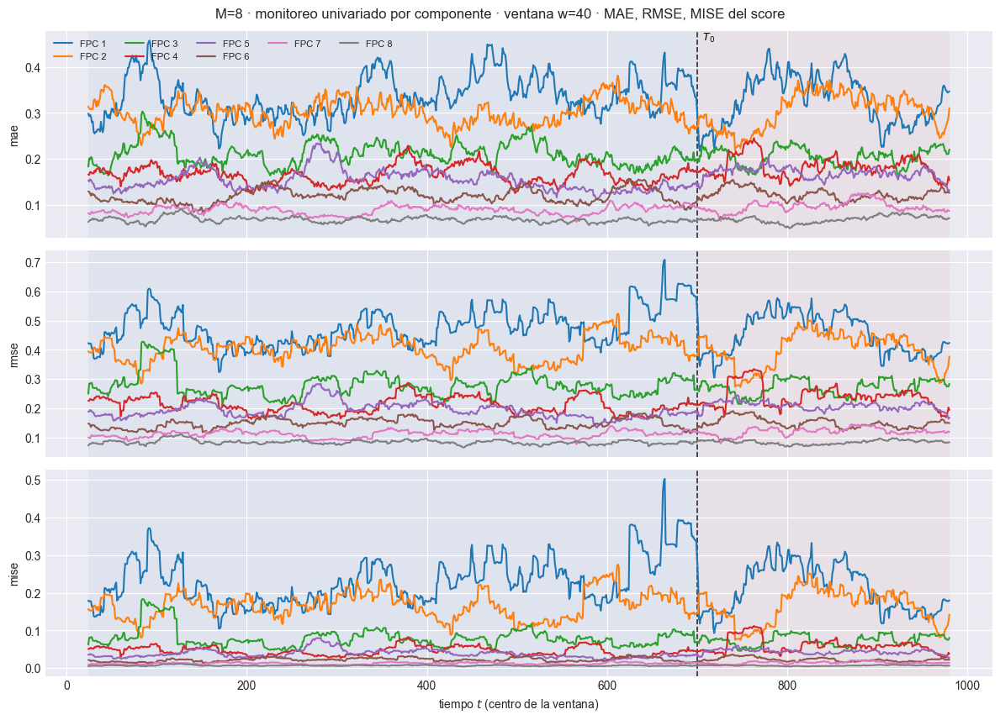

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.0s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.0s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.1s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.0s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.1s eta=0.0s  t=7

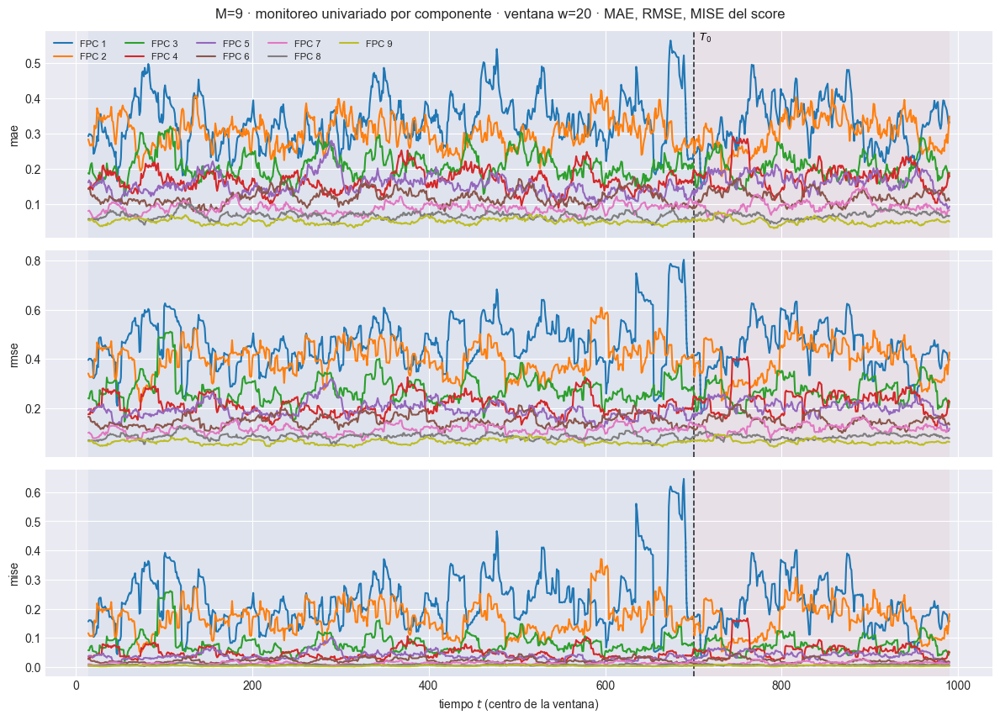

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1436  w=30 test=0.1599
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1805  w=30 test=0.2019
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.03257  w=30 test=0.04077
[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m09\91_ventana_univariado_w30.png


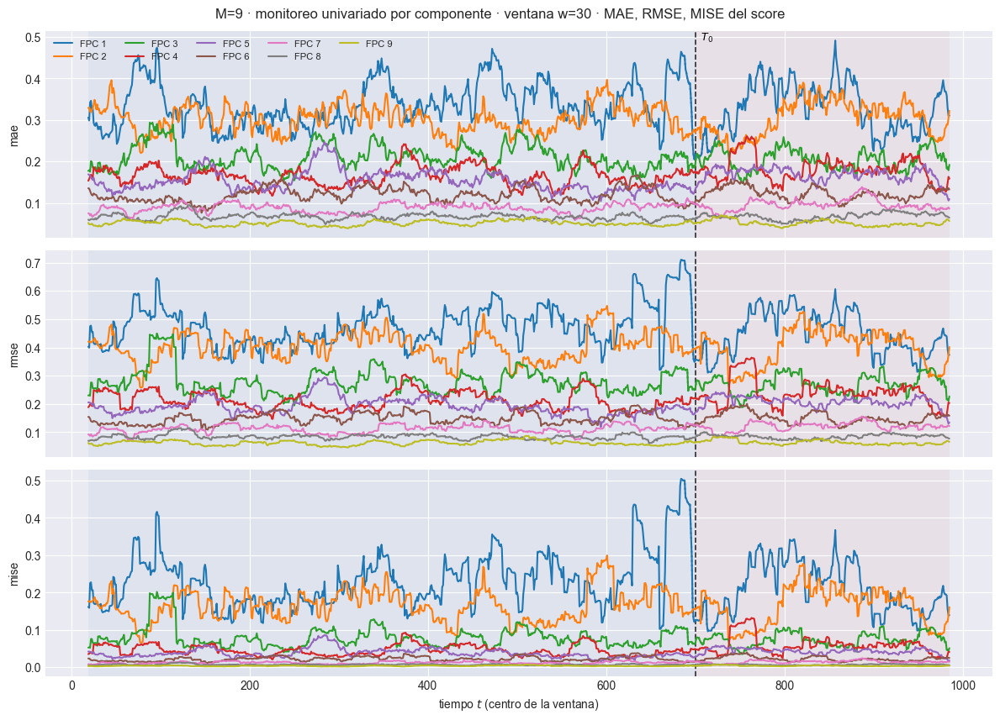

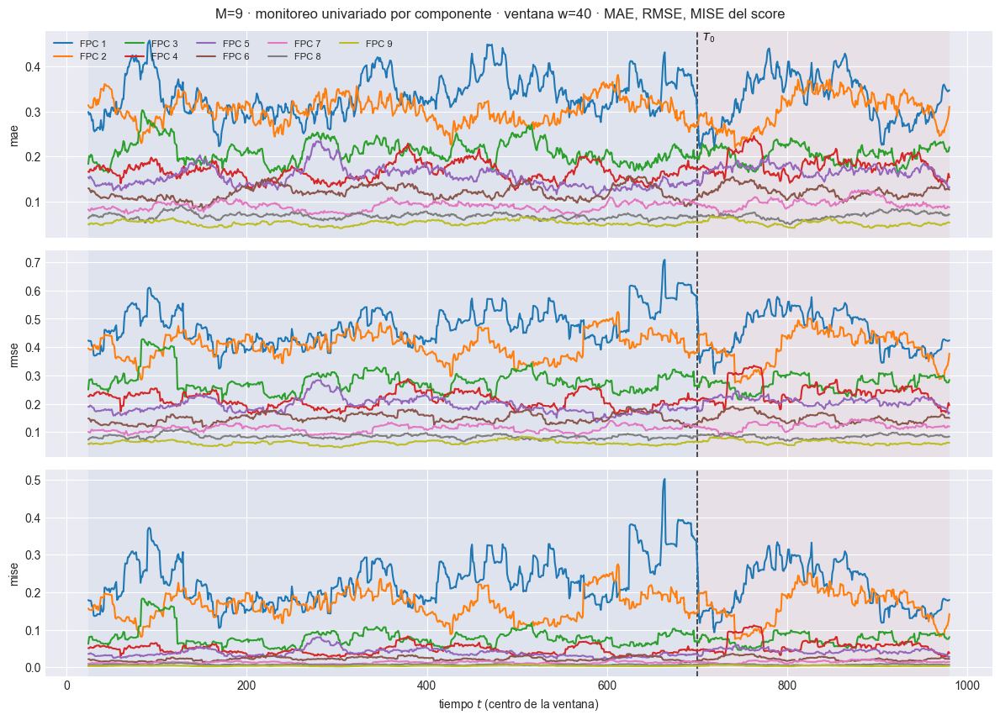

[ventana_movil_scores[FPC 1, w=30]] inicio (967 pasos)
  1/967 ( 0.1%) t=0.0s eta=1.1s  t=19 [train] rmse=0.4025
  48/967 ( 5.0%) t=0.0s eta=0.1s  t=66 [train] rmse=0.498
  96/967 ( 9.9%) t=0.0s eta=0.1s  t=114 [train] rmse=0.5062
  144/967 (14.9%) t=0.0s eta=0.1s  t=162 [train] rmse=0.385
  192/967 (19.9%) t=0.0s eta=0.1s  t=210 [train] rmse=0.3778
  240/967 (24.8%) t=0.0s eta=0.1s  t=258 [train] rmse=0.4316
  288/967 (29.8%) t=0.0s eta=0.1s  t=306 [train] rmse=0.4532
  336/967 (34.7%) t=0.0s eta=0.1s  t=354 [train] rmse=0.5486
  384/967 (39.7%) t=0.0s eta=0.1s  t=402 [train] rmse=0.4433
  432/967 (44.7%) t=0.0s eta=0.1s  t=450 [train] rmse=0.3746
  480/967 (49.6%) t=0.1s eta=0.1s  t=498 [train] rmse=0.4999
  528/967 (54.6%) t=0.1s eta=0.0s  t=546 [train] rmse=0.5271
  576/967 (59.6%) t=0.1s eta=0.0s  t=594 [train] rmse=0.4144
  624/967 (64.5%) t=0.1s eta=0.0s  t=642 [train] rmse=0.5844
  672/967 (69.5%) t=0.1s eta=0.0s  t=690 [train] rmse=0.6713
  720/967 (74.5%) t=0.1s eta=0.0s  t=7

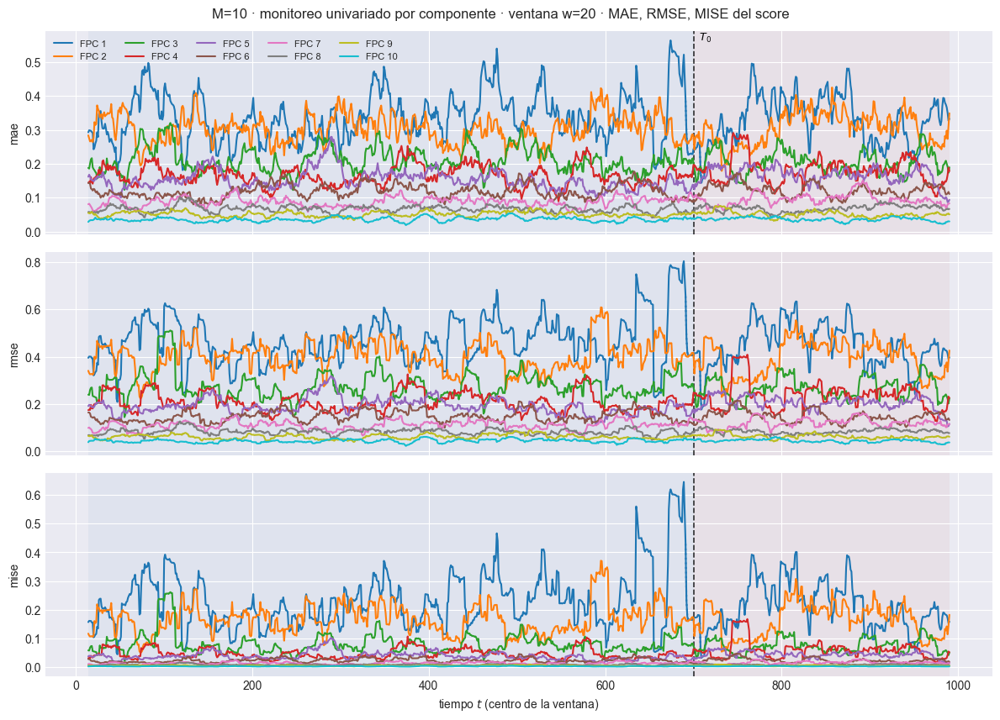

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1318  w=30 test=0.142
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1681  w=30 test=0.1772
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.02826  w=30 test=0.0314
[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m10\91_ventana_univariado_w30.png


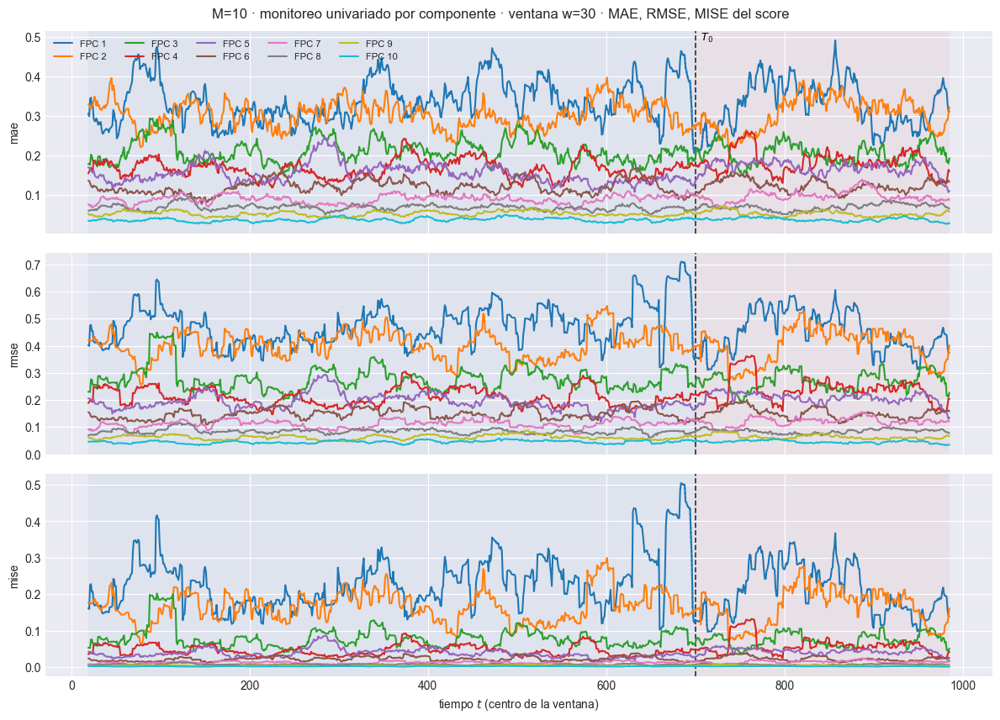

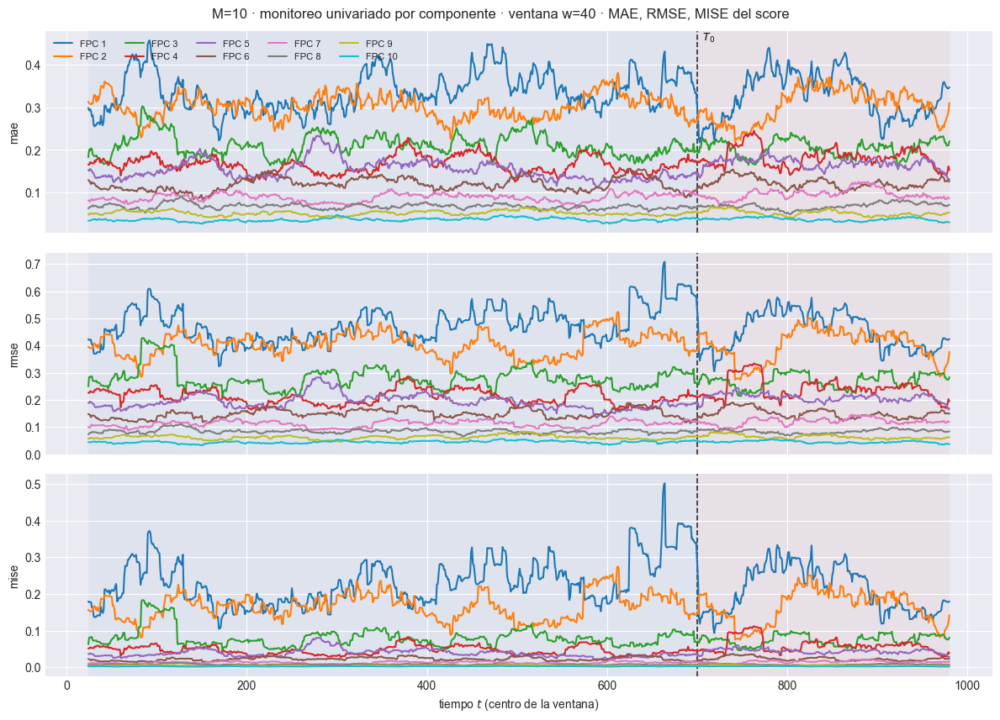

In [17]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

Las secciones anteriores miran la **curva**, que es el producto final. Ésta
mira el objeto que el muestreador predice de verdad: el score $\xi_{t,k}$ de
cada componente. La curva sale de propagarlos, así que un problema de
calibración que aquí se vea localizado en una componente queda, allá,
promediado con las demás y es mucho más difícil de atribuir.

| | qué muestra |
|---|---|
| **§10.1** | el intervalo de credibilidad de cada $\xi_k$ a lo largo del tiempo, con $\xi$ observado encima |
| **§10.2** | las métricas de ese intervalo: PICP, MPIW, Winkler, ACE — globales por bloque y sobre la ventana móvil, un panel por ancho |
| **§10.3** | dispersión $\hat\xi$ contra $\xi$ con la diagonal, componente a componente |

La banda es `li_s`/`ls_s`, los cuantiles muestrales de la predictiva por score
que §3 ya calculó: es **la misma** de la que sale la banda funcional, antes de
propagarla. No se vuelve a muestrear nada.


### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

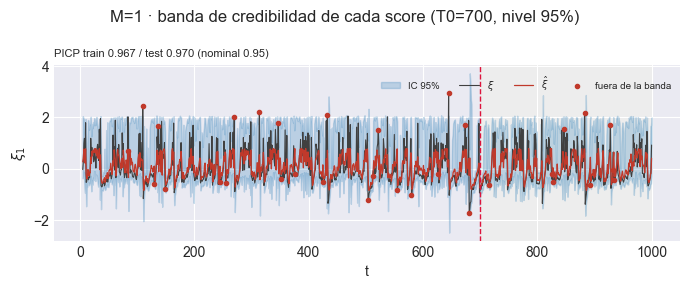

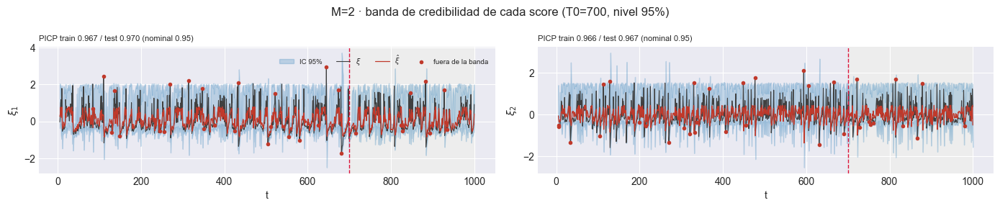

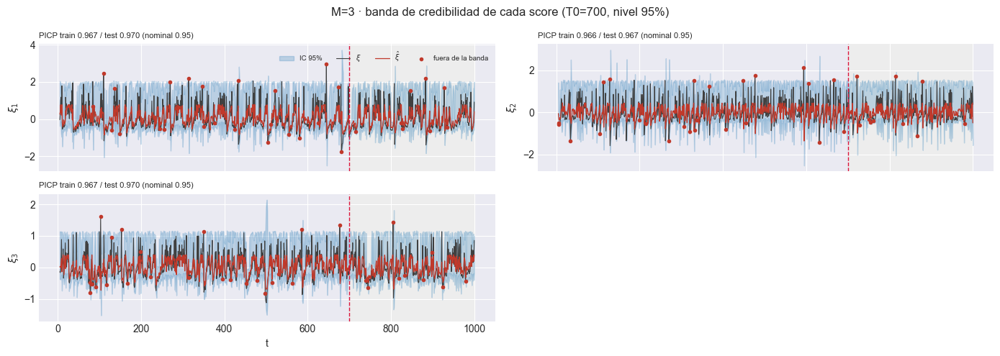

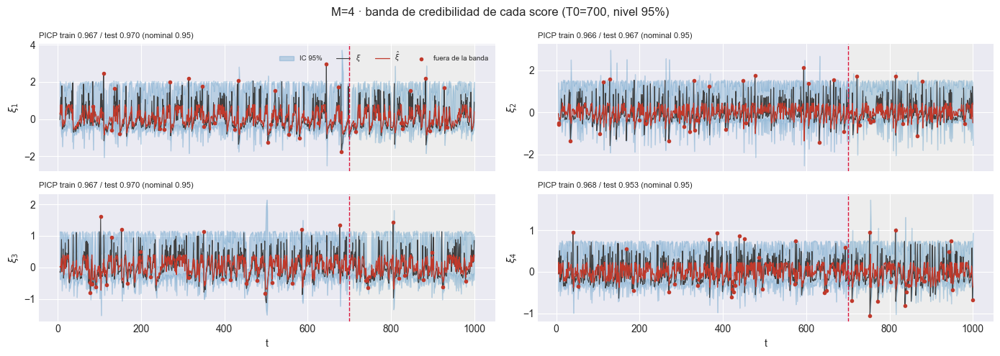

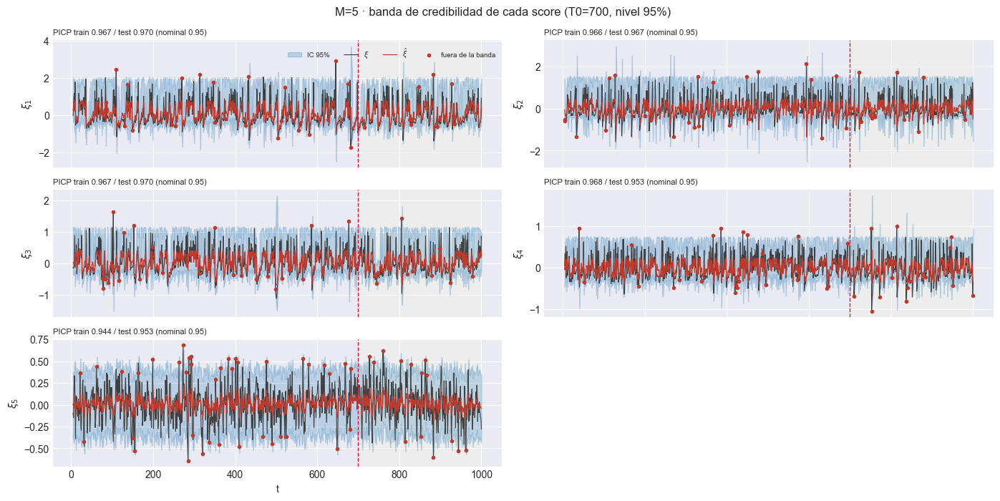

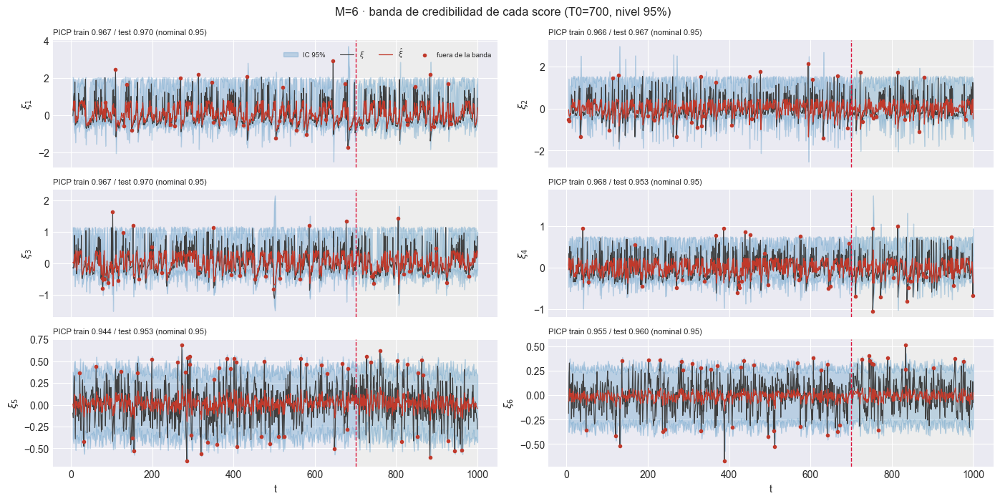

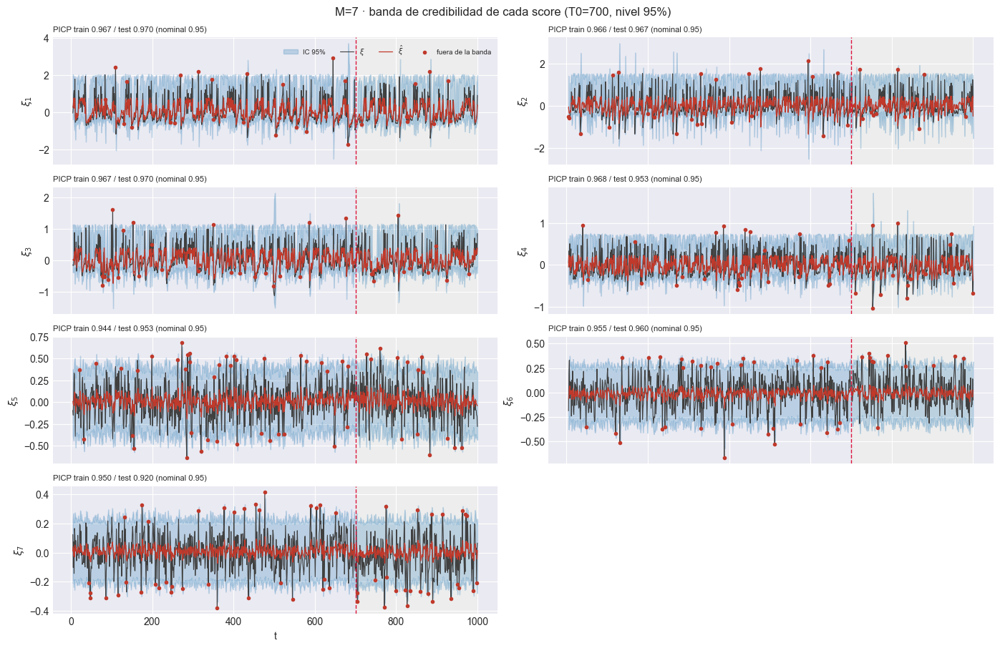

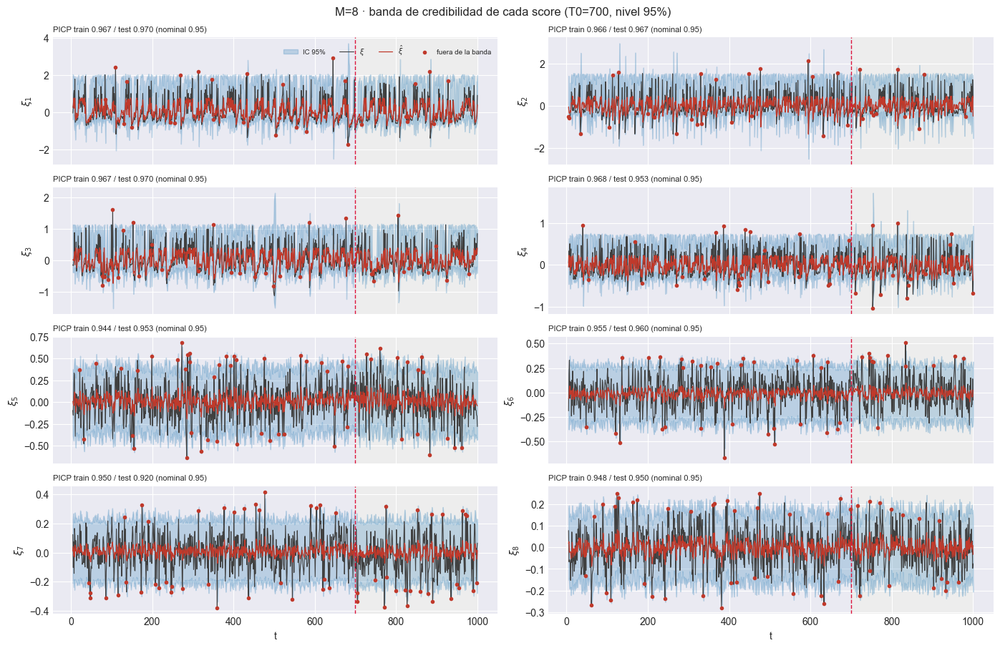

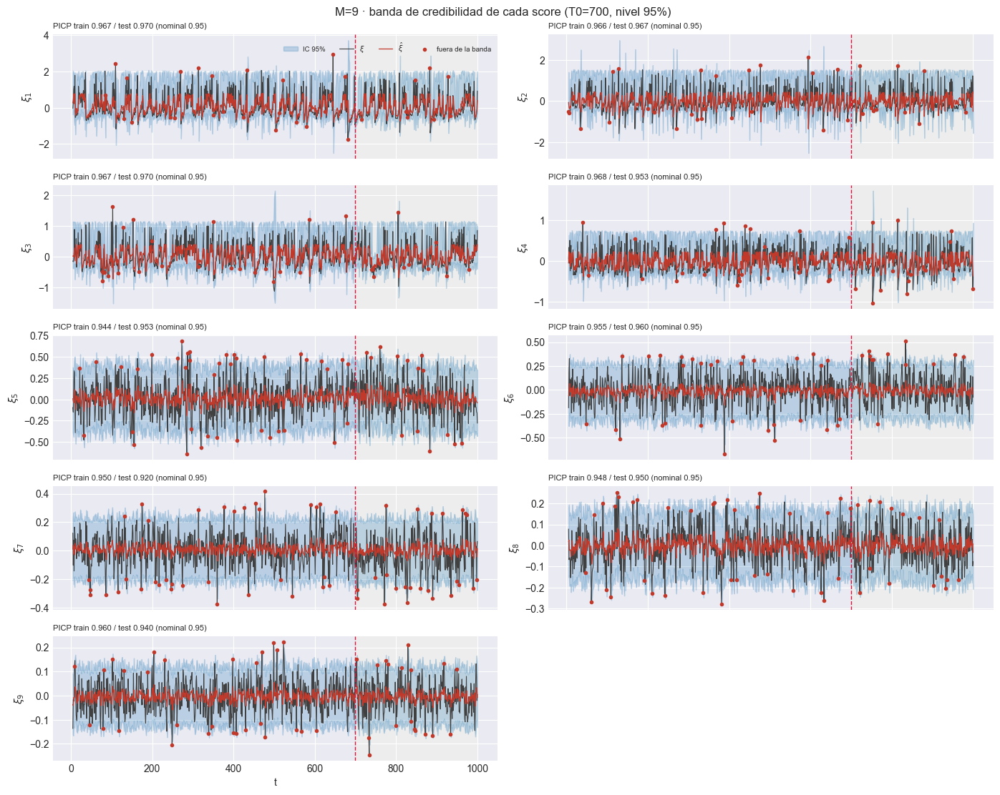

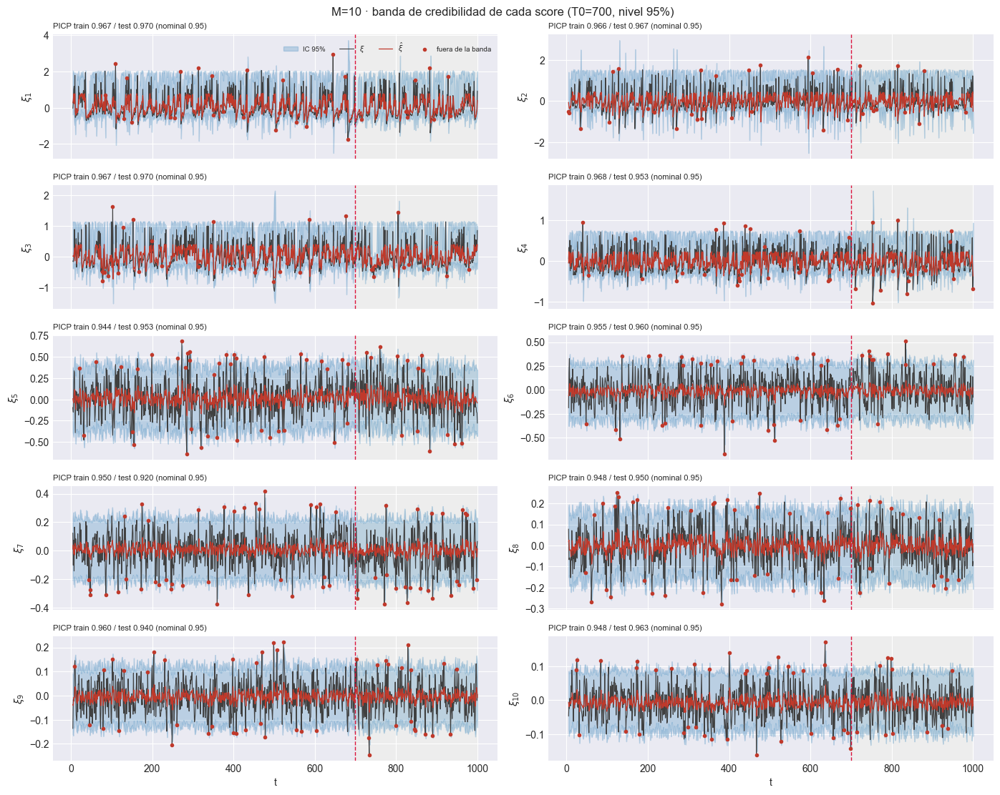

In [18]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

Las mismas cuatro cifras del Bloque B, pero por componente y en la escala del
score: **PICP** (fracción de orígenes cubiertos), **MPIW** (ancho medio),
**Winkler** (regla de puntuación que penaliza ancho y fallo a la vez) y
**ACE** = PICP − nominal, que es el signo de la miscalibración: negativo es
subcobertura.

Primero la lectura global por bloque; después la evolución sobre la ventana
móvil, **un panel por ancho**, con el mismo criterio de §4 y §5.


OK ninguna componente se aleja mas de 0.1 del nominal en test.


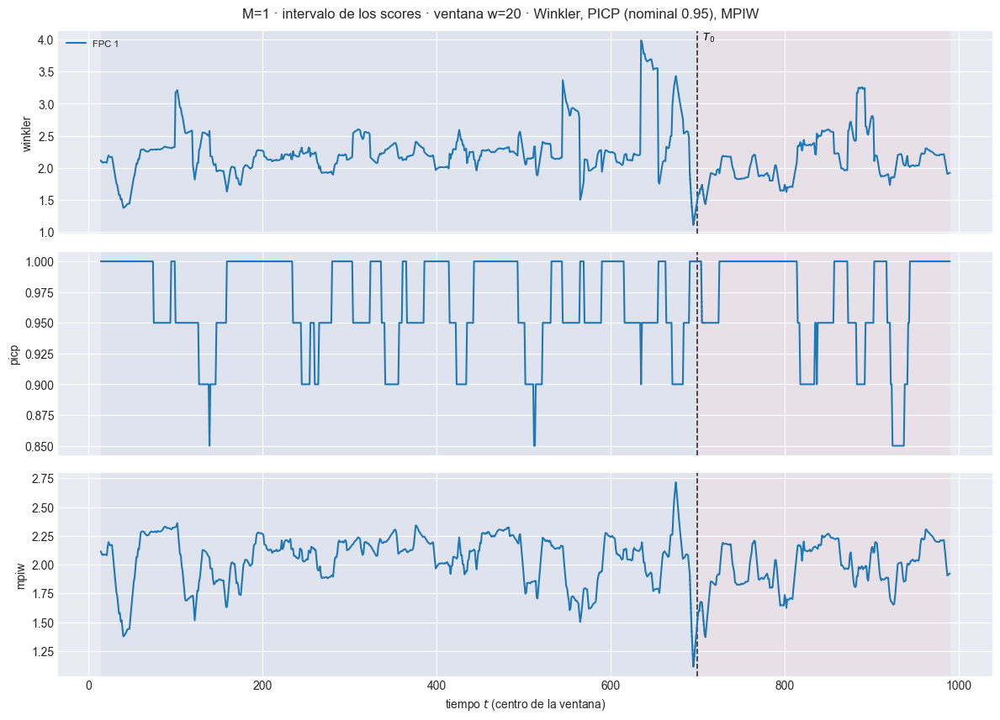

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=2.223  w=30 test=2.059
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=2.087  w=30 test=1.984
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m01\93_ventana_scores_intervalo_w30.png


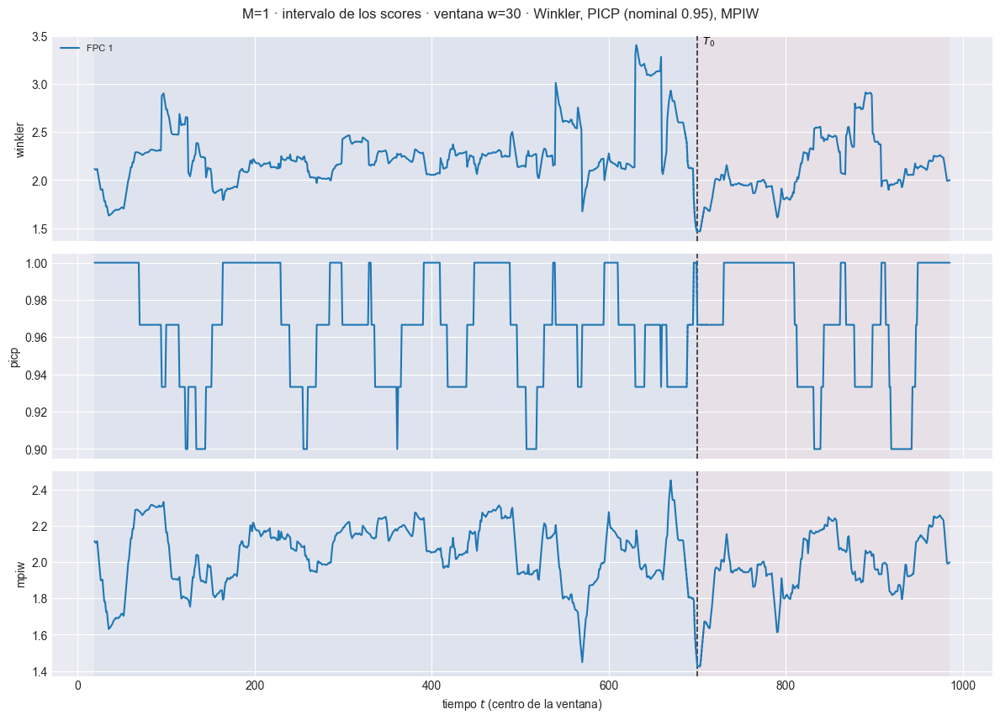

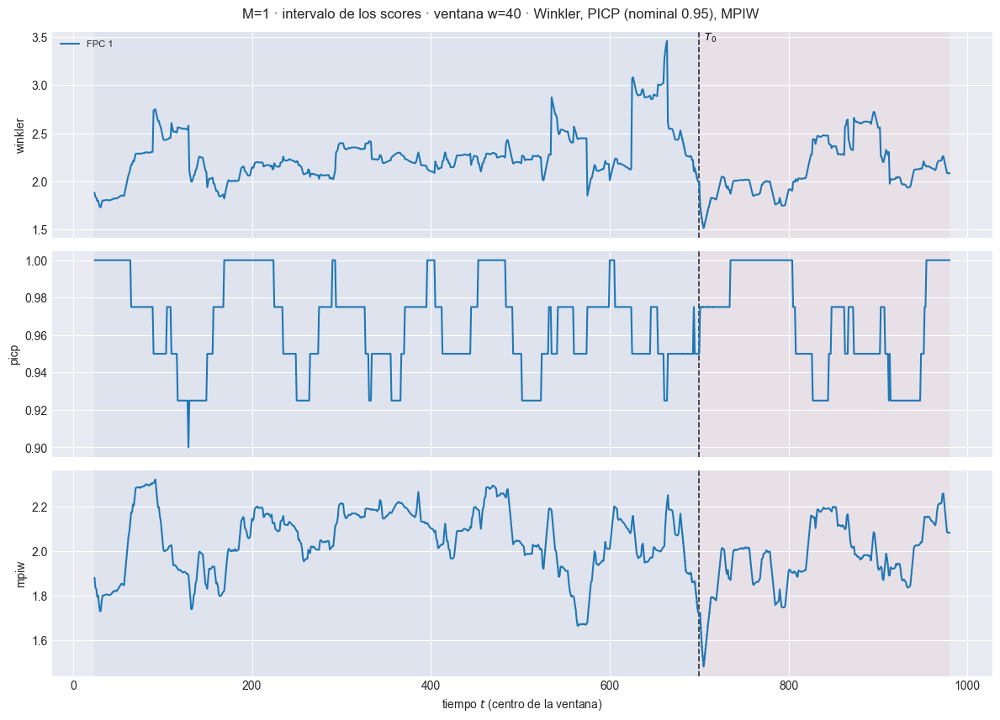

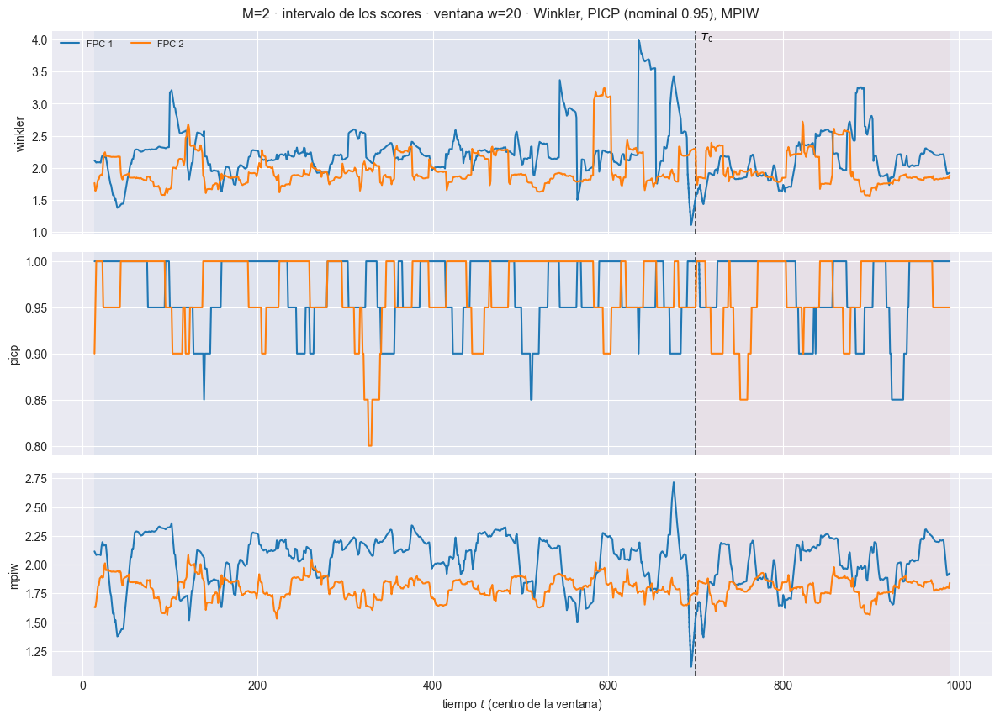

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=2.095  w=30 test=1.996
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.888  w=30 test=1.855
[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m02\93_ventana_scores_intervalo_w30.png


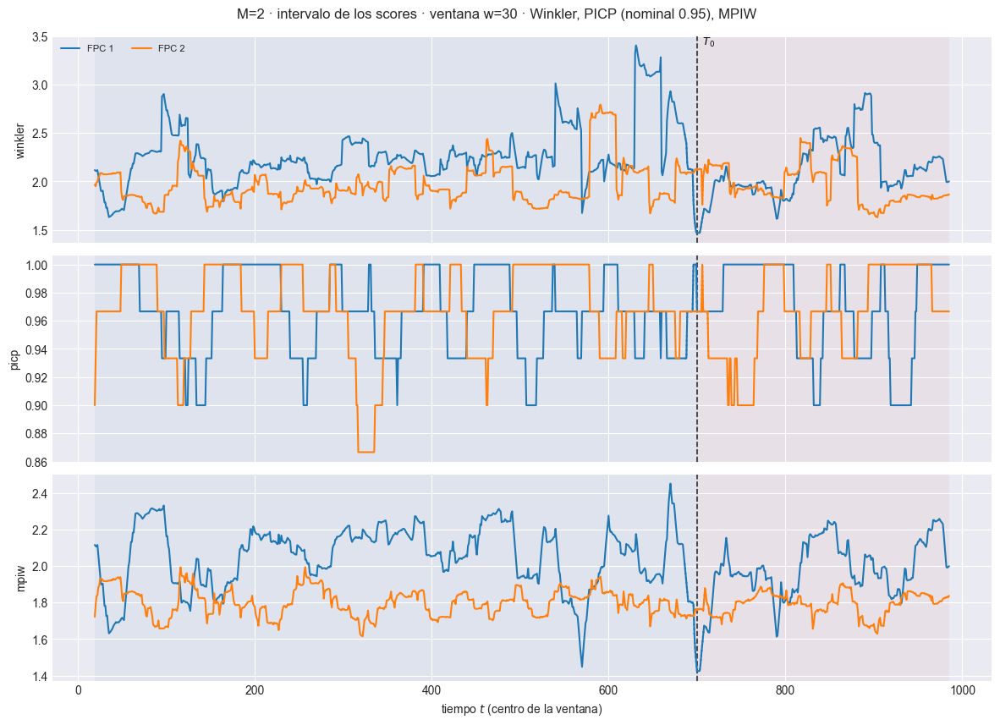

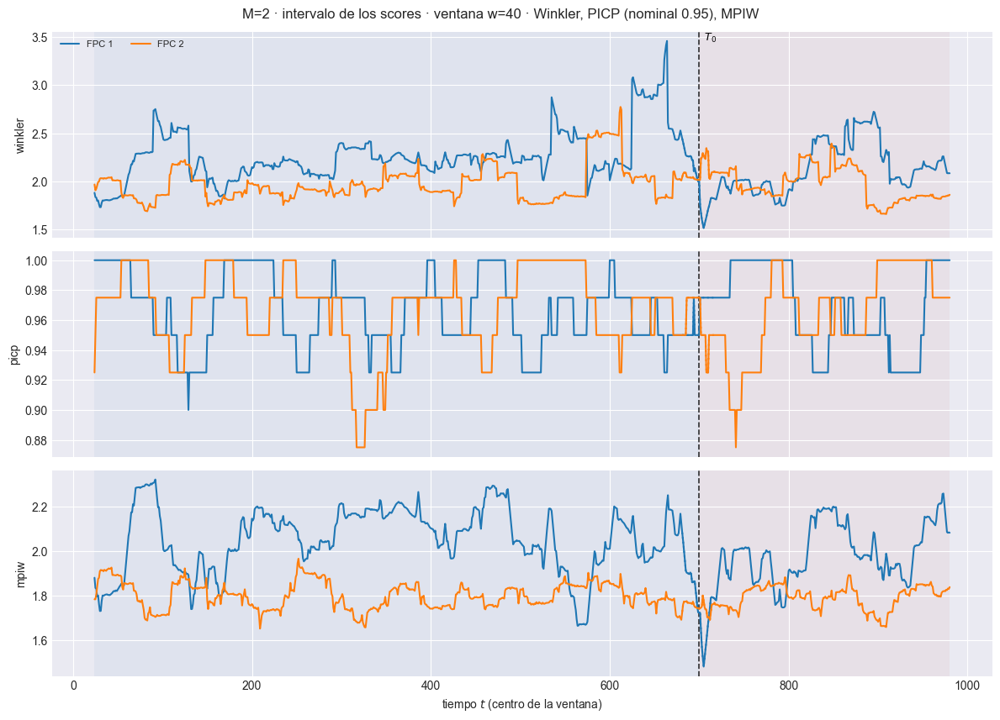

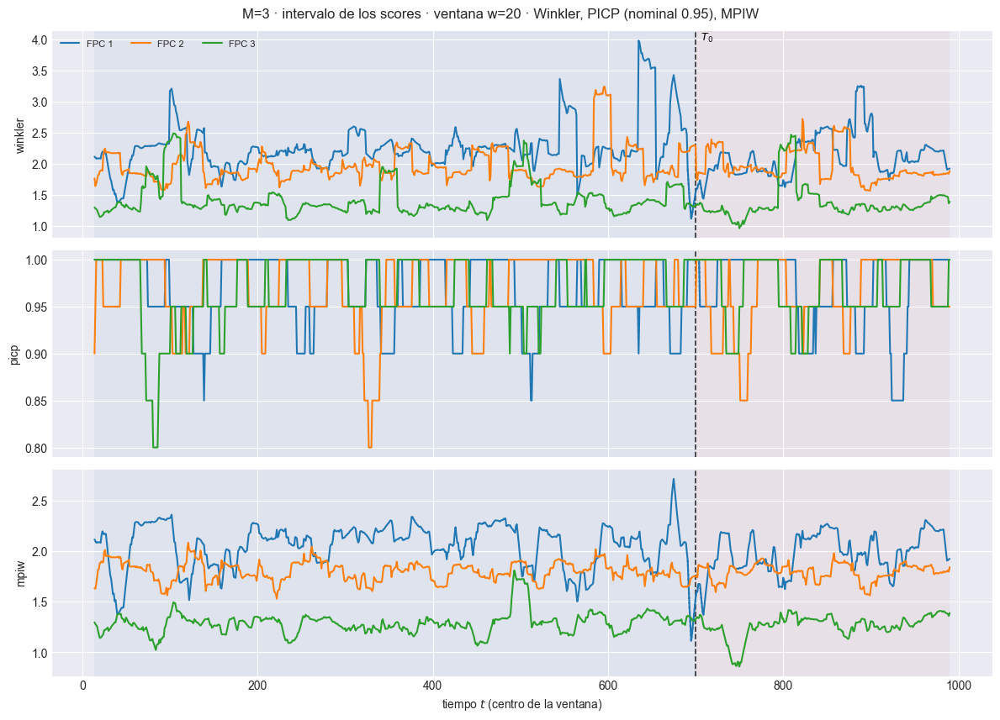

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.902  w=30 test=1.883
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.791  w=30 test=1.798
[plot_ventana_movil] listo: 3 pasos en 1.0s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m03\93_ventana_scores_intervalo_w30.png


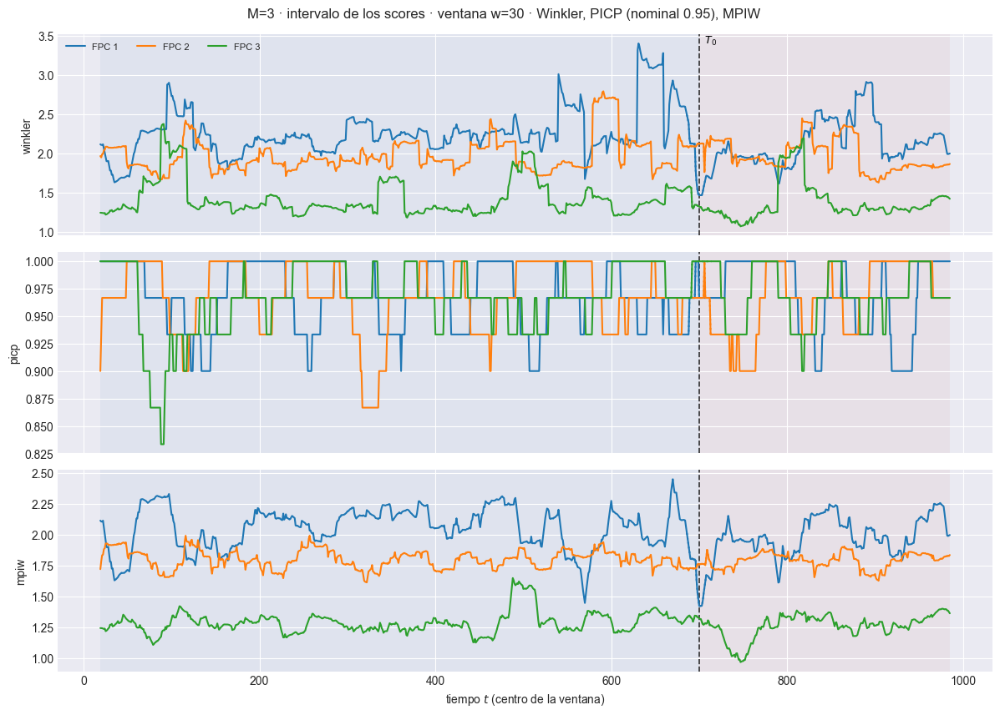

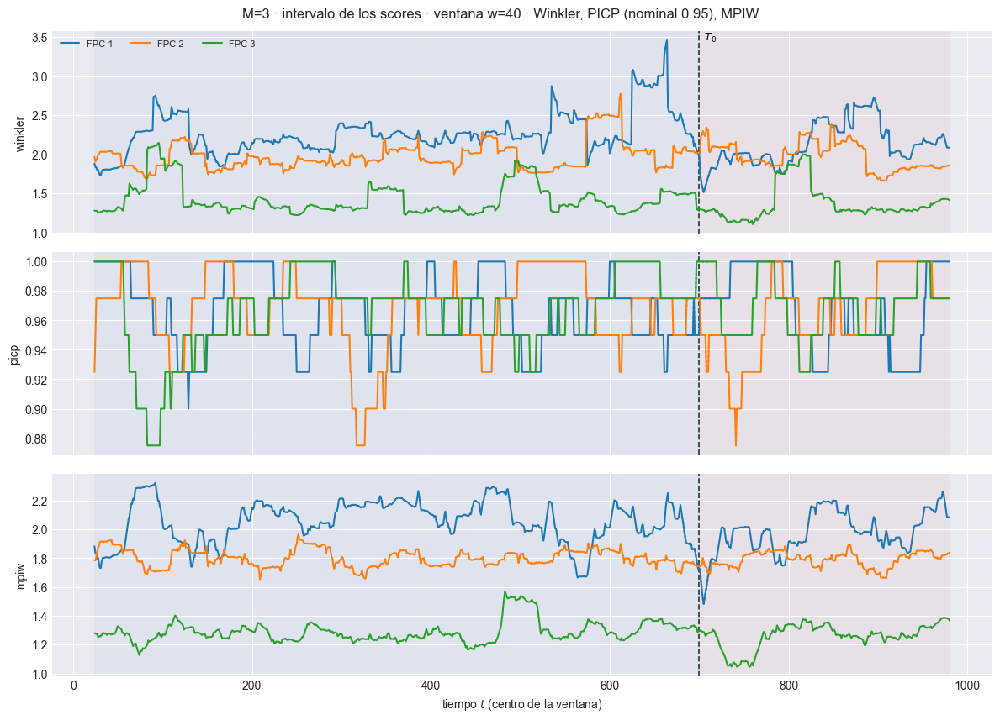

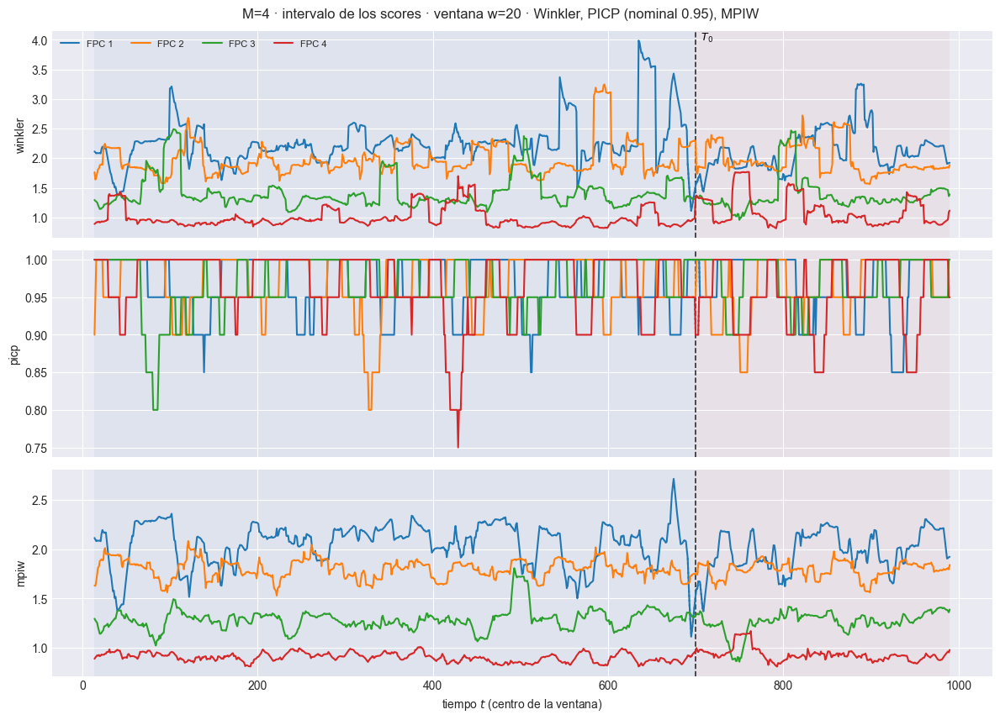

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=1.729  w=30 test=1.725
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.606  w=30 test=1.508
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m04\93_ventana_scores_intervalo_w30.png


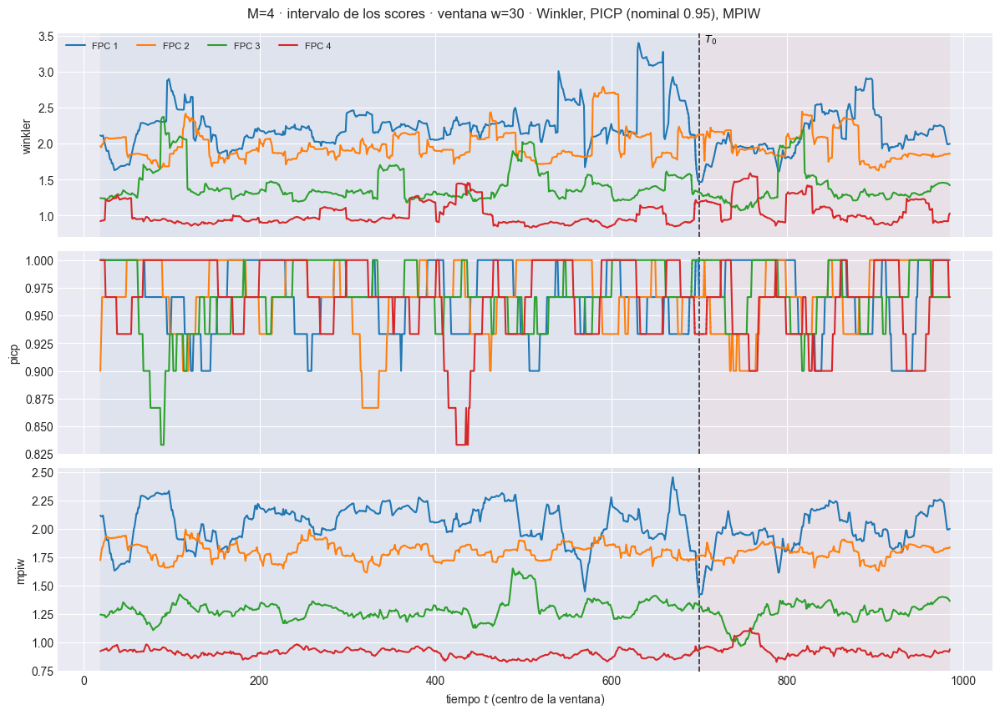

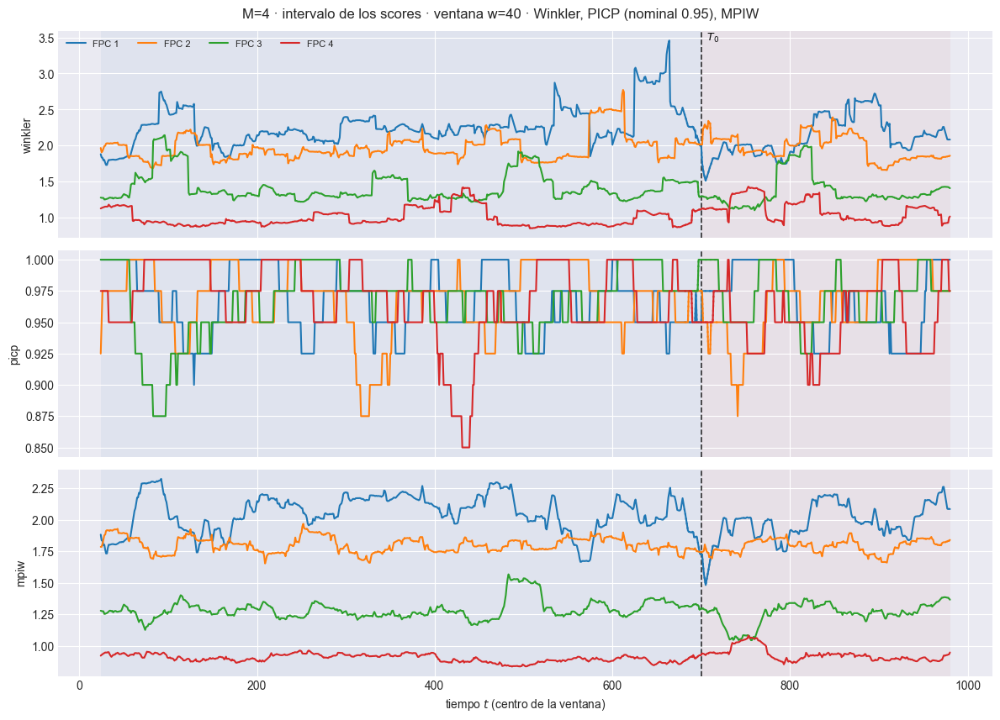

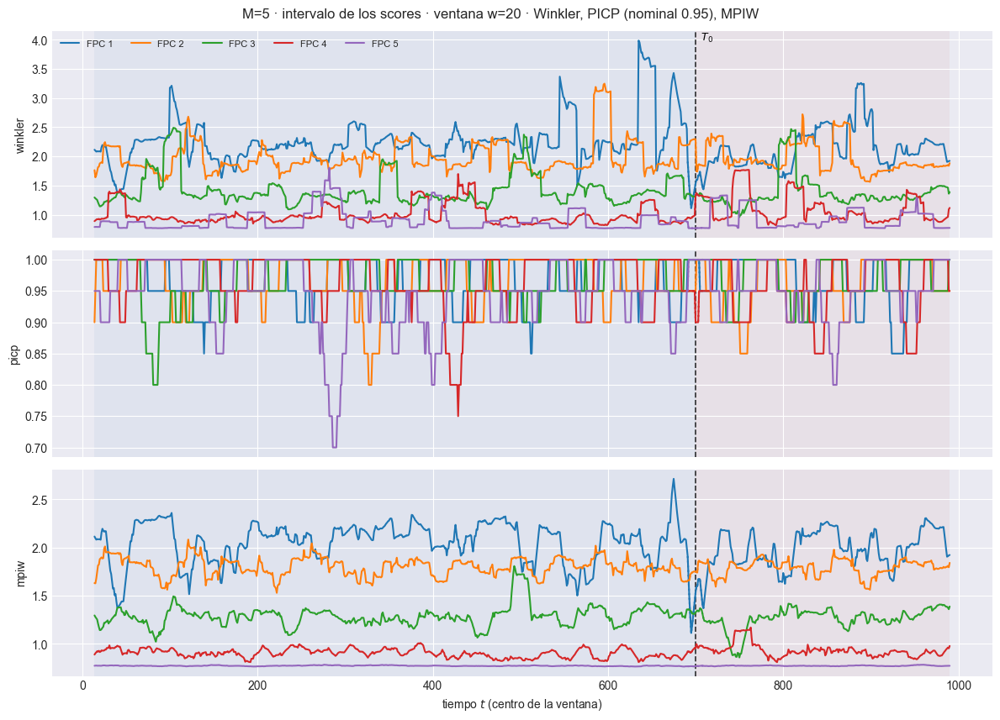

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.349  w=30 test=1.328
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.28  w=30 test=1.274
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m05\93_ventana_scores_intervalo_w30.png


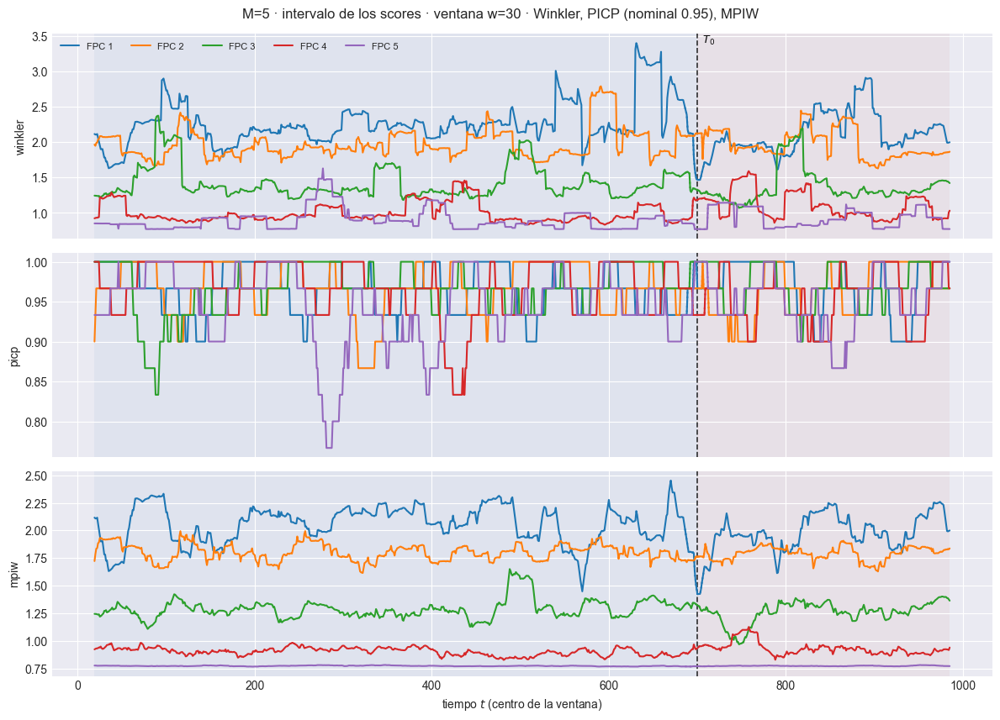

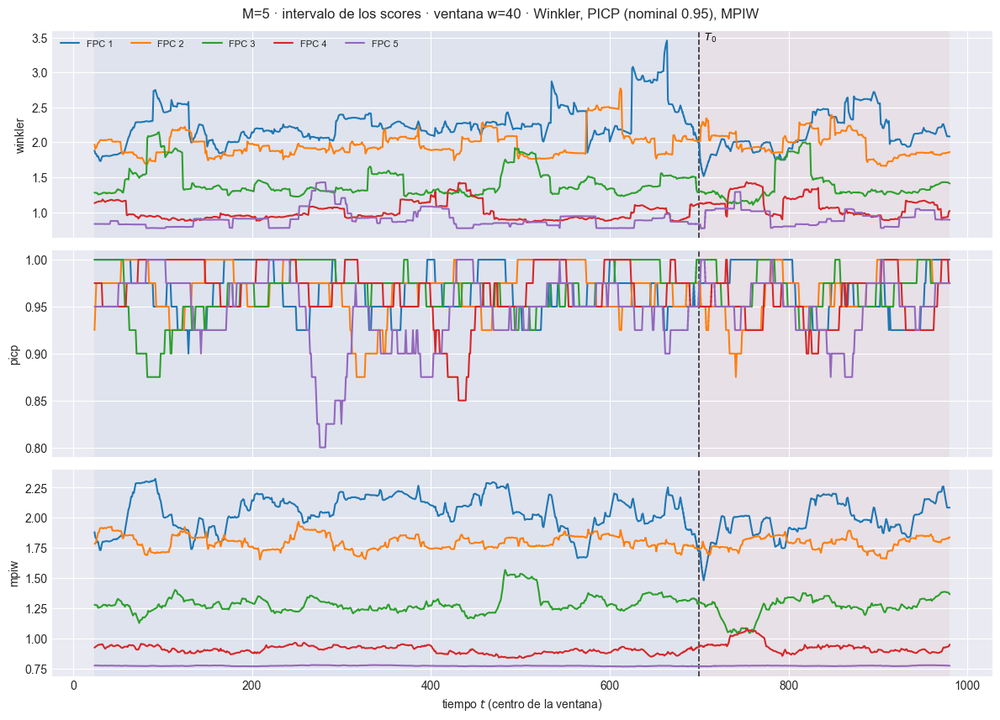

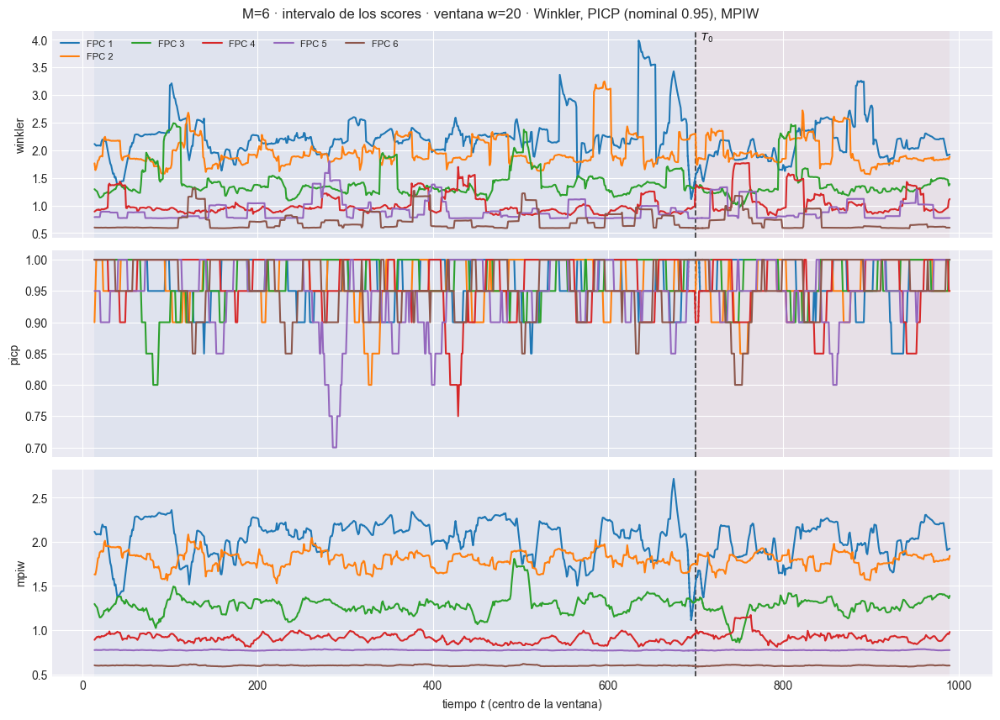

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=1.238  w=30 test=1.243
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.046  w=30 test=1.068
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m06\93_ventana_scores_intervalo_w30.png


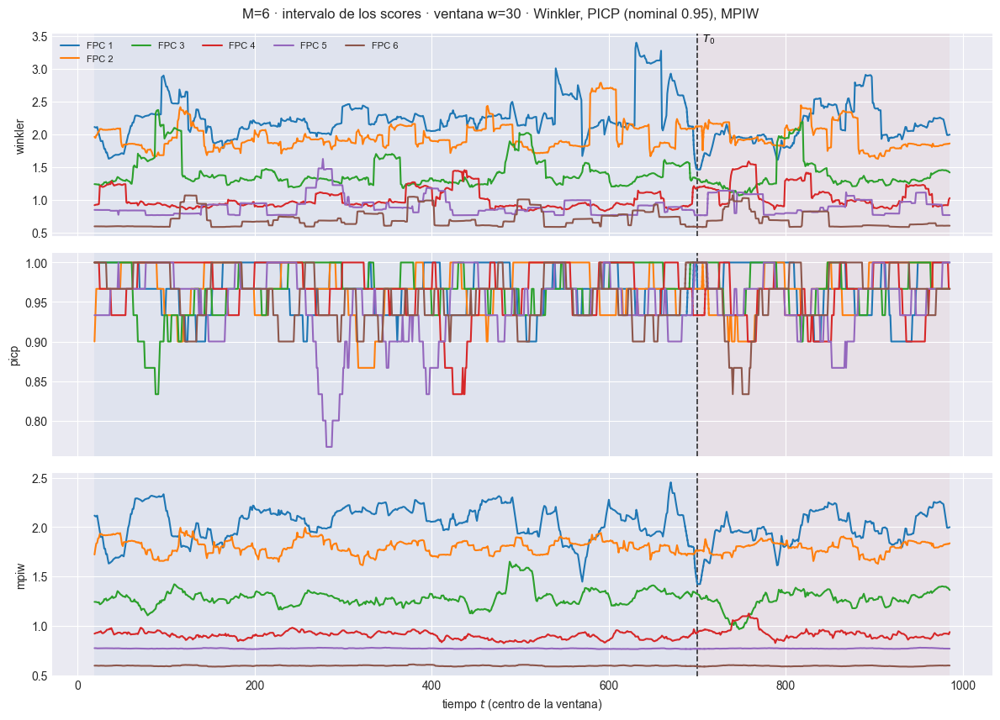

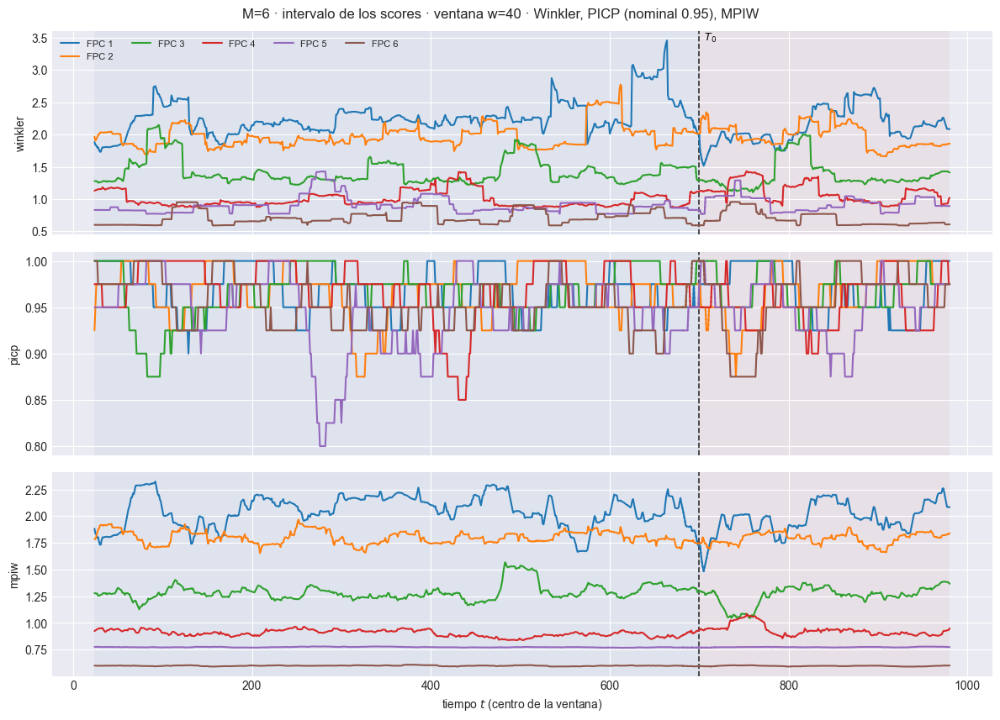

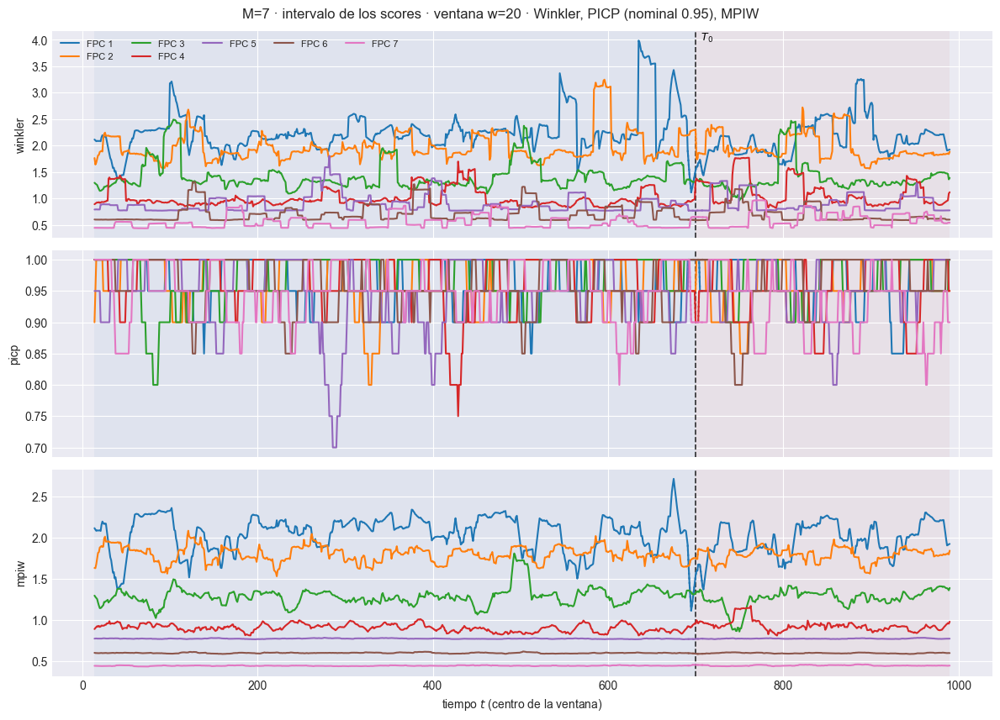

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.9946  w=30 test=1.115
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.9058  w=30 test=0.9214
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m07\93_ventana_scores_intervalo_w30.png


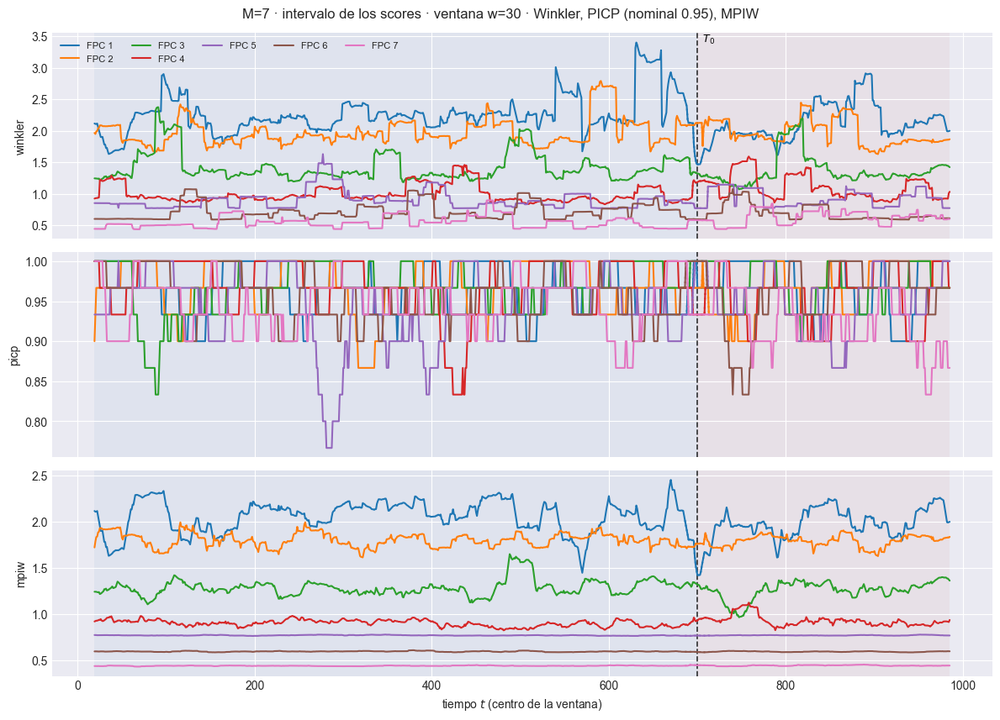

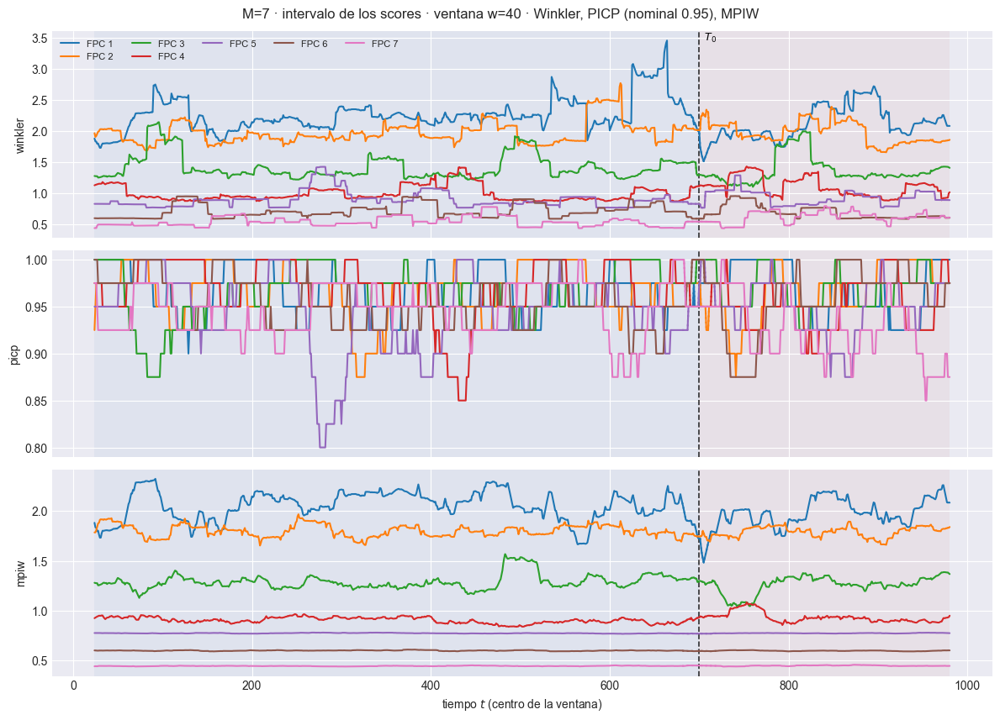

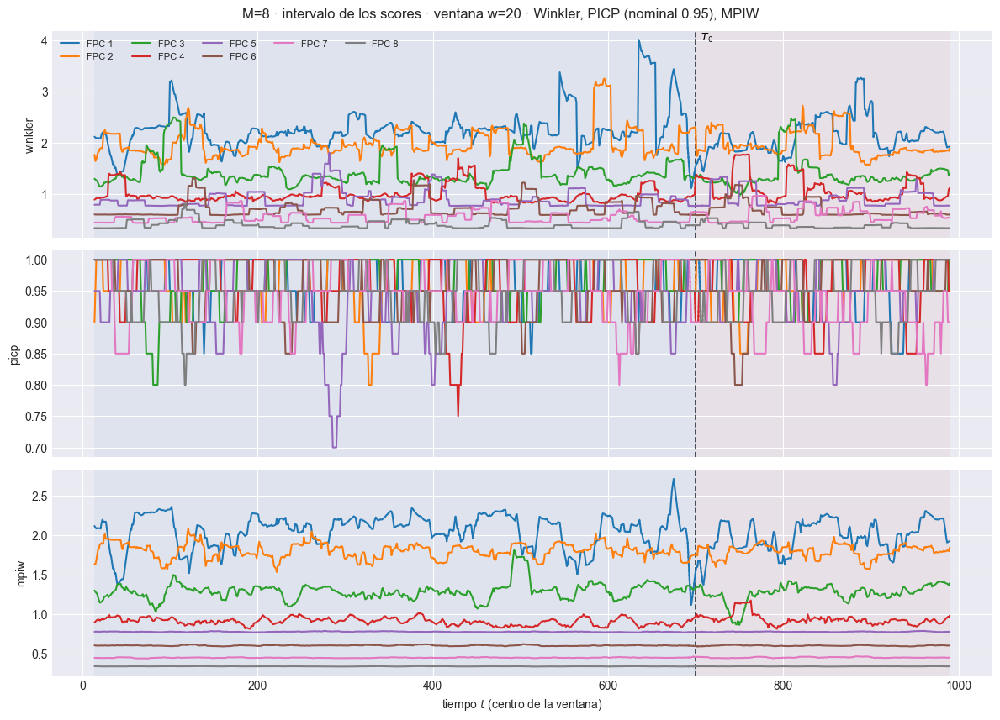

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.9308  w=30 test=0.9916
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.8049  w=30 test=0.8054
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m08\93_ventana_scores_intervalo_w30.png


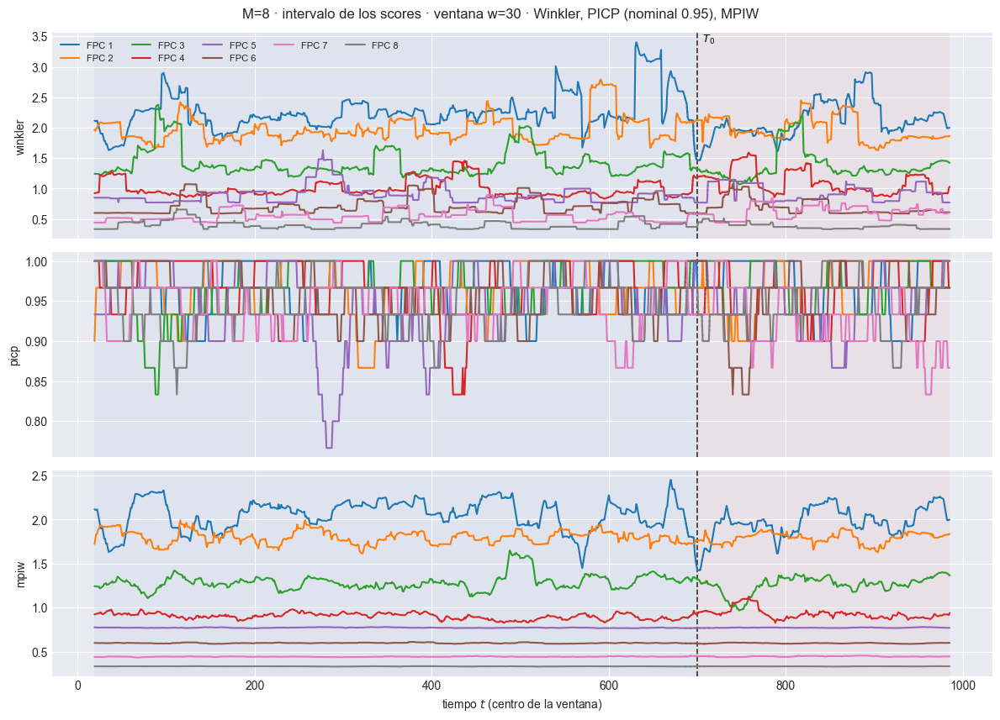

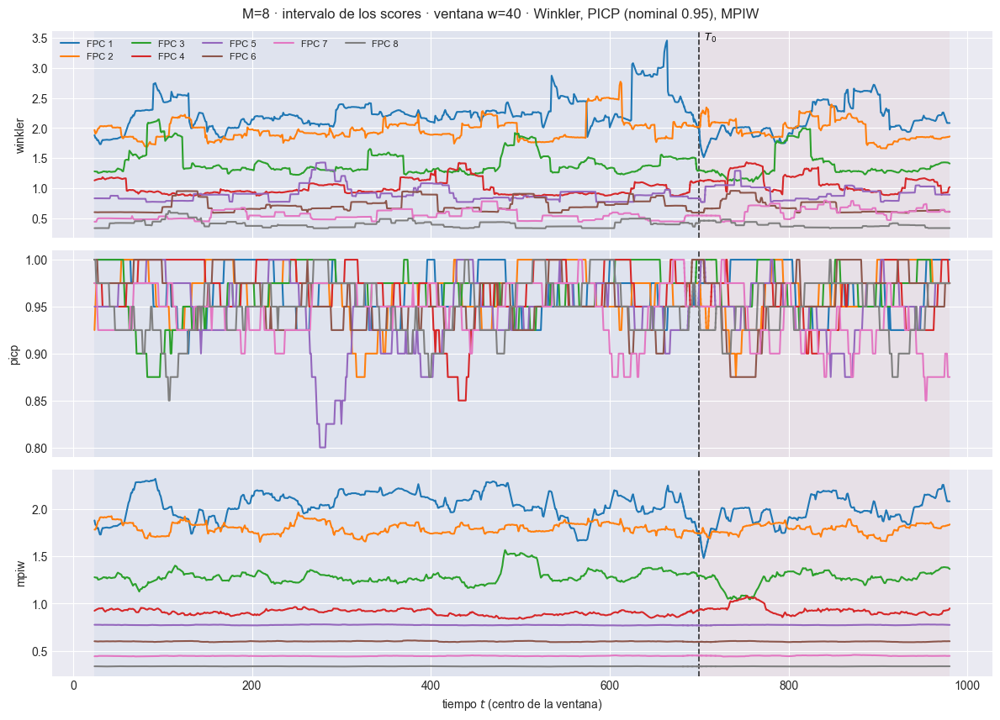

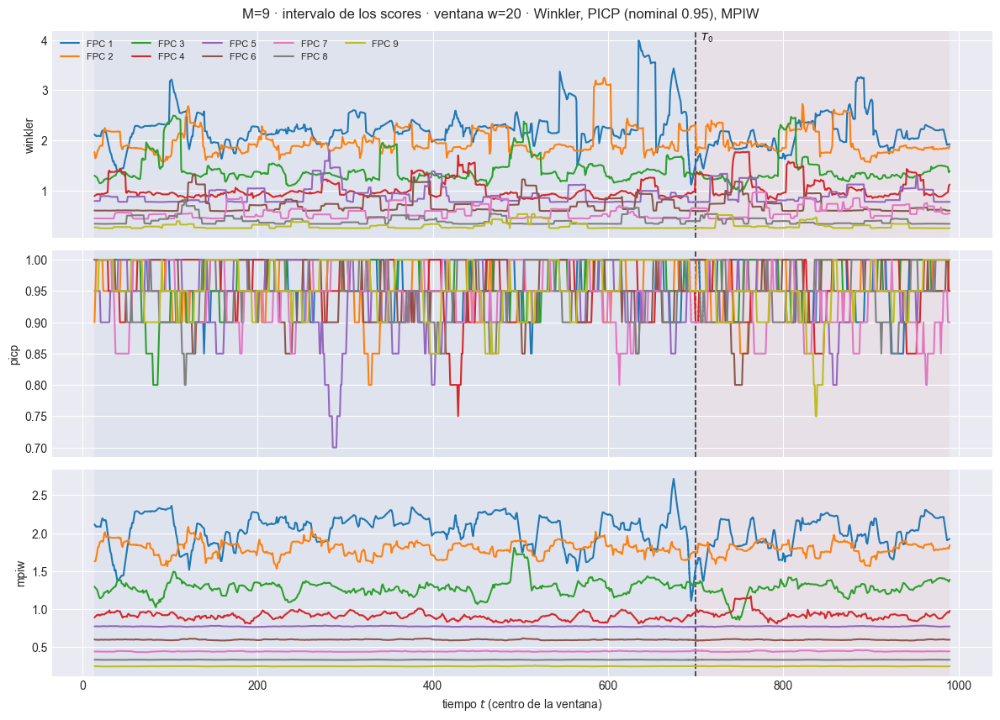

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.8763  w=30 test=0.9065
  2/3 (66.7%) t=0.1s eta=0.1s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.2s eta=0.0s  mpiw: w=30 train=0.773  w=30 test=0.7734
[plot_ventana_movil] listo: 3 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m09\93_ventana_scores_intervalo_w30.png


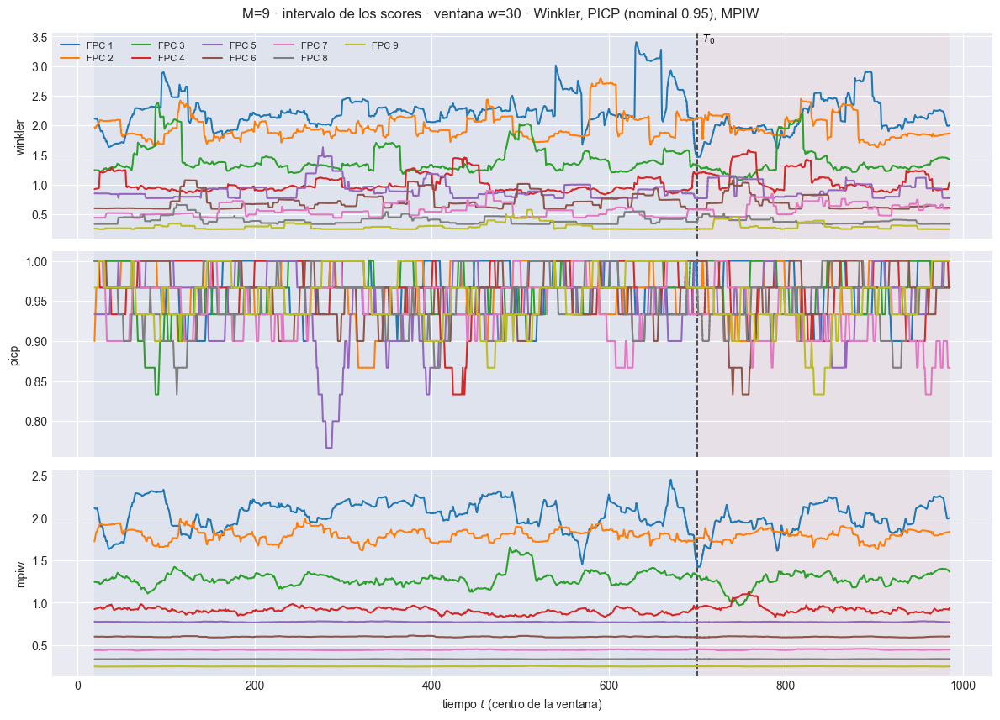

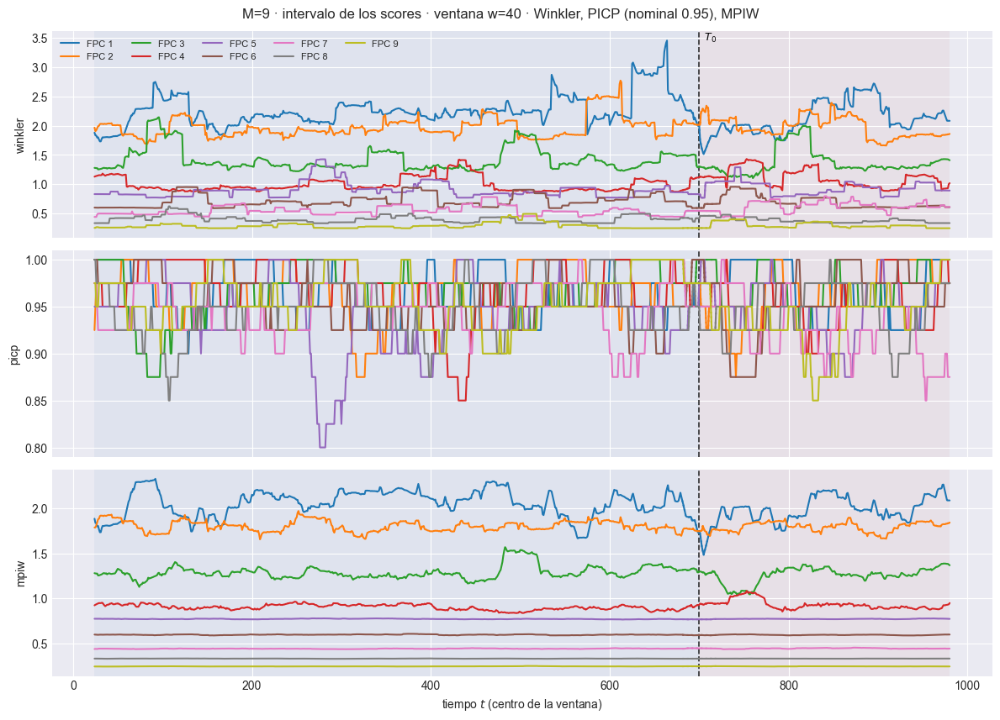

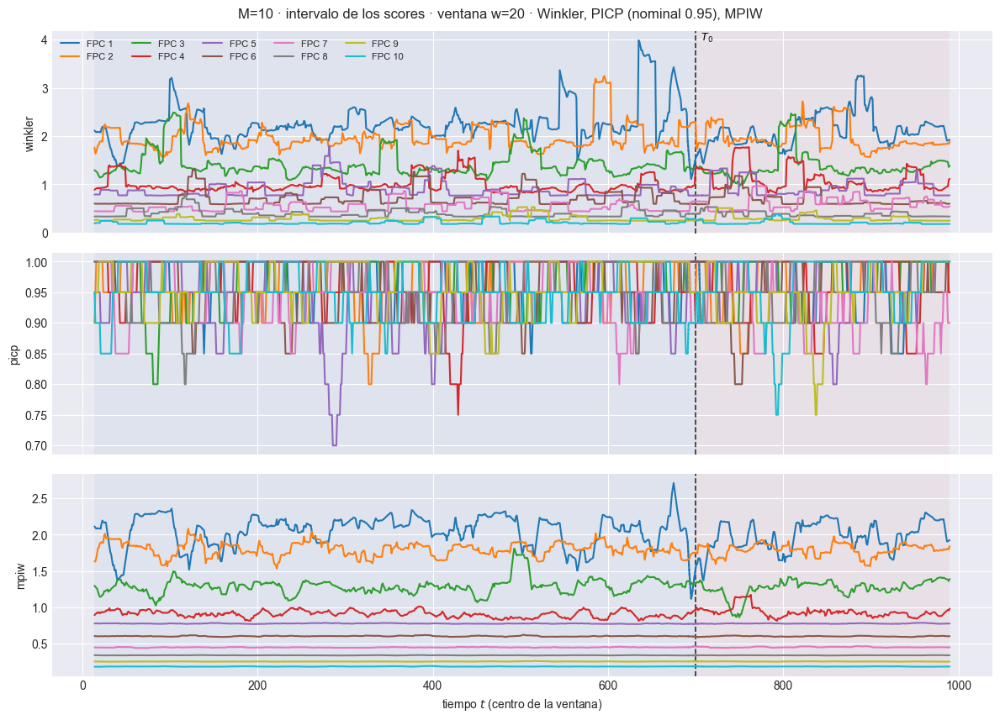

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.7781  w=30 test=0.802
  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.6898  w=30 test=0.6876
[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_m10\93_ventana_scores_intervalo_w30.png


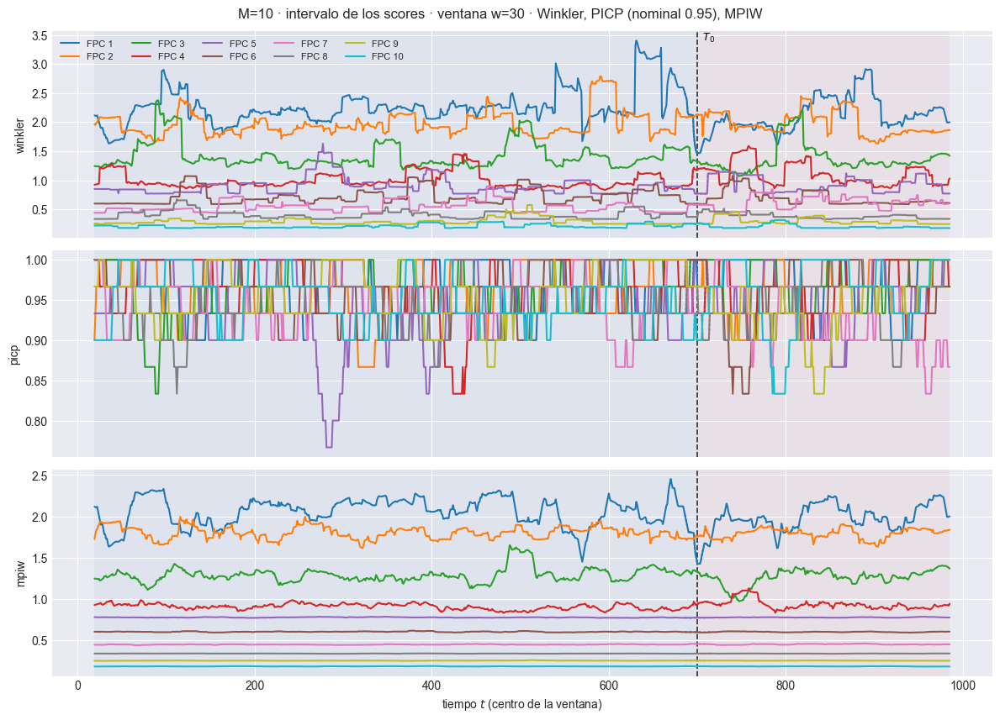

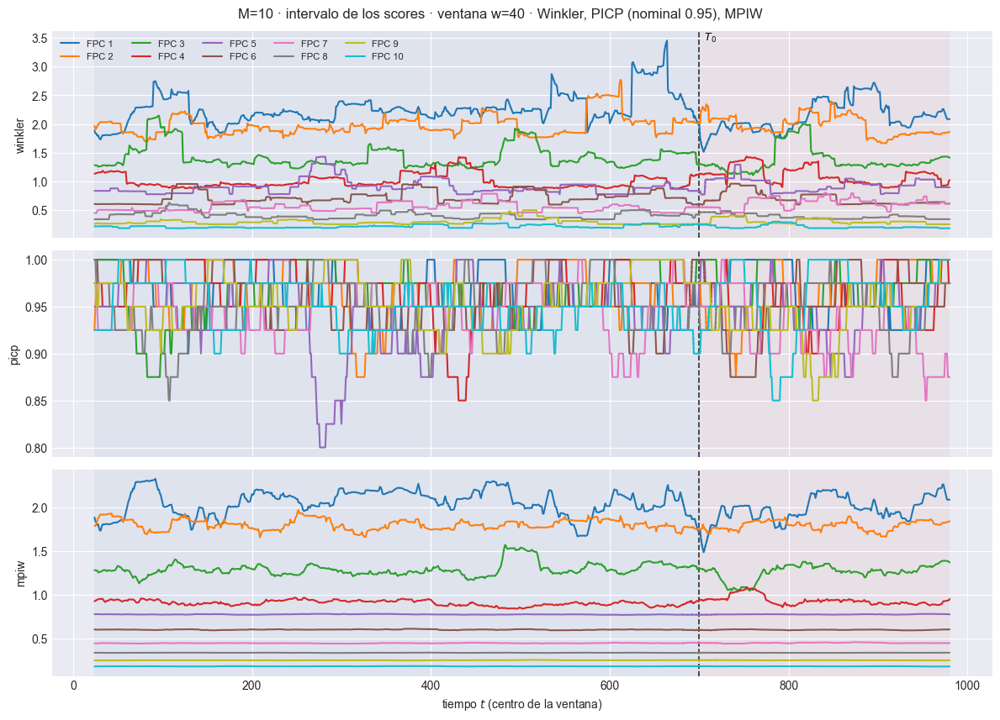

In [19]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente, con la diagonal $y=x$. Tres cosas se leen de golpe:

- **la nube pegada a la diagonal** es predicción; la nube **horizontal**
  —$\hat\xi$ casi constante mientras $\xi$ varía— es el modelo prediciendo la
  media incondicional, que es lo que pasa cuando la componente no tiene
  dinámica que capturar;
- **la pendiente** de la recta ajustada: menor que 1 es encogimiento hacia la
  media, que es el comportamiento esperado de un predictor bayesiano y no un
  defecto;
- **las barras** son el intervalo de credibilidad de una submuestra, de modo
  que se ve si los puntos que se salen de la diagonal están cubiertos.

Los puntos de train y de test van con marcador distinto: si la nube de test se
descuelga de la diagonal mientras la de train no, es deriva del bloque de
prueba y no error de ajuste.


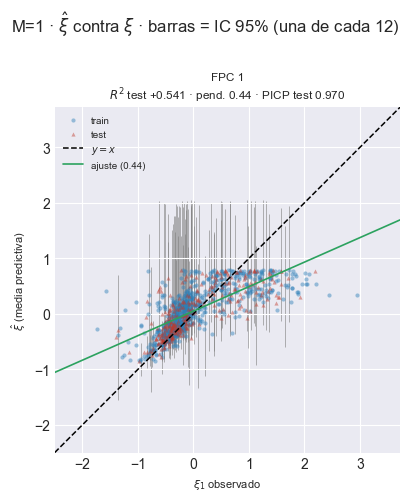

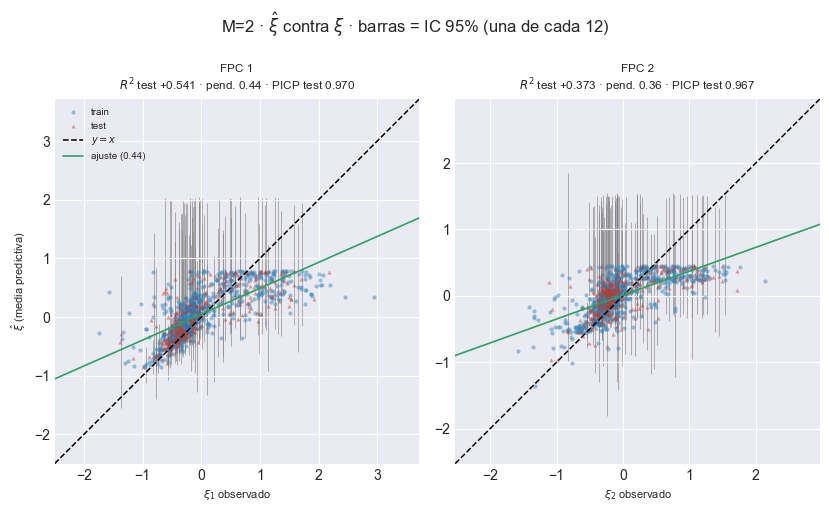

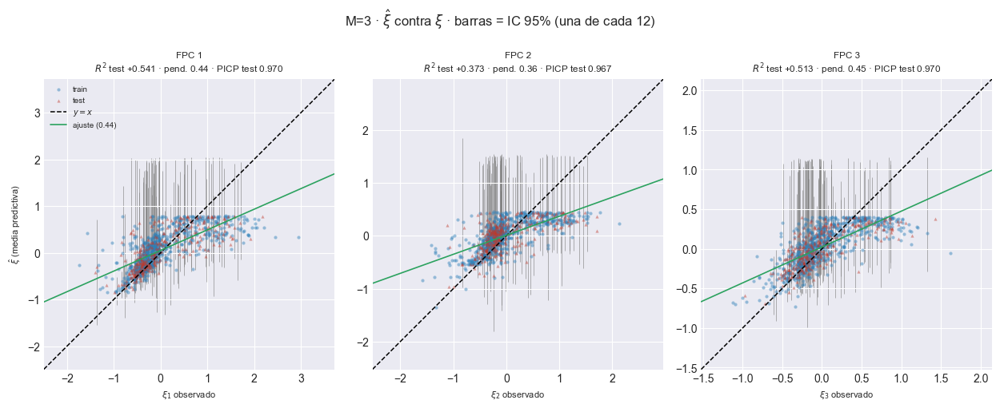

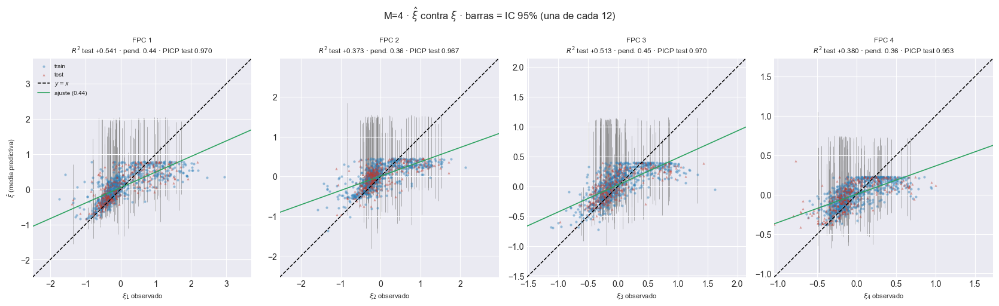

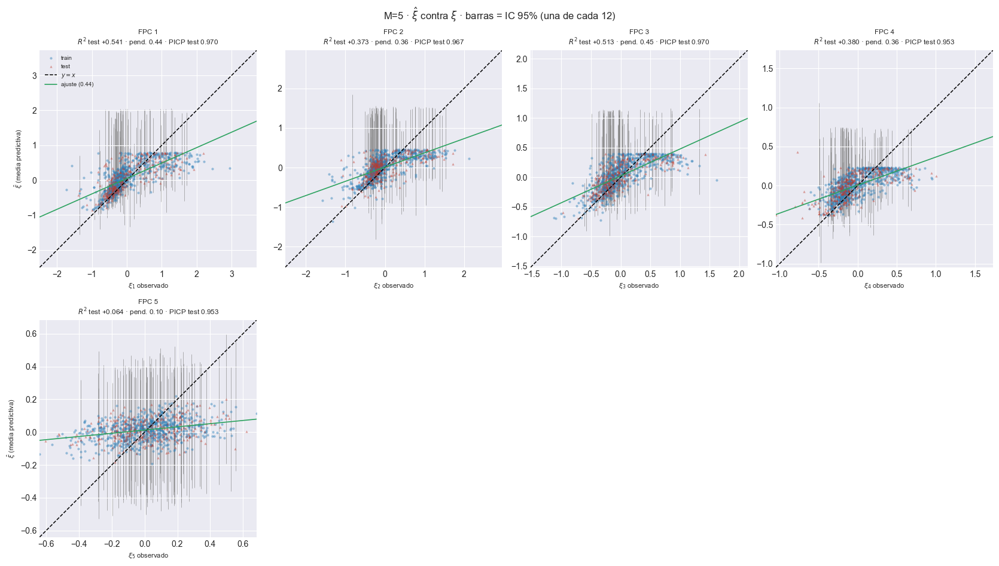

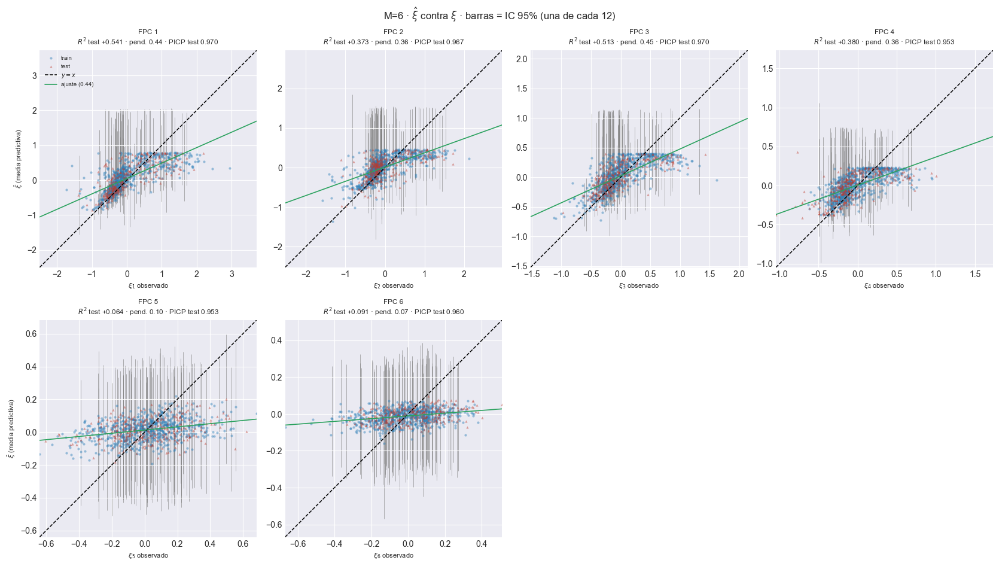

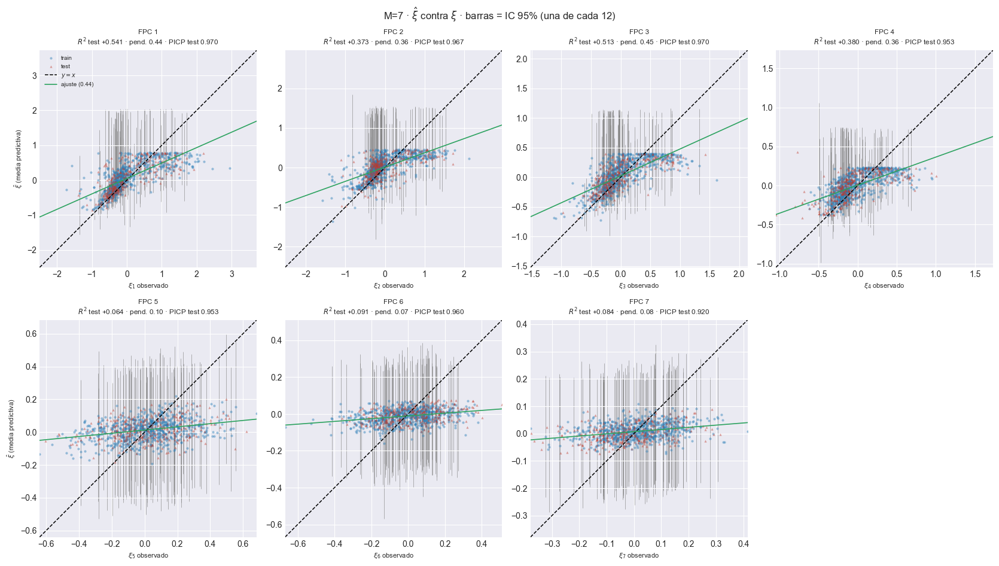

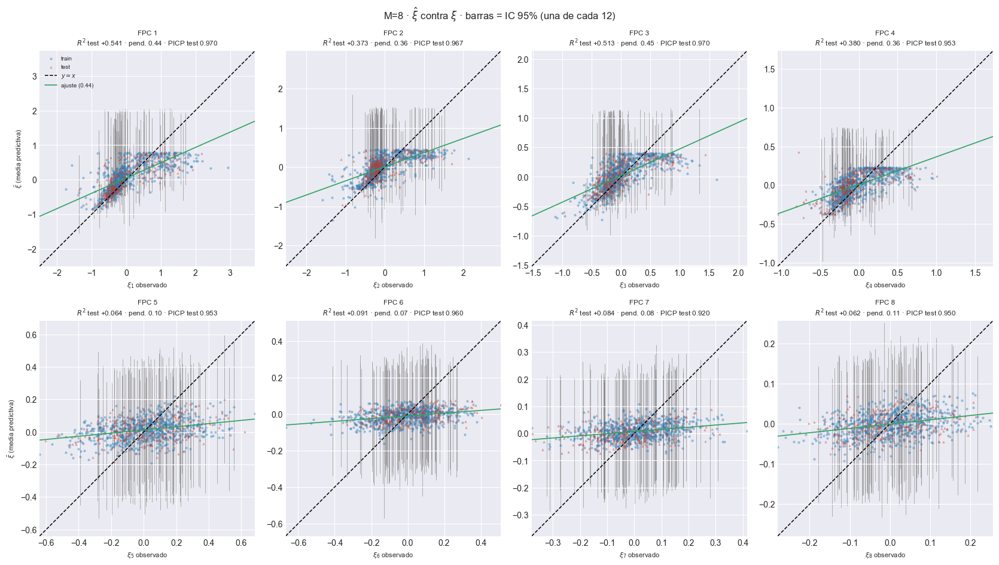

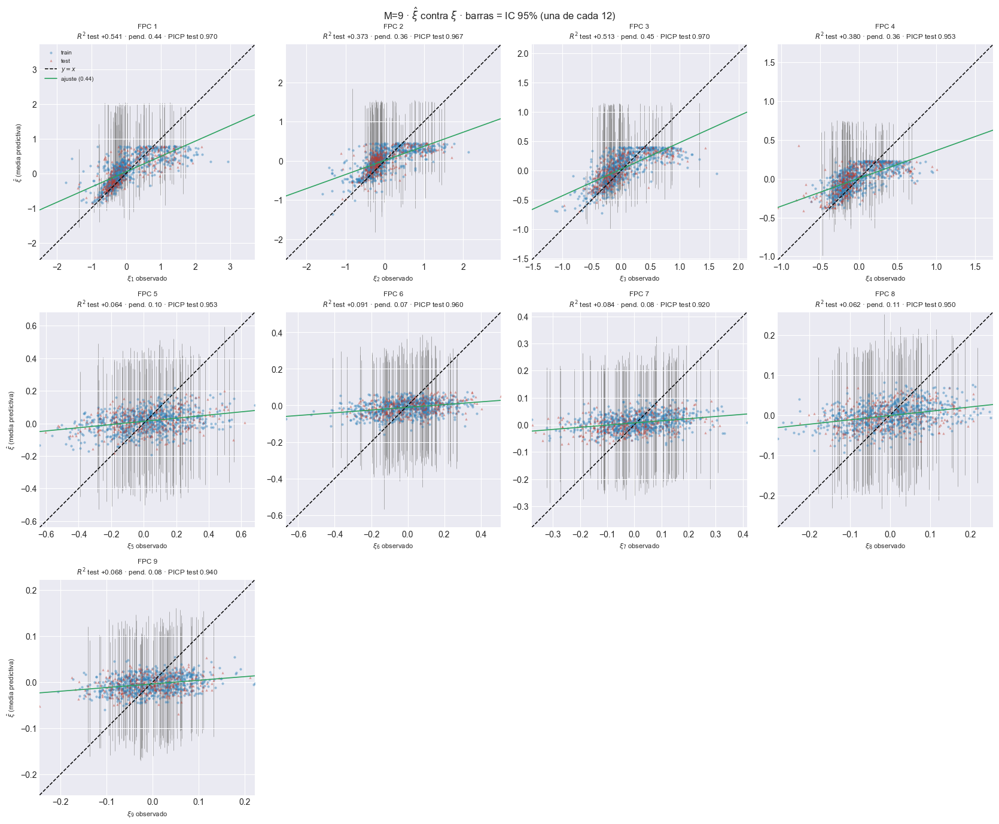

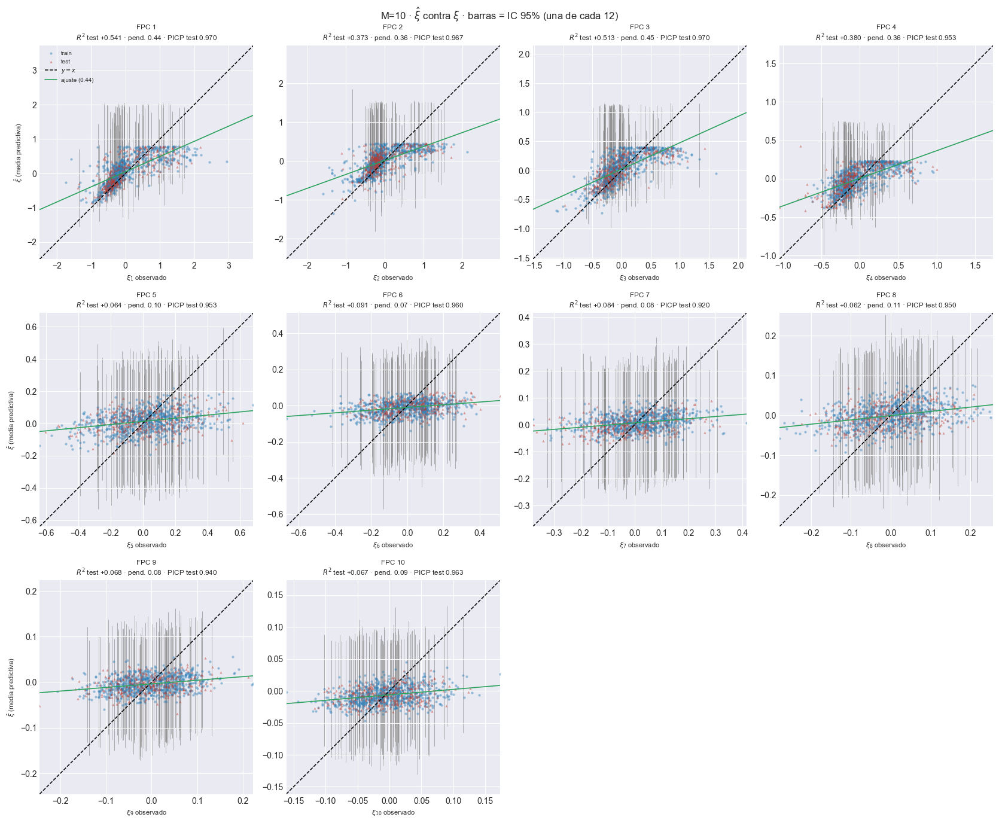

In [20]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()